<a href="https://colab.research.google.com/github/gabrieldiasderesende/Modelagem-de-sistemas-ambientais/blob/codespace-cuddly-space-winner-vprpp4jvxp5rf6gp4/C%C3%B3pia_de_Modelagem_Completa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline de Modelagem Chuva-Vazão

Este notebook orquestra as **3 etapas** do projeto. A lógica de cada etapa está
encapsulada em um módulo `.py` dentro de `SCRIPT_PY/` -- este notebook **só
importa e chama** essas funções, com markdown explicando cada passo:

| Etapa | Módulo | O que faz |
|---|---|---|
| 1. Pré-tratamento | `SCRIPT_PY/Extracao_Pretratamento.py` | Extrai estações/séries de chuva da ANA (em paralelo), MDT da bacia (memory-safe, opcional) e trata falhas |
| 2. Datamining | `SCRIPT_PY/Datamining.py` | Análise exploratória, sazonalidade, correlação, clustering hierárquico e PCA |
| 3. Modelos | `SCRIPT_PY/Modelos.py` | Categorização por percentis, preparo para classificação (lags + LabelEncoder), treino de 18 classificadores e diagnóstico de overfitting |

**Encadeamento de arquivos entre etapas** (cada etapa lê o que a anterior salvou):

```
Pré-tratamento  -->  ENTRADA_EXCEL/df_datamining.xlsx
Datamining      -->  SAIDA/Dataframes/BASES PARA MODELAGEM/df_clusters.xlsx
Modelos         -->  Resultados_Machine_Learning/<nome_modelo>/*.xlsx e *.png
```

Rode as células em ordem. Células marcadas com 🟢 **precisam ser editadas** com
os caminhos/parâmetros do seu caso (bacia, shapefile, usina, número de clusters etc).

**Nota sobre a vazão (Q):** as funções de extração de vazão não fazem parte
deste pipeline (foram descontinuadas nos notebooks originais) -- a coluna
`Q` precisa ser obtida de outra fonte (ex: HidroWeb/ANA para a estação
fluviométrica de interesse) e mesclada manualmente antes de salvar o Excel
de entrada do Datamining (ver seção 1.8).

## Setup 1/3 -- Instalação de dependências

Instala tudo que os 3 módulos (`Extracao_Pretratamento.py`, `Datamining.py`,
`Modelos.py`) usam e que **não** vem pré-instalado no Colab (`geopandas`,
`rasterio`, `zeep`, `catboost` etc.). Os demais (`xgboost`, `lightgbm`,
`plotly`, `folium`, `scikit-learn`, `statsmodels`...) já vêm no Colab, mas
estão listados também para o caso de rodar num ambiente novo/diferente --
o `pip install` não reinstala o que já está satisfeito, então é seguro
rodar sempre.

In [ ]:
%pip install -q zeep requests tqdm tabulate geopandas rasterio shapely folium branca plotly seaborn statsmodels scikit-learn scipy xgboost lightgbm catboost

## Setup 2/3 -- Conectar ao Google Drive e apontar para a pasta do projeto

Monta o Drive (se ainda não estiver montado) e muda o diretório de trabalho
para a pasta raiz do projeto no Drive (se ainda não for o diretório atual) --
é aí que ficam `SCRIPT_PY/`, `shapes_IBGE/`, `ENTRADA_EXCEL/` etc.

🟢 **Edite `PASTA_RAIZ_DRIVE`** se a sua pasta no Drive tiver outro caminho/nome.

In [ ]:
import os

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PASTA_RAIZ_DRIVE = '/content/drive/MyDrive/Modelagem - Chuva Vazao'  # 🟢 edite se necessário

if IN_COLAB:
    from google.colab import drive

    if not os.path.isdir('/content/drive/MyDrive'):
        drive.mount('/content/drive')

    if os.getcwd() != PASTA_RAIZ_DRIVE:
        os.chdir(PASTA_RAIZ_DRIVE)

print("Diretório de trabalho atual:", os.getcwd())

Diretório de trabalho atual: /content/drive/MyDrive/Modelagem - Chuva Vazao


## Setup 3/3 -- sys.path para os módulos do projeto

Adiciona `SCRIPT_PY/` ao `sys.path` para permitir `from Extracao_Pretratamento import ...`,
`from Datamining import ...` e `from Modelos import ...`.

In [ ]:
import sys

caminho_scripts = os.path.abspath(os.path.join('SCRIPT_PY'))
sys.path.append(caminho_scripts)

import pandas as pd

---
# 1. Pré-tratamento

Extração do inventário de estações/bacias da ANA, seleção da bacia de
trabalho, extração paralela das séries de chuva, tratamento de falhas e
(opcionalmente) geração do MDT da bacia.

In [ ]:
from Extracao_Pretratamento import (
    gerar_df_hidro,
    gerar_regiao,
    ler_geodataframe_bacia,
    filtro_estacoes,
    criar_mapa_selecao_interativo,
    filtrar_df_por_selecao_json,
    extrair_chuva_ana_multiplas,
    processar_dicionario_chuva,
    montar_df_datamining,
    plotar_falhas,
    preencher_falhas_vetorizado,
    gerar_mosaico_bacia_streaming,
    plotar_mapa_shapes_light,
)

## 1.1 Inventário de estações e bacias

`gerar_df_hidro` consulta o webservice SOAP da ANA (`HidroInventario` +
`HidroBaciaSubBacia`) e retorna um DataFrame único com as estações e os
dados da(s) sub-bacia(s) informada(s).

🟢 **Edite `codSubBacia`** para o código da sua sub-bacia de interesse.

In [ ]:
df_geo_completo = gerar_df_hidro(codSubBacia=61, telemetrica=0)  # 🟢 edite codSubBacia
df_geo_completo.head()

,BaciaCodigo,SubBaciaCodigo,RioCodigo,RioNome,EstadoCodigo,nmEstado,MunicipioCodigo,nmMunicipio,ResponsavelCodigo,ResponsavelSigla,...,TipoRedeClasseVazao,UltimaAtualizacao,Operando,Descricao,NumImagens,DataIns,DataAlt,codBacia,nmBacia,nmSubBacia
0,6,61,None,None,17,MINAS GERAIS,17701000,UBERABA,1,ANA,...,0,2006-01-18 00:00:00,0,None,0,None,2010-04-28 00:00:00,6,RIO PARANÁ,RIO GRANDE
1,6,61,None,None,17,MINAS GERAIS,17182000,CONQUISTA,1,ANA,...,0,2015-10-13 00:00:00,1,None,0,None,2015-10-13 00:00:00,6,RIO PARANÁ,RIO GRANDE
2,6,61,None,None,17,MINAS GERAIS,17701000,UBERABA,68,DAEE-MG,...,0,2005-07-08 00:00:00,0,None,0,None,2010-04-28 00:00:00,6,RIO PARANÁ,RIO GRANDE
3,6,61,None,None,17,MINAS GERAIS,17701000,UBERABA,57,DEPV,...,0,2005-07-08 00:00:00,1,None,0,None,2010-04-28 00:00:00,6,RIO PARANÁ,RIO GRANDE
4,6,61,None,None,17,MINAS GERAIS,17568000,SACRAMENTO,8,LIGHT,...,0,2005-07-08 00:00:00,0,None,0,None,2010-04-28 00:00:00,6,RIO PARANÁ,RIO GRANDE


## 1.2 Filtrar estações dentro da bacia de trabalho (opcional)

`filtro_estacoes` recorta `df_geo_completo` para manter só as estações cujo
ponto cai dentro da bacia de trabalho. Aceita tanto **.shp** quanto **.bln**
(algumas bacias só têm o contorno em .bln -- a extensão é detectada
automaticamente por `ler_geodataframe_bacia`, chamada internamente).

🟢 **Edite `shapefile_bacia`** para o caminho do shapefile/.bln da sua bacia
(ex: em `shapes_bacia_trabalho/shape_bacia/`). Se o seu .bln não estiver em
lat/lon (EPSG:4326), passe também `input_crs_bln="EPSG:XXXX"`.

In [ ]:
shapefile_bacia = r"shapes_bacia_trabalho/shape_bacia/a_vermelha.bln"  # 🟢 edite -- aceita .shp ou .bln
df_geo = filtro_estacoes(shapefile_bacia, df_postos=df_geo_completo)

Tipos de geometria no arquivo: ['Polygon']
Geometria da bacia é Polígono. Prosseguindo...
Realizando o spatial join...
Total de estações encontradas dentro da bacia: 170


## 1.3 Seleção manual das estações via mapa interativo (opcional)

`criar_mapa_selecao_interativo` gera um HTML com Folium onde é possível
clicar nas estações desejadas e exportar um `estacoes_selecionadas.json`.

🟢 **Edite `usina_coords`** para as coordenadas (latitude, longitude) da usina/ponto de interesse.

In [ ]:
criar_mapa_selecao_interativo(
    shapefile_bacia,
    df_geo,
    usina_coords=(-19.866, -50.345),  # 🟢 edite (lat, lon) da usina
    output_filename="mapa_usina.html"
)

--- Iniciando a criação do mapa: mapa_usina.html ---
Carregando shapefile da bacia de: shapes_bacia_trabalho/shape_bacia/a_vermelha.bln
Dados geográficos prontos.
Adicionando 170 estações selecionáveis ao mapa...
Adicionando marcador da usina.


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore



Sucesso! Mapa interativo salvo como: mapa_usina.html
Abra este arquivo HTML em seu navegador para usar a seleção interativa.


Abra `mapa_usina.html` no navegador, selecione as estações e exporte o
JSON. Depois, rode a célula abaixo para filtrar `df_geo` pela seleção feita.
**Pule esta e a célula anterior se preferir usar todas as estações dentro da bacia.**

In [ ]:
df_geo = filtrar_df_por_selecao_json(df_geo, "estacoes_selecionadas.json")

## 1.4 Extração paralela das séries de chuva

`extrair_chuva_ana_multiplas` extrai a série histórica de cada estação
pluviométrica **em paralelo** (thread pool), já que cada chamada é uma
requisição SOAP independente ao webservice da ANA (I/O-bound).

`max_workers` controla quantas requisições simultâneas são feitas -- comece
conservador (5) e aumente se o servidor da ANA aguentar sem erros/timeouts.

In [ ]:
resultados_chuva = extrair_chuva_ana_multiplas(df_geo, nivel_consistencia=[1, 2], max_workers=5)

108 estações pluviométricas a extrair (max_workers=5).


Extraindo chuva ANA:   1%|          | 1/108 [00:43<1:17:36, 43.51s/it]

✅ Dados extraídos com sucesso para 1949001
✅ Dados extraídos com sucesso para 1949007
✅ Dados extraídos com sucesso para 1949000
✅ Dados extraídos com sucesso para 1949005


Extraindo chuva ANA:   5%|▍         | 5/108 [00:51<13:59,  8.15s/it]  

✅ Dados extraídos com sucesso para 1949004
Nenhuma coluna 'NivelConsistencia' nos dados retornados da estação 1949008 (nível 1).
Nenhuma coluna 'NivelConsistencia' nos dados retornados da estação 1949011 (nível 1).
Nenhuma coluna 'NivelConsistencia' nos dados retornados da estação 1949013 (nível 1).


Extraindo chuva ANA:   7%|▋         | 8/108 [01:04<09:25,  5.66s/it]

... (177 outputs left out)

Extraindo chuva ANA:  99%|█████████▉| 107/108 [04:31<00:02,  2.05s/it]

✅ Dados extraídos com sucesso para 2149061


Extraindo chuva ANA: 100%|██████████| 108/108 [04:33<00:00,  2.53s/it]

✅ Dados extraídos com sucesso para 2149003


## 1.5 Consolidação das séries

`processar_dicionario_chuva` resolve duplicatas de data priorizando o nível
de consistência 2 sobre o 1. `montar_df_datamining` junta todas as estações
em um único DataFrame (datas nas linhas, estações nas colunas).

In [ ]:
resultados_chuva_tratados = processar_dicionario_chuva(resultados_chuva)
df_datamining_chuva = montar_df_datamining(resultados_chuva_tratados)

Iniciando o processamento do dicionário de chuvas...
  - Processando estação: 1949001 (15310 linhas)
  - Concluído. Estação com 15310 linhas após tratamento.
  - Processando estação: 1949007 (24563 linhas)
  - Concluído. Estação com 16040 linhas após tratamento.
  - Processando estação: 1949000 (24289 linhas)
  - Concluído. Estação com 15978 linhas após tratamento.
  - Processando estação: 1949005 (30257 linhas)
  - Concluído. Estação com 19207 linhas após tratamento.
  - Processando estação: 1949004 (47393 linhas)
  - Concluído. Estação com 27455 linhas após tratamento.
  - Processando estação: 1949010 (6149 linhas)
  - Concluído. Estação com 6149 linhas após tratamento.
  - Processando estação: 1950001 (11234 linhas)
  - Concluído. Estação com 11234 linhas após tratamento.
  - Processando estação: 1950000 (29617 linhas)
  - Concluído. Estação com 18567 linhas após tratamento.
  - Processando estação: 1950002 (15313 linhas)
  - Concluído. Estação com 15313 linhas após tratamento.
  - 

In [ ]:
def plotar_quantidade_dados_por_dia(resultados):
    """
    Plota um gráfico interativo com:
    - Quantidade de dados por dia com NivelConsistencia = 1 e = 2
    - Quantidade de valores vazios por dia (linha vermelha)
    - Eixos Y duplos e título com número de estações
    """

    import pandas as pd
    import plotly.graph_objects as go

    # Combina todos os DataFrames do dicionário
    df_tudo = pd.concat(resultados.values(), ignore_index=True)

    # # Exemplo da lista de estações que você quer manter:
    # estacoes_selecionadas = ['58033000', '58030000', '58035000']

    # # Filtra o DataFrame mantendo só as linhas cujo EstacaoCodigo está na lista
    # df_tudo = df_tudo[df_tudo['EstacaoCodigo'].astype(str).isin(estacoes_selecionadas)]

    # Garante que a coluna 'Data' esteja no tipo datetime
    df_tudo['Data'] = pd.to_datetime(df_tudo['Data'])

    # Cria coluna para marcar vazios
    df_tudo['Vazio'] = df_tudo['Chuva'].isna()

    # Agrupamento: contagem por Data e NivelConsistencia
    contagem = (
        df_tudo.groupby(['Data', 'NivelConsistencia'])
        .size()
        .unstack(fill_value=0)
    )
    contagem.columns = [f'Nível {col}' for col in contagem.columns]

    # Agrupamento: contagem de vazios por data
    vazios_por_data = df_tudo[df_tudo['Vazio']].groupby('Data').size()

    # Número total de estações
    total_postos = len(resultados)
    # total_postos = len(estacoes_selecionadas)

    # Criar figura
    fig = go.Figure()

    # Linha para Nível 1
    fig.add_trace(go.Scatter(
        x=contagem.index,
        y=contagem.get('Nível 1', [0]*len(contagem)),
        mode='lines',
        name='Nível 1',
        line=dict(color='blue', dash='dot'),
        yaxis='y1'
    ))

    # Linha para Nível 2
    fig.add_trace(go.Scatter(
        x=contagem.index,
        y=contagem.get('Nível 2', [0]*len(contagem)),
        mode='lines',
        name='Nível 2',
        line=dict(color='green', dash='dot'),
        yaxis='y2'
    ))

    # Linha para vazios
    fig.add_trace(go.Scatter(
        x=vazios_por_data.index,
        y=vazios_por_data.values,
        mode='lines',
        name='Vazios',
        line=dict(color='red', dash='dot'),
        yaxis='y1'  # Mesmo eixo Y da contagem de dados
    ))

    # # Layout com dois eixos Y e subtítulo
    # fig.update_layout(
    #     title=dict(
    #         text='Quantidade de dados por dia - Níveis de Consistência<br>'
    #              f'<sup>Total de Postos Observados: {total_postos}</sup>',
    #         x=0.5
    #     ),
    #     xaxis=dict(title='Data'),
    #     yaxis=dict(
    #         title='Quantidade (Nível 1 + Vazios)',
    #         titlefont=dict(color='blue'),
    #         tickfont=dict(color='blue'),
    #     ),
    #     yaxis2=dict(
    #         title='Quantidade (Nível 2)',
    #         titlefont=dict(color='green'),
    #         tickfont=dict(color='green'),
    #         overlaying='y',
    #         side='right',
    #     ),
    #     legend=dict(x=0.01, y=0.99),
    #     height=500,
    #     width=1000,
    # )

    fig.update_layout(
    title=dict(
        text='Quantidade de dados por dia - Níveis de Consistência<br>'
             f'<sup>Total de Postos Observados: {total_postos}</sup>',
        x=0.5
    ),
    xaxis=dict(title='Data'),

    yaxis=dict(
        title=dict(text='Quantidade (Nível 1 + Vazios)', font=dict(color='blue')),
        tickfont=dict(color='blue'),
    ),

    yaxis2=dict(
        title=dict(text='Quantidade (Nível 2)', font=dict(color='green')),
        tickfont=dict(color='green'),
        overlaying='y',
        side='right',
    ),

    legend=dict(x=0.01, y=0.99),
    height=500,
    width=1000,
    )


    fig.show()

if __name__ == "__main__":
    plotar_quantidade_dados_por_dia(resultados_chuva)


In [ ]:
df_datamining_filtrado = plotar_falhas(
    df_datamining_chuva,
    '1981-04-01', '1995-04-30',   # 🟢 edite o intervalo
    pct_desejada=0.0002,             # 🟢 edite a tolerância de falhas (5% aqui)
    plotar_mapa=True,
    gerar_df=True
)


Para até 0.0% de falhas:
  - Número de estações com até 0.0% de falhas: 19
  - Número de estações com mais de 0.0% de falhas: 72

DataFrame filtrado gerado com 19 estações.


## 1.6 Análise de falhas e filtragem por tolerância

`plotar_falhas` mostra quantas estações restam para diferentes tolerâncias
de falha no intervalo escolhido, e (com `gerar_df=True`) retorna só as
estações que atendem a `pct_desejada`.

🟢 **Edite o intervalo de datas e `pct_desejada`** conforme seu estudo.

## 1.7 Preenchimento dos vazios remanescentes

`preencher_falhas_vetorizado` preenche os `NaN` restantes com a média das
`n_vizinhos` estações geograficamente mais próximas que têm dado no mesmo dia.

In [ ]:
df_datamining_no_NA = preencher_falhas_vetorizado(df_datamining_filtrado, df_geo, n_vizinhos=3)
df_datamining_no_NA.info()

Iniciando preenchimento vetorizado dos valores ausentes...


Preenchendo linhas: 100%|██████████| 5143/5143 [00:00<00:00, 239902.42it/s]

Preenchimento vetorizado concluído!
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5143 entries, 1981-04-01 to 1995-04-30
Freq: D
Data columns (total 19 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   1949001  5143 non-null   float64
 1   1949005  5143 non-null   float64
 2   1949004  5143 non-null   float64
 3   2048028  5143 non-null   float64
 4   2048026  5143 non-null   float64
 5   2048029  5143 non-null   float64
 6   2049003  5143 non-null   float64
 7   2049006  5143 non-null   float64
 8   2049009  5143 non-null   float64
 9   2049010  5143 non-null   float64
 10  2049015  5143 non-null   float64
 11  2049032  5143 non-null   float64
 12  2049055  5143 non-null   float64
 13  2050004  5143 non-null   float64
 14  2050009  5143 non-null   float64
 15  2148005  5143 non-null   float64
 16  2148015  5143 non-null   float64
 17  2148012  5143 non-null   float64
 18  2148017  5143 non-null   float64
dtypes: float64(19)
memory usage:

## 1.8 Anexar a vazão observada (Q) -- passo manual

Este pipeline extrai apenas **chuva**. A coluna `Q` (vazão observada na
estação fluviométrica/usina de interesse) precisa vir de outra fonte e ser
alinhada ao mesmo índice de datas.

🟢 **Edite esta célula** com a forma como você obtém sua série de vazão.

In [ ]:
# Exemplo (ajuste ao seu caso):
serie_q = pd.read_excel("ENTRADA_EXCEL/Q.xlsx", index_col="Data")["Q"]
df_datamining_no_NA["Q"] = serie_q.reindex(df_datamining_no_NA.index)

## 1.9 Salvar o DataFrame de entrada para o Datamining

Este é o arquivo que a Seção 2 (Datamining) vai ler.

In [ ]:
pasta_saida = "ENTRADA_EXCEL"
os.makedirs(pasta_saida, exist_ok=True)
df_datamining_no_NA.to_excel(os.path.join(pasta_saida, "df_datamining.xlsx"), index=True, index_label="Data")

## 1.10 MDT da bacia (opcional, memory-safe)

`gerar_regiao` localiza a bacia nos shapefiles do IBGE (`shapes_IBGE/`) --
use esse caminho se sua bacia estiver catalogada lá. Se você só tem um
shapefile/.bln próprio da bacia (não catalogado no IBGE), use
`ler_geodataframe_bacia` diretamente (aceita .shp ou .bln) -- veja o
comentário na célula abaixo.

`gerar_mosaico_bacia_streaming` monta o mosaico de elevação (Copernicus DEM
30m) processando **um tile por vez** -- nunca carrega todos os tiles nem o
mosaico completo na RAM de uma só vez (ao contrário do fluxo antigo, que
`rasterio.merge`ava todos os tiles simultaneamente e podia estourar memória
no Colab ou em bacias grandes).

🟢 **Edite o nome da bacia (ou o caminho do seu .shp/.bln).** Pule esta
célula se não precisar do MDT.

/content/drive/MyDrive/Modelagem - Chuva Vazao/SCRIPT_PY/Extracao_Pretratamento.py:386: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



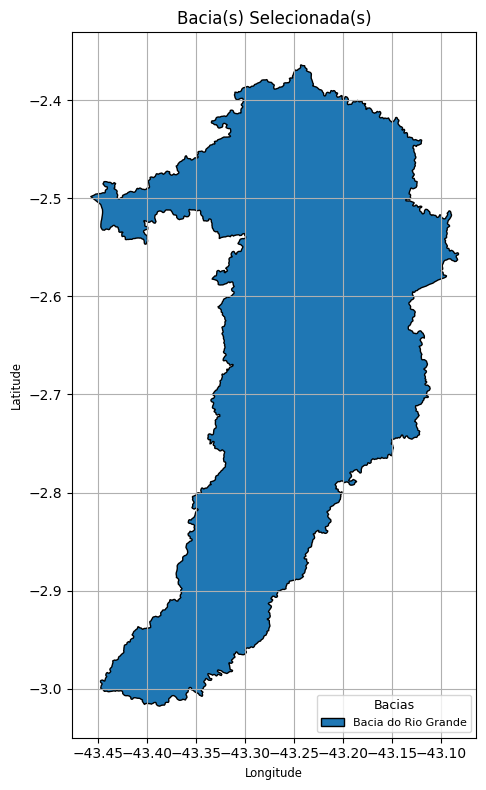

[MDT] Bacia 'Bacia do Rio Grande' (ID 753): 2 tile(s) necessário(s).


Mosaico Bacia_do_Rio_Grande: 100%|██████████| 2/2 [00:01<00:00,  1.94it/s]


[MDT] Raster recortado salvo em: raster_analise/Bacia_do_Rio_Grande/raster_bacia/bacia_753_recorte.tif


In [ ]:
bacias = gerar_regiao("Bacia do Rio Grande", shapes_dir="shapes_IBGE", plotar=True)  # 🟢 edite o nome da bacia
linha = bacias.iloc[0]

# Alternativa se sua bacia não estiver no catálogo do IBGE (aceita .shp OU .bln):
# gdf_bacia_propria = ler_geodataframe_bacia("shapes_bacia_trabalho/shape_bacia/SEU_SHAPE.bln")
# linha_bln = gdf_bacia_propria.iloc[0]
# resultado_mdt = gerar_mosaico_bacia_streaming(linha_bln.geometry, id_bacia=1, nome_bacia=linha_bln["name"])

resultado_mdt = gerar_mosaico_bacia_streaming(linha.geometry, linha["id"], linha["nome_bacia"])

---
# 2. Datamining

Análise exploratória do `df_datamining.xlsx` gerado na Seção 1: séries e
histogramas, sazonalidade, correlação, dissimilaridade, clustering
hierárquico (gera a base usada pela Seção 3) e PCA.

In [ ]:
from Datamining import (
    criar_df,
    plot_series_e_histograma,
    visualizar_sazonalidades,
    fazer_matriz_correlacao,
    fazer_matriz_dissimilaridade,
    cluster_hierarquico_com_media,
    fazer_pca
)

## 2.1 Leitura do DataFrame

🟢 **Edite `colunas`** conforme o intervalo de colunas do seu Excel (formato Excel, ex: `'A:X'`).

In [ ]:
caminho_excel_entrada = r'ENTRADA_EXCEL/df_datamining.xlsx'
caminho_figuras = r'SAIDA/Figuras'
caminho_df_saida = r'SAIDA/Dataframes'
colunas = 'A:U'  # 🟢 edite conforme o número de colunas do seu Excel

df_datamining = criar_df(caminho_excel_entrada, caminho_figuras, caminho_df_saida, colunas)
df_datamining.describe().T

+---------------------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----+
| Data                |   1949001 |   1949005 |   1949004 |   2048028 |   2048026 |   2048029 |   2049003 |   2049006 |   2049009 |   2049010 |   2049015 |   2049032 |   2049055 |   2050004 |   2050009 |   2148005 |   2148015 |   2148012 |   2148017 |   Q |
+=====================+===========+===========+===========+===========+===========+===========+===========+===========+===========+===========+===========+===========+===========+===========+===========+===========+===========+===========+===========+=====+
| 1981-04-01 00:00:00 |       0   |         0 |       0   |       0   |       0   |       0   |       0.2 |       0   |         0 |       0   |       0.2 |         0 |       0.2 |       0   |       0   |       0.2 |         0 

,count,mean,std,min,25%,50%,75%,max
1949001,5143.0,3.712658,10.065795,0.0,0.0,0.0,1.2,131.1
1949005,5143.0,4.102430,11.339930,0.0,0.0,0.0,1.2,178.3
1949004,5143.0,4.019036,10.775777,0.0,0.0,0.0,1.6,146.0
2048028,5143.0,3.763737,10.000188,0.0,0.0,0.0,1.2,108.7
2048026,5143.0,3.948934,10.181208,0.0,0.0,0.0,1.2,121.4
2048029,5143.0,3.890965,10.154083,0.0,0.0,0.0,1.4,129.1
2049003,5143.0,3.843438,10.381477,0.0,0.0,0.0,1.1,159.2
2049006,5143.0,3.822010,10.185355,0.0,0.0,0.0,1.4,136.4
2049009,5143.0,3.764943,10.067078,0.0,0.0,0.0,1.2,149.3
2049010,5143.0,4.545771,10.765544,0.0,0.0,0.1,3.1,129.7


## 2.2 Séries temporais e histogramas

Visualização inicial do comportamento e distribuição de cada série (chuva
por estação + vazão).

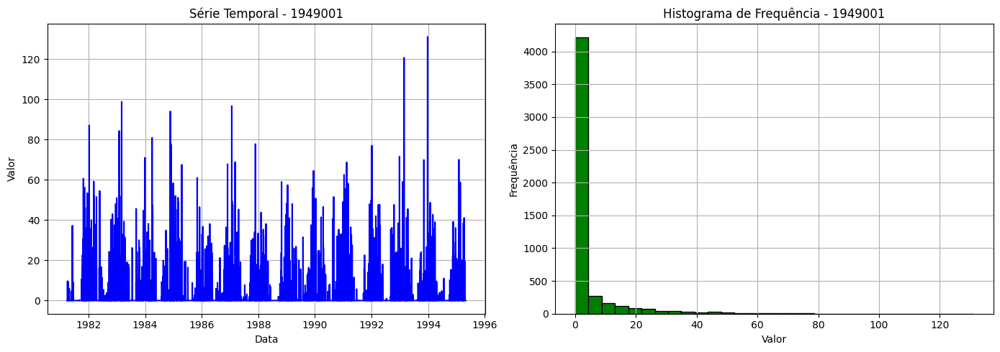

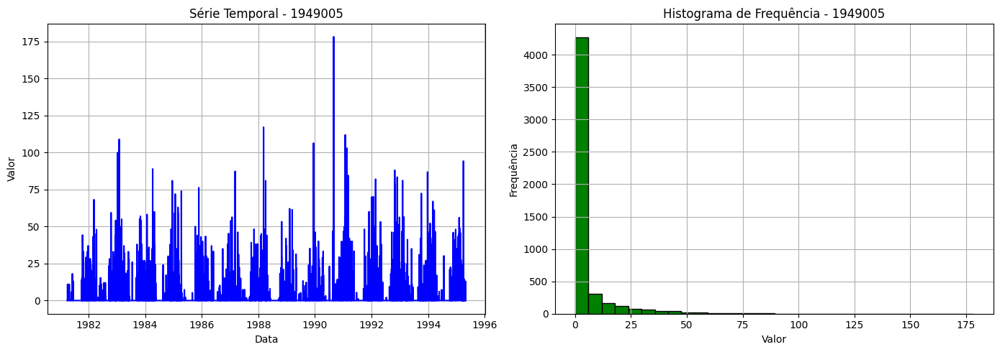

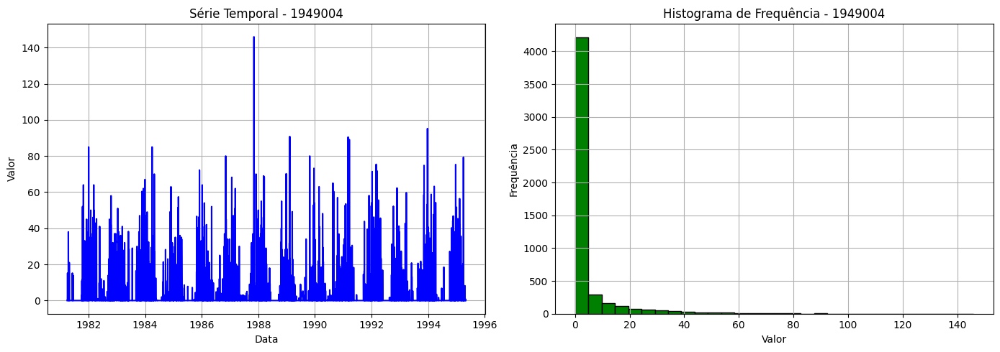

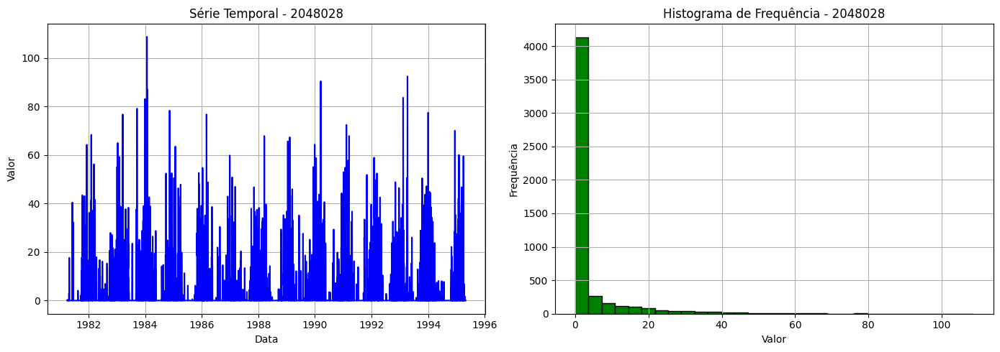

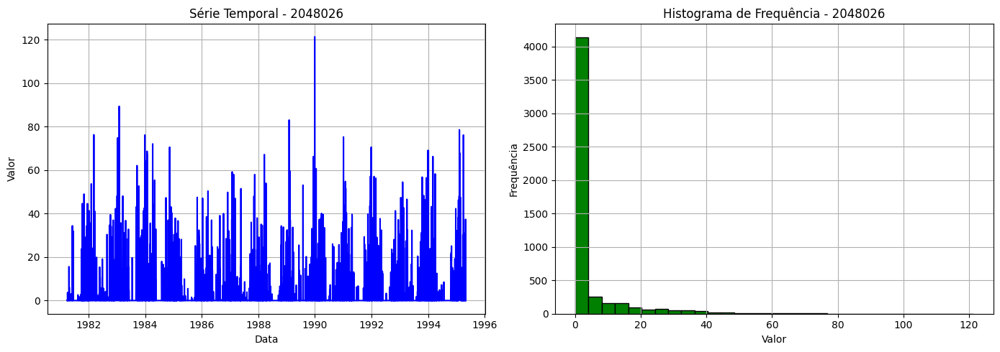

...

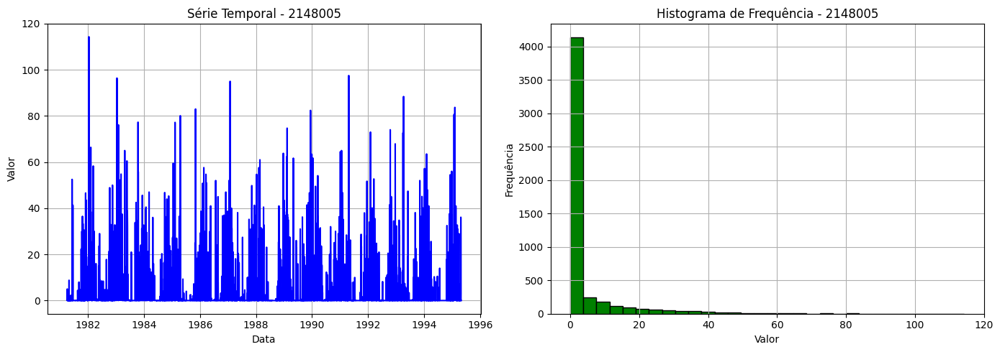

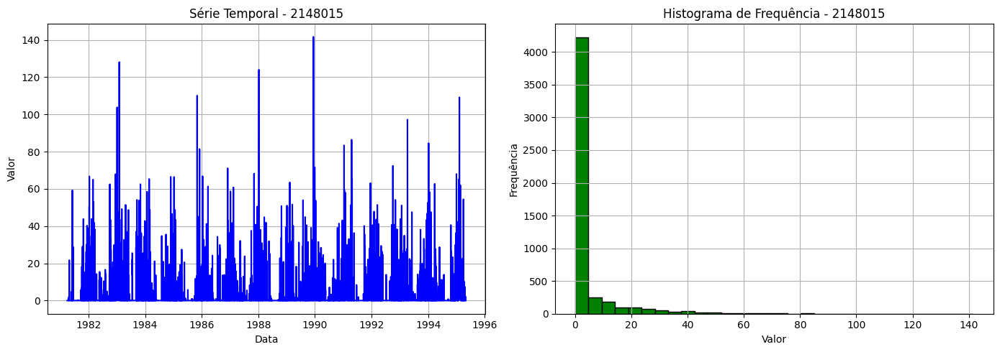

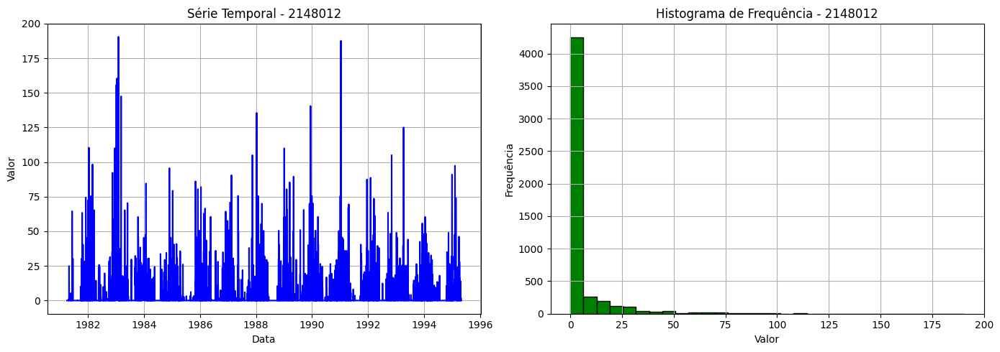

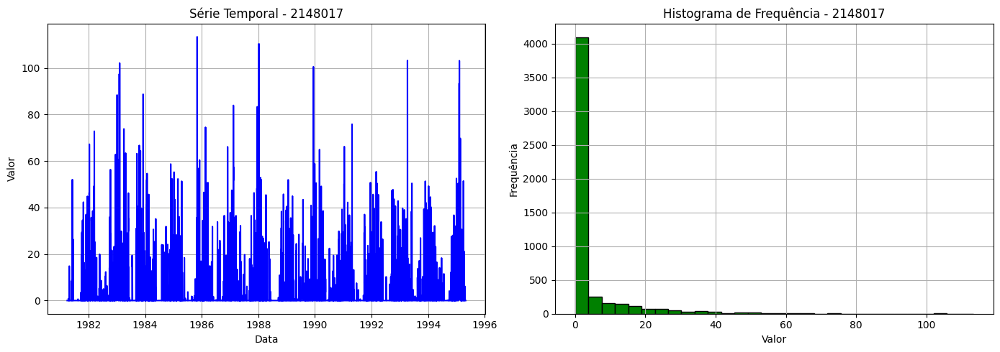

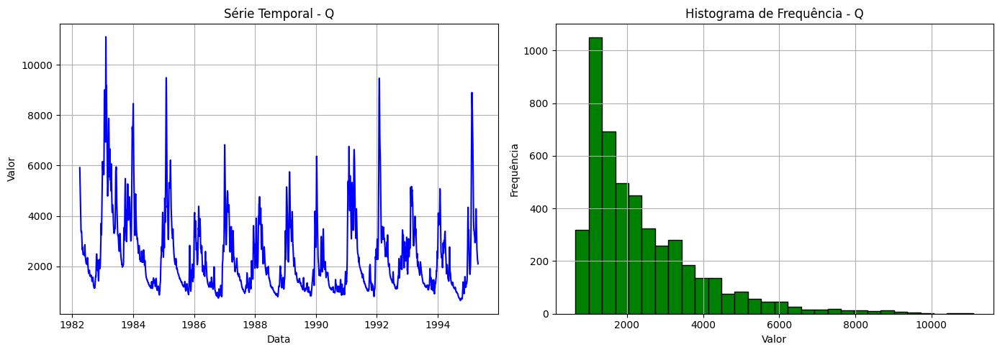

In [ ]:
plot_series_e_histograma(df_datamining, caminho_figuras)

## 2.3 Sazonalidade

Decomposição sazonal (tendência/sazonalidade/resíduo) com médias móveis.

Dados diários mantidos


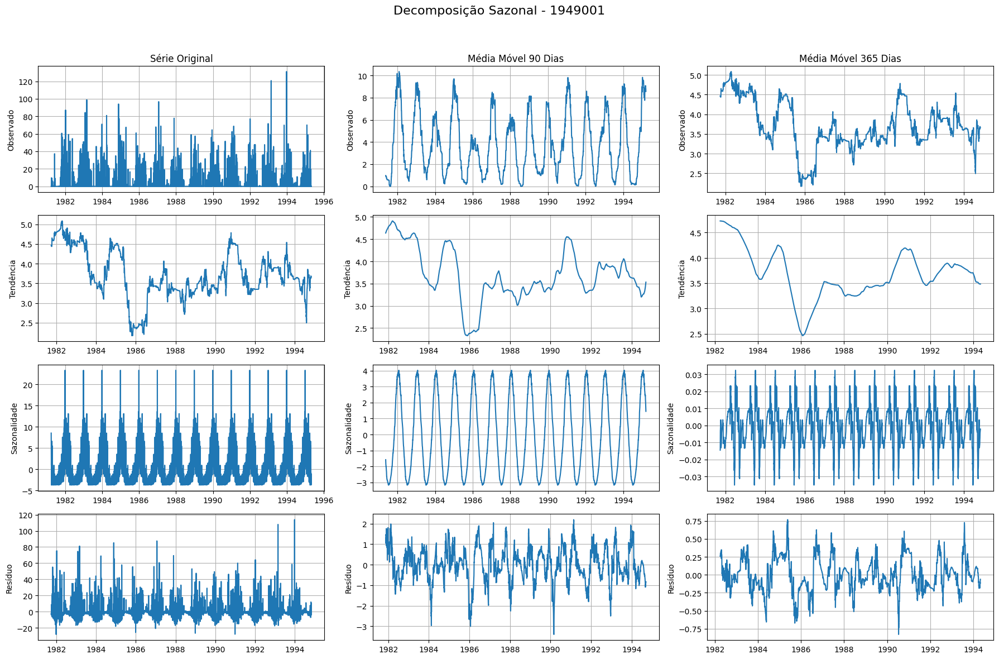

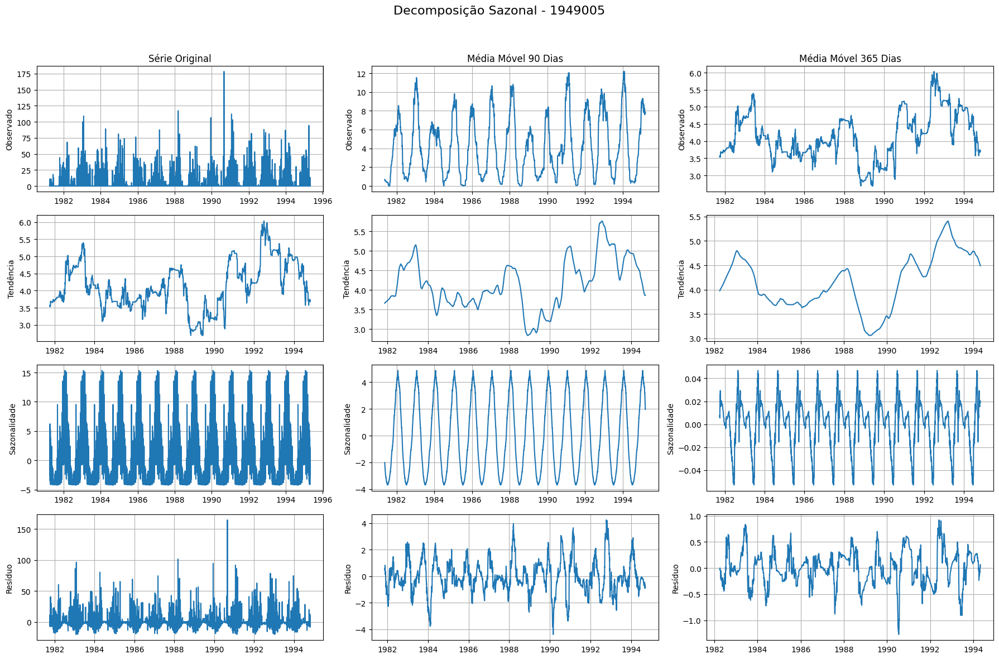

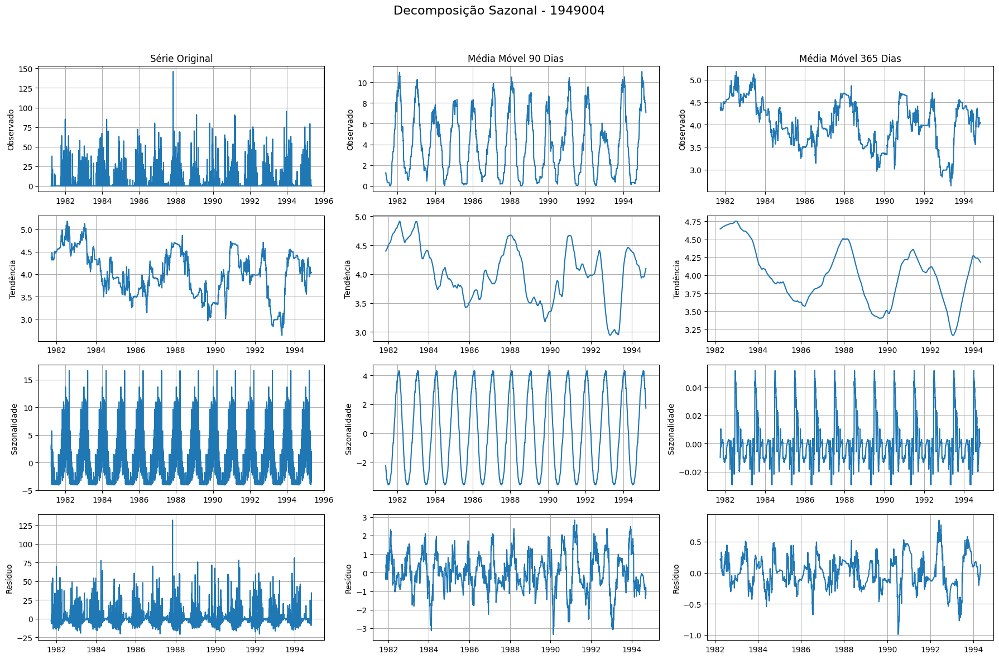

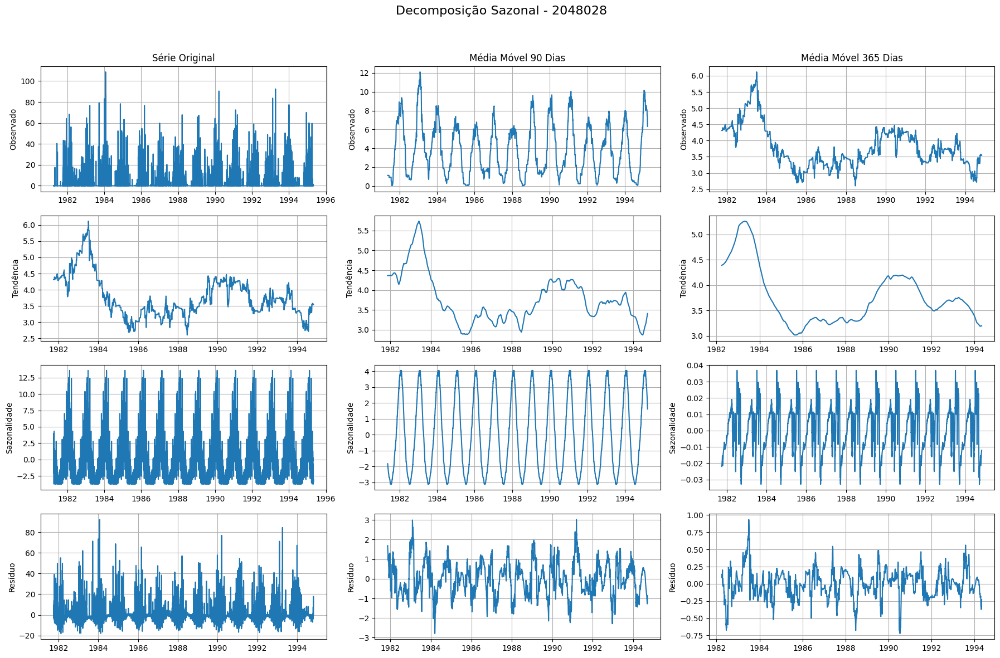

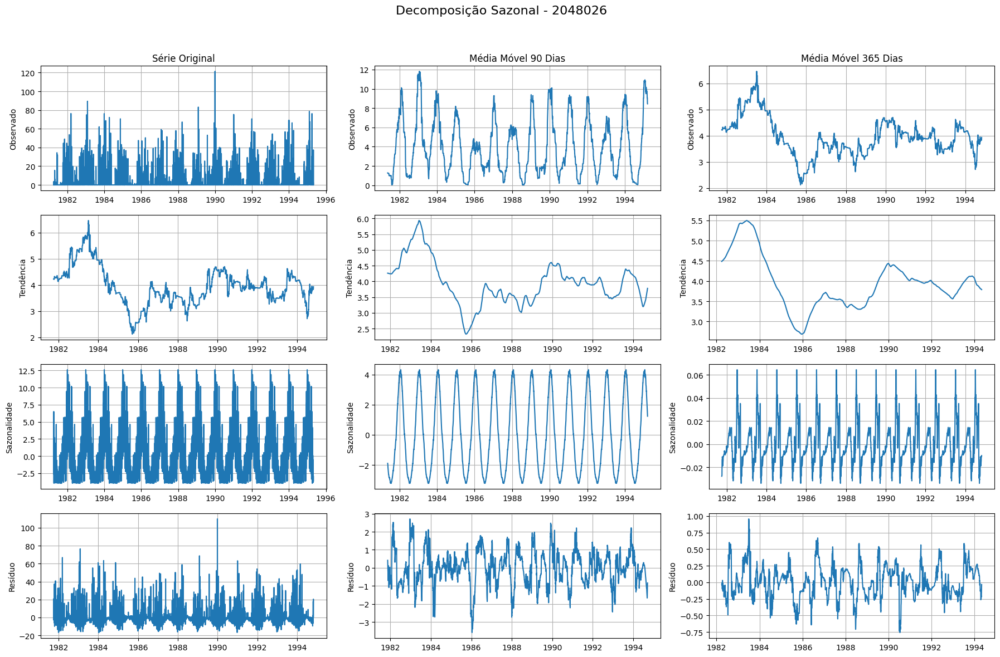

...

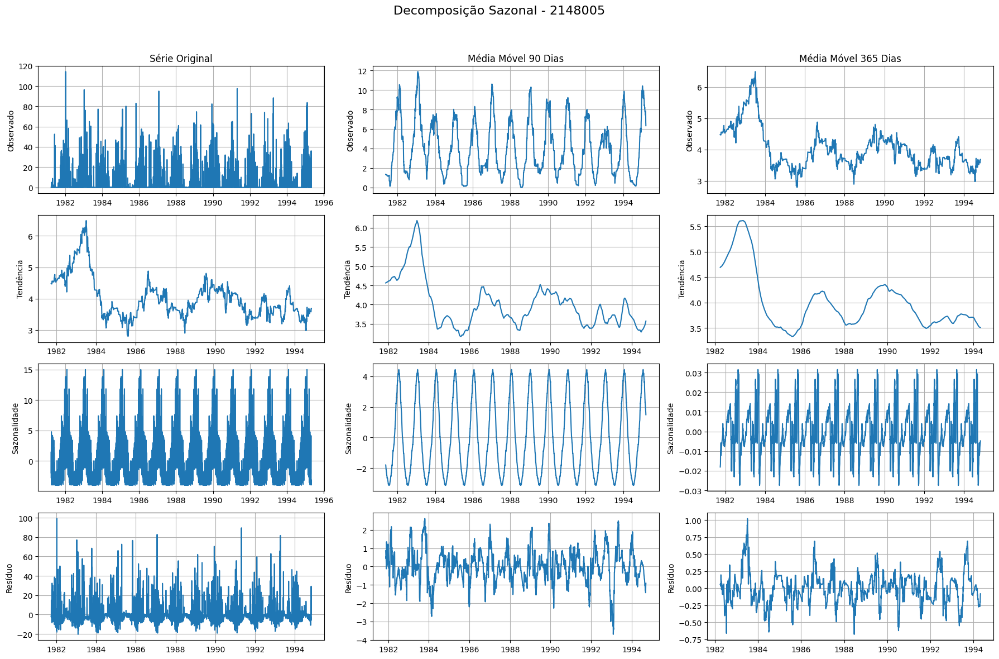

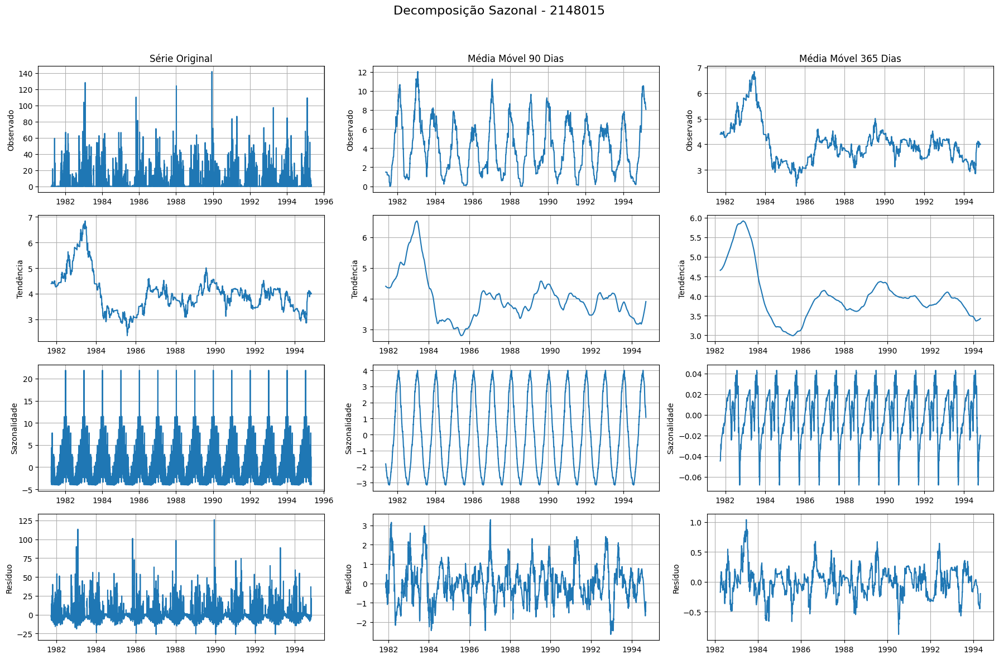

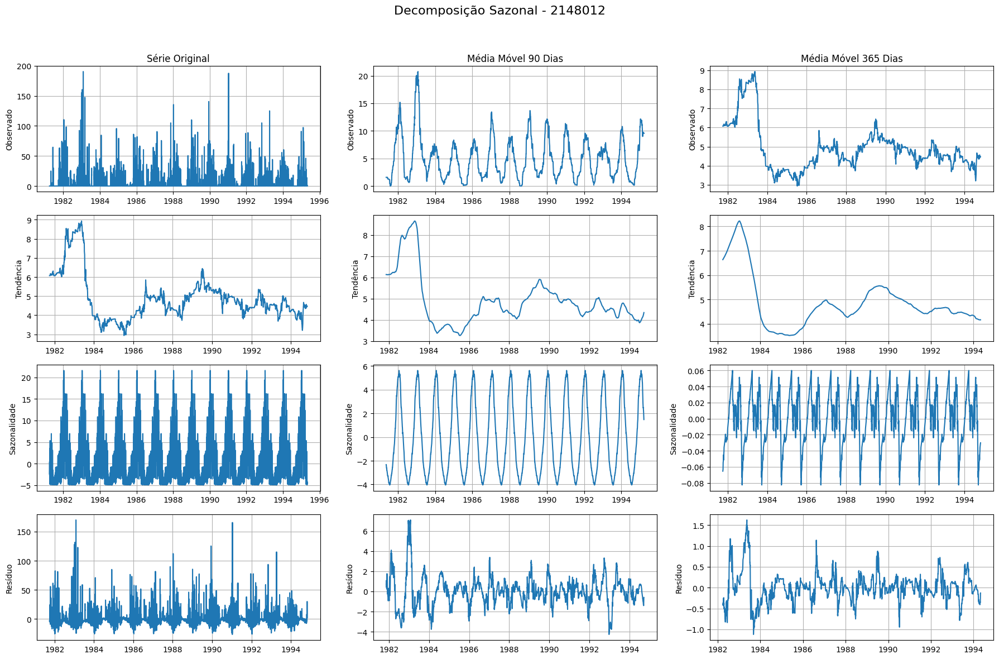

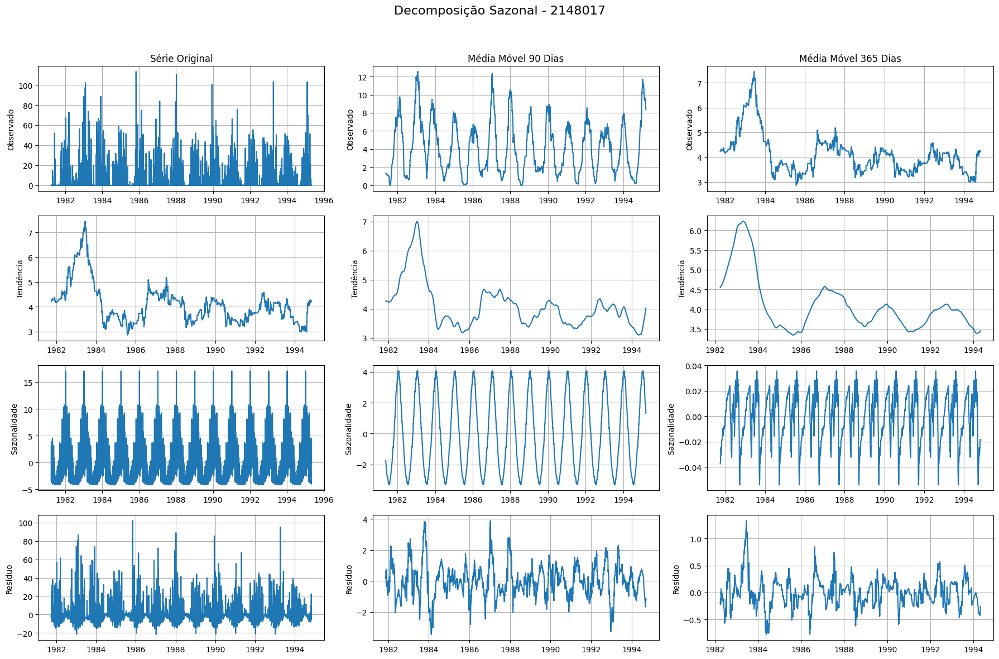

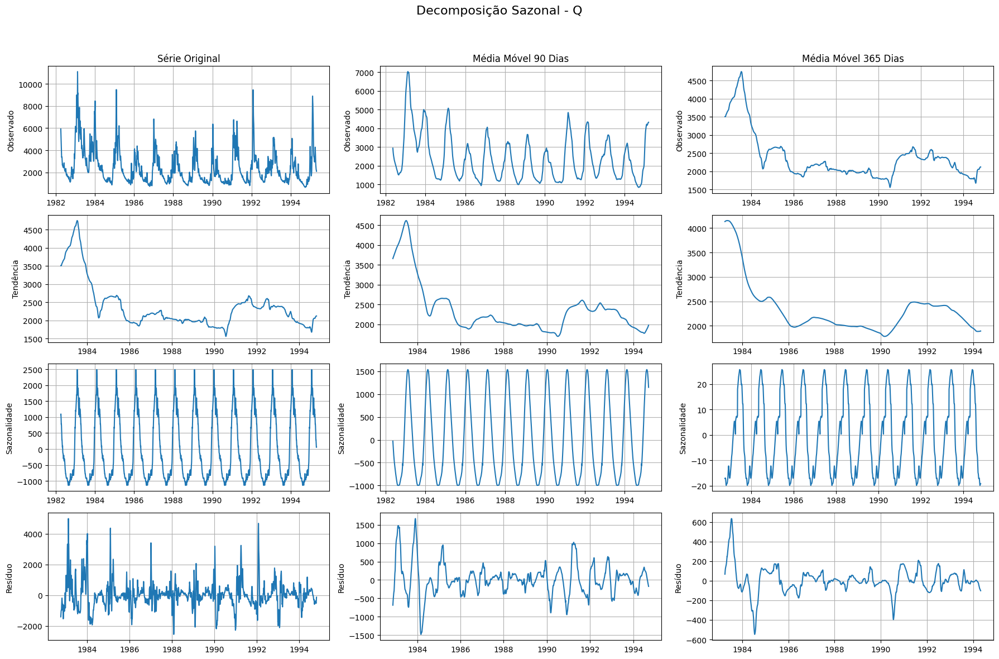

In [ ]:
visualizar_sazonalidades(df_datamining, caminho_figuras, periodo=365, m_movel_1=90, m_movel_2=365, se_diario=True, virar_mensal=False)

## 2.4 Matriz de correlação

Relações lineares entre as séries.

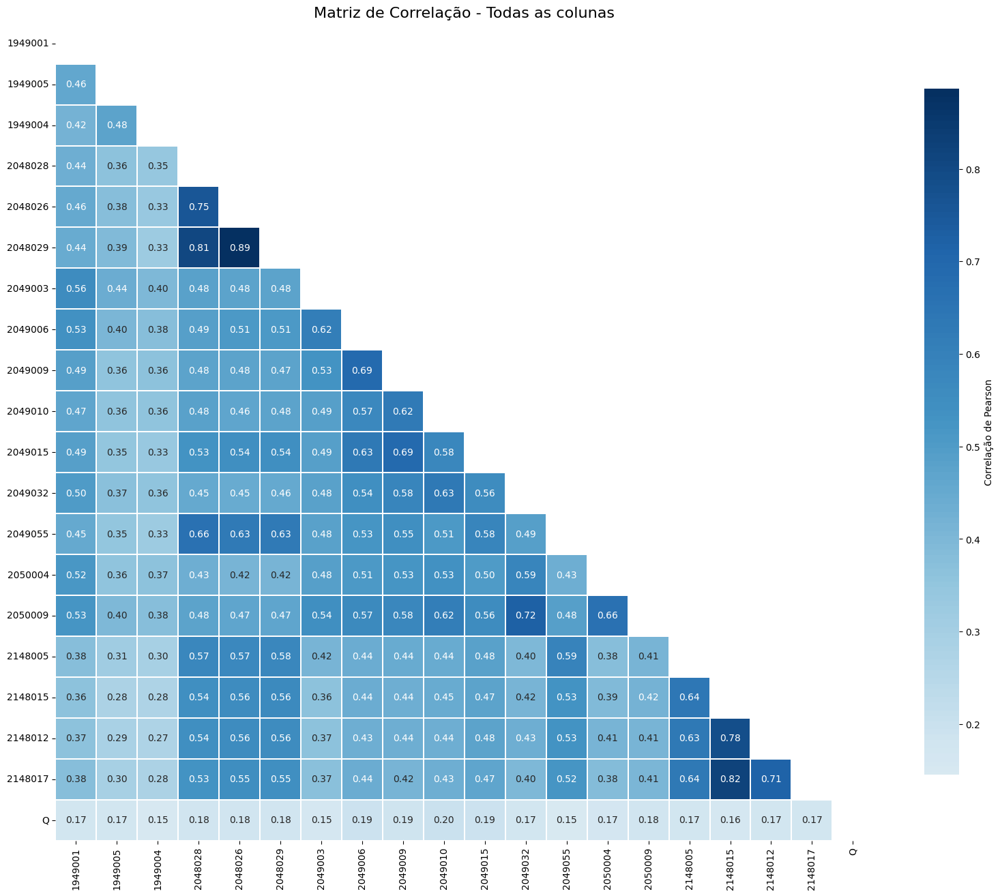

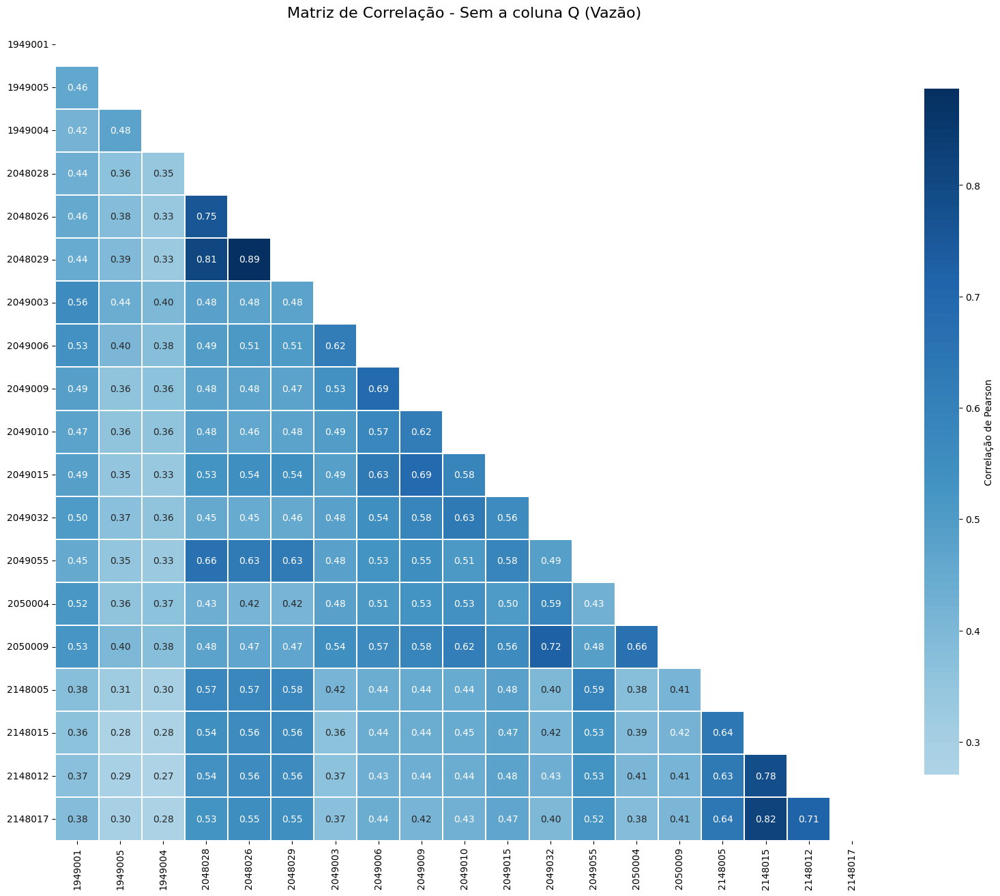

In [ ]:
fazer_matriz_correlacao(df_datamining, caminho_figuras)

## 2.5 Matriz de dissimilaridade

Base para o clustering hierárquico a seguir.

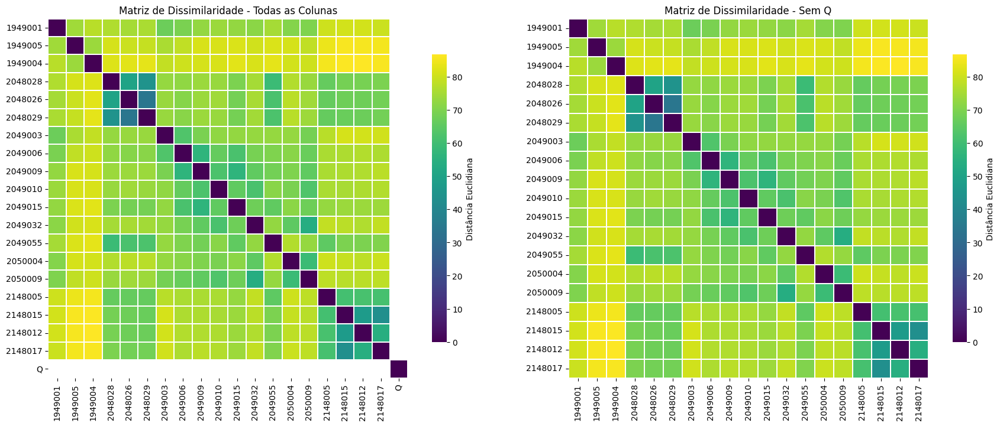

In [ ]:
fazer_matriz_dissimilaridade(df_datamining, caminho_figuras)

## 2.6 Clustering hierárquico

Agrupa estações semelhantes. **Salva `df_clusters.xlsx` em
`SAIDA/Dataframes/BASES PARA MODELAGEM/`, que é o arquivo lido pela Seção 3
(Modelos).**

🟢 **Edite `k`** (número de clusters) conforme sua análise.

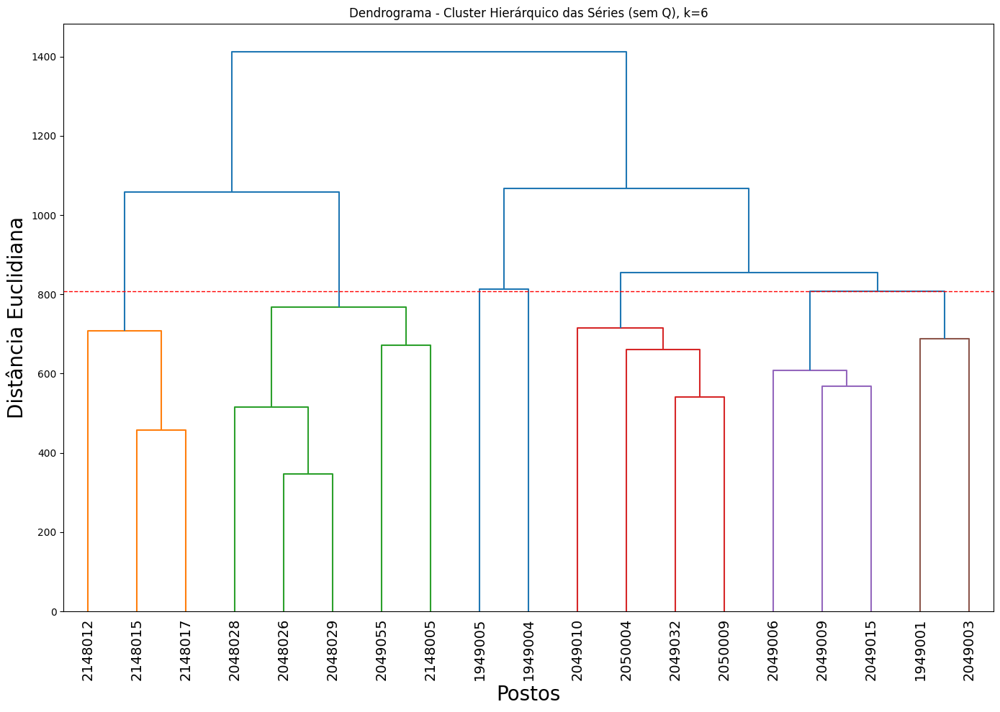


Colunas por cluster:
Cluster 1: ['2148015', '2148012', '2148017']
Cluster 2: ['2048028', '2048026', '2048029', '2049055', '2148005']
Cluster 3: ['1949005']
Cluster 4: ['1949004']
Cluster 5: ['2049010', '2049032', '2050004', '2050009']
Cluster 6: ['1949001', '2049003', '2049006', '2049009', '2049015']


,C1,C2,C3,C4,C5,C6,Q
Data,,,,,,,
1981-04-01,0.0,0.08,0.0,0.0,0.000,0.08,NaN
1981-04-02,0.0,0.06,0.0,0.0,0.000,0.06,NaN
1981-04-03,0.0,0.02,0.0,0.0,0.000,0.06,NaN
1981-04-04,0.0,0.18,0.0,0.0,0.125,1.02,NaN
1981-04-05,0.0,1.06,4.0,5.6,3.800,2.54,NaN
1981-04-06,0.0,1.04,11.0,15.2,1.225,0.04,NaN
1981-04-07,0.0,0.00,0.0,0.0,0.000,0.02,NaN
1981-04-08,0.0,0.00,0.0,0.0,0.000,0.02,NaN
1981-04-09,0.0,0.00,0.0,0.0,0.000,0.00,NaN


In [ ]:
df_clusters = cluster_hierarquico_com_media(
    df_datamining, k=6,  # 🟢 edite o número de clusters
    caminho_figuras=caminho_figuras, caminho_dataframes=caminho_df_saida, plotar=True
)
df_clusters.head(10)

## 2.7 PCA (exploratório)

Redução de dimensionalidade -- não é consumido pela Seção 3, é só para
análise/relatório.

--- INICIANDO ANÁLISE 1: PCA sobre os postos (SEM 'Q') ---

===== INICIANDO ANÁLISE PCA (SEMQ) =====


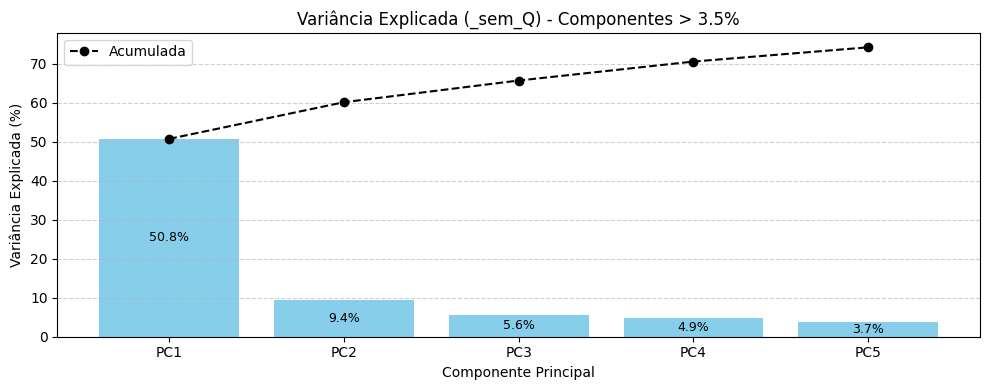

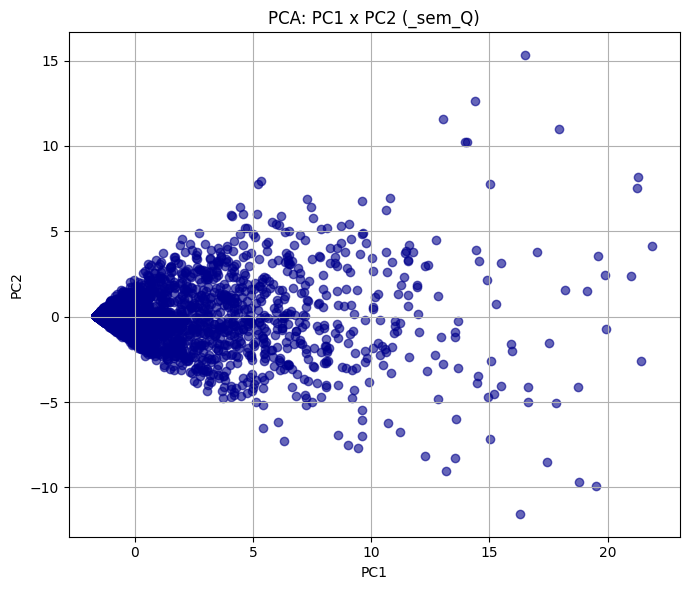

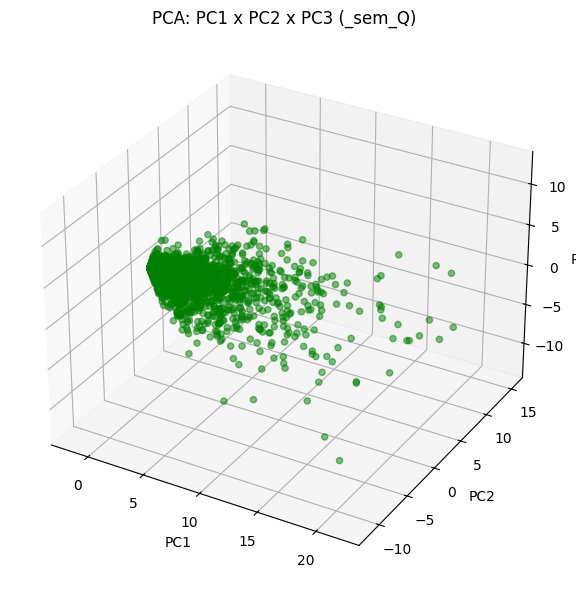

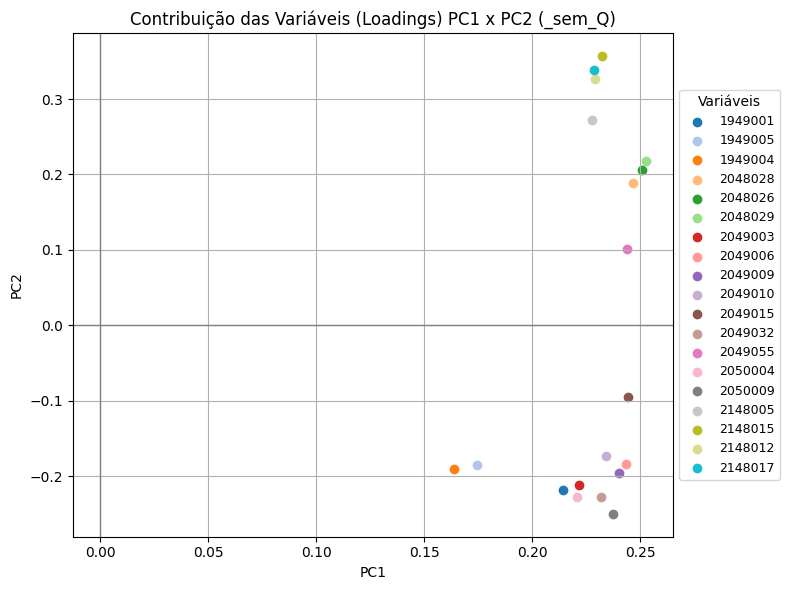

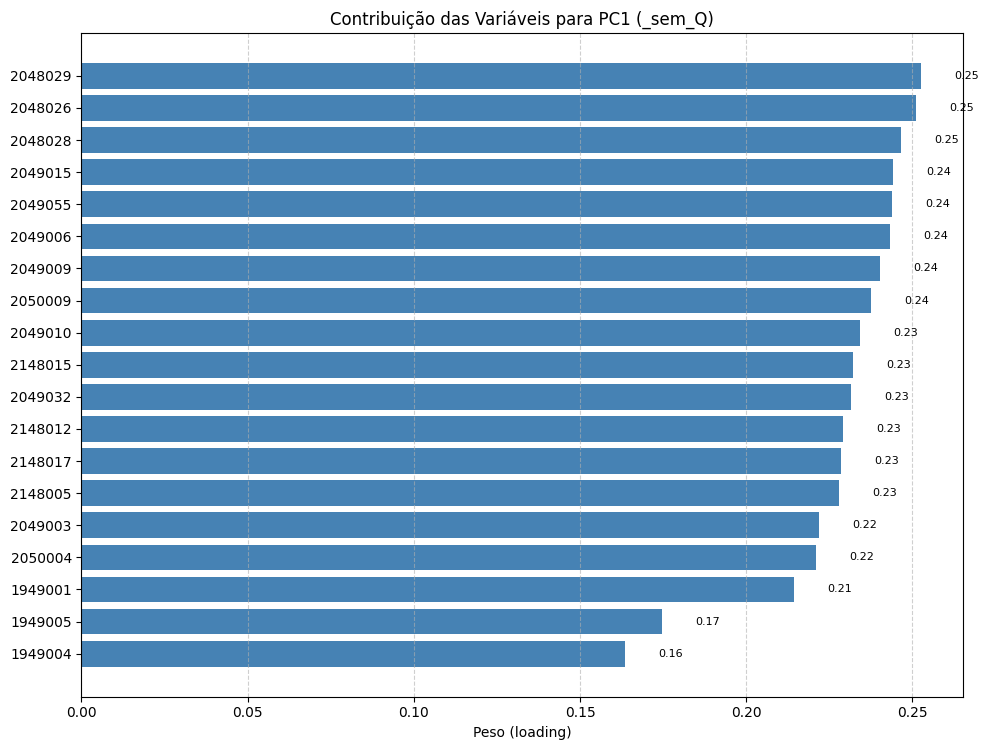

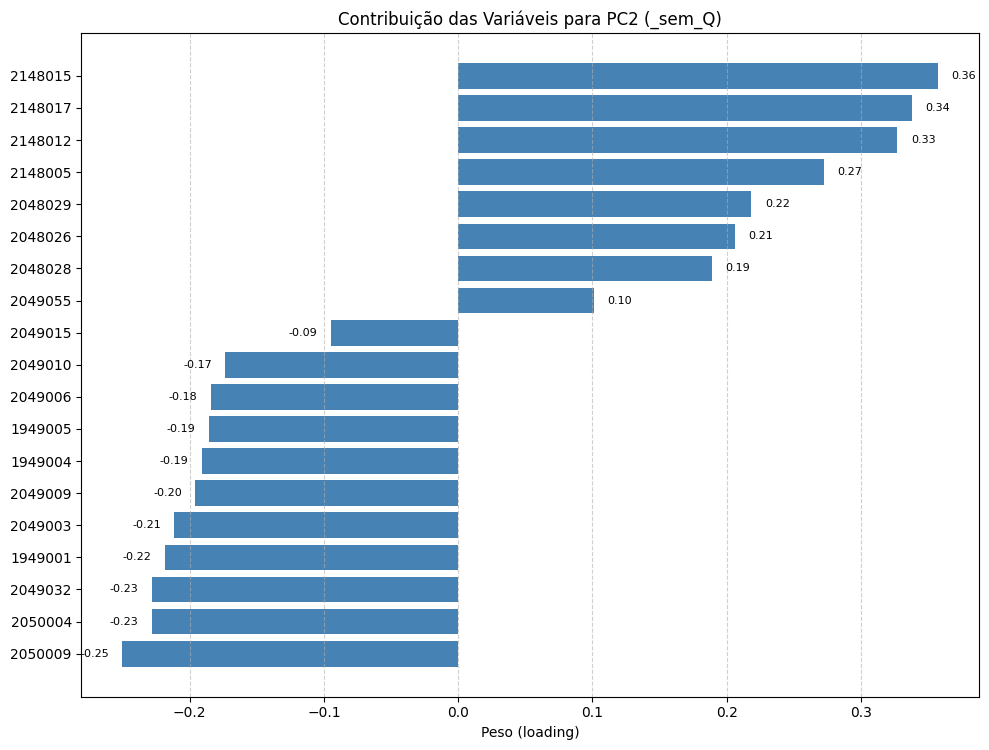

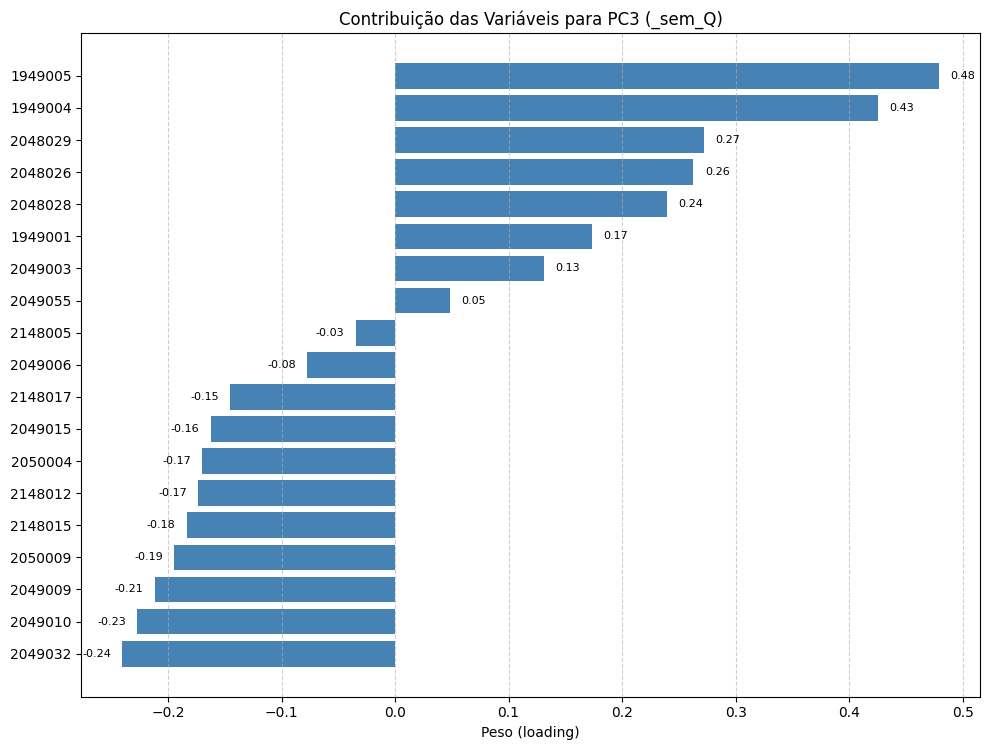

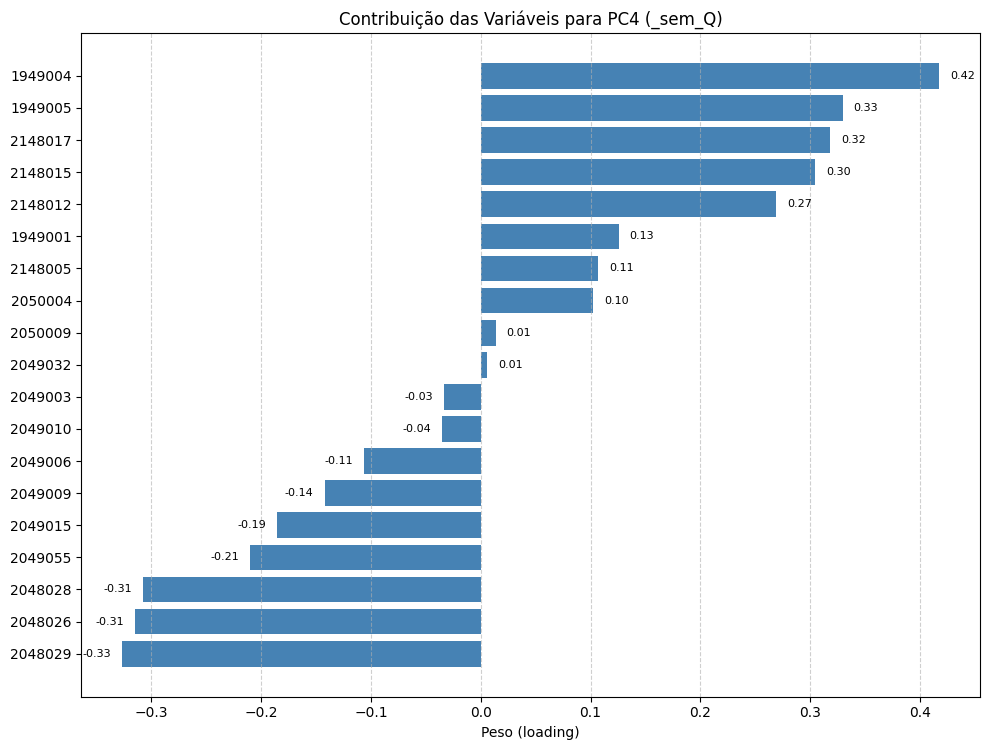

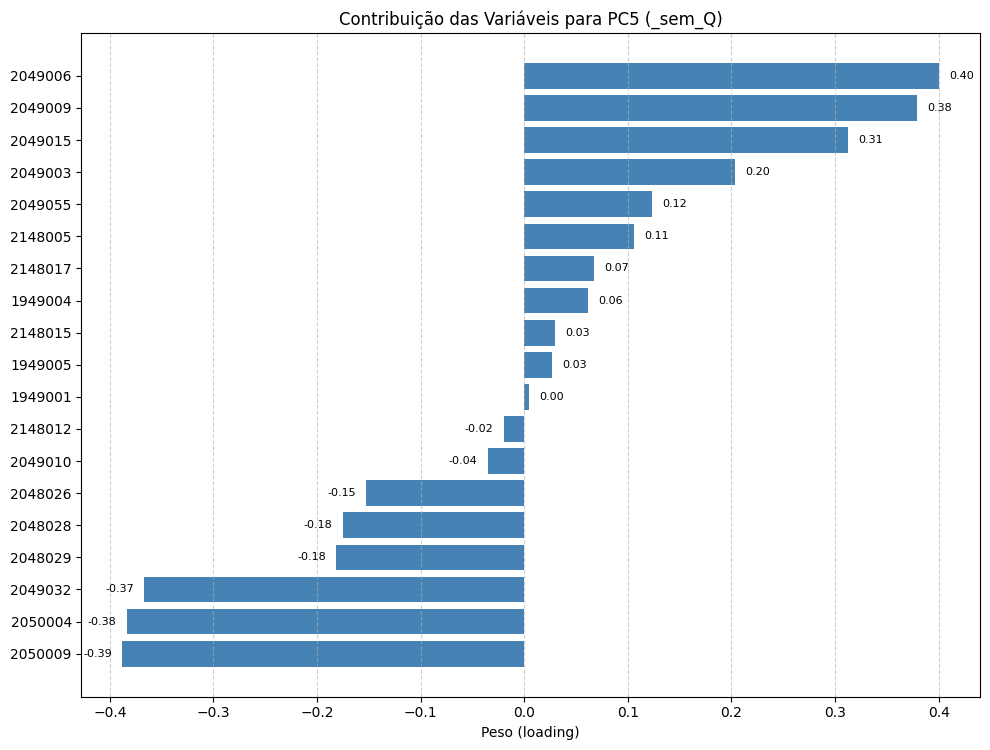


===== Principais Variáveis por Componente (_sem_Q) =====

PC1 - Top 5 Variáveis (Absoluto):
  1. 2048029: +0.253
  2. 2048026: +0.251
  3. 2048028: +0.247
  4. 2049015: +0.244
  5. 2049055: +0.244

PC2 - Top 5 Variáveis (Absoluto):
  1. 2148015: +0.357
  2. 2148017: +0.338
  3. 2148012: +0.327
  4. 2148005: +0.272
  5. 2050009: -0.250

PC3 - Top 5 Variáveis (Absoluto):
  1. 1949005: +0.479
  2. 1949004: +0.425
  3. 2048029: +0.272
  4. 2048026: +0.263
  5. 2049032: -0.240

PC4 - Top 5 Variáveis (Absoluto):
  1. 1949004: +0.418
  2. 1949005: +0.330
  3. 2048029: -0.326
  4. 2148017: +0.318
  5. 2048026: -0.315

PC5 - Top 5 Variáveis (Absoluto):
  1. 2049006: +0.401
  2. 2050009: -0.388
  3. 2050004: -0.383
  4. 2049009: +0.379
  5. 2049032: -0.367
===== ANÁLISE PCA (SEMQ) CONCLUÍDA =====


--- INICIANDO ANÁLISE 2: PCA sobre o sistema completo (COM 'Q') ---

===== INICIANDO ANÁLISE PCA (COMQ) =====


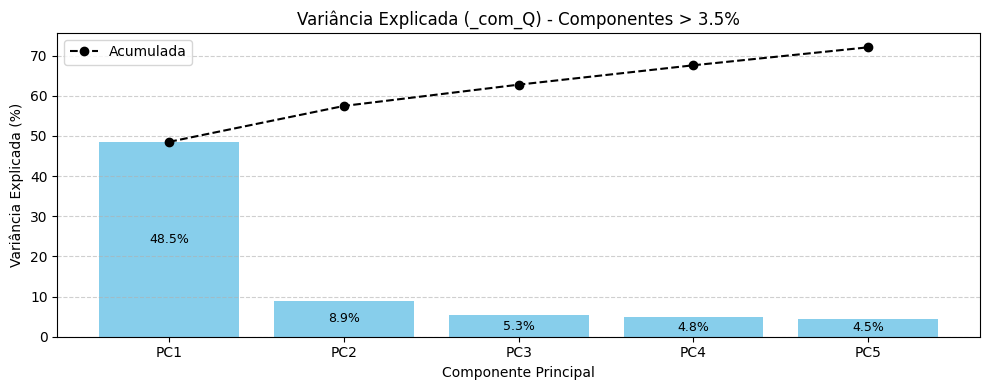

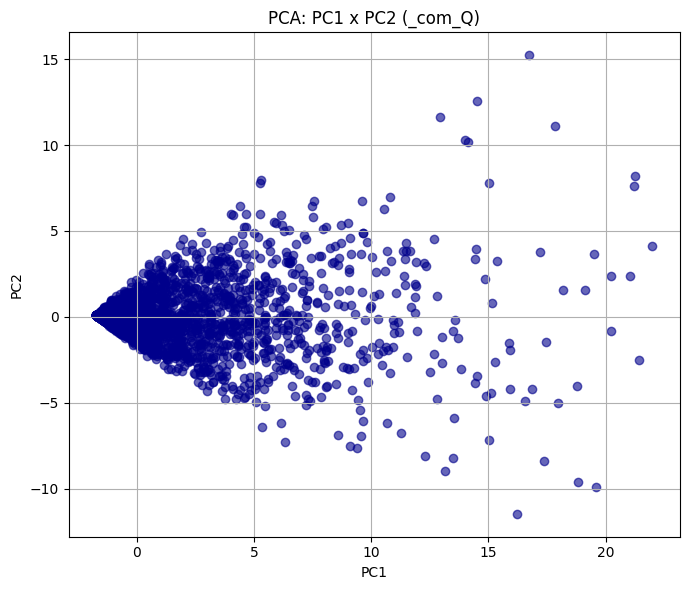

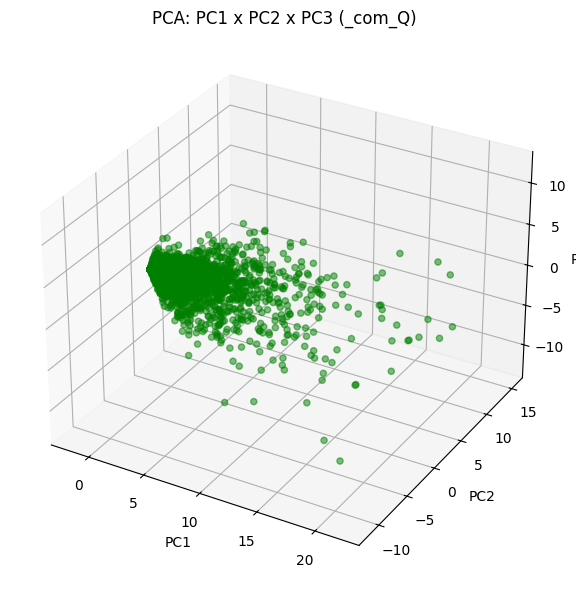

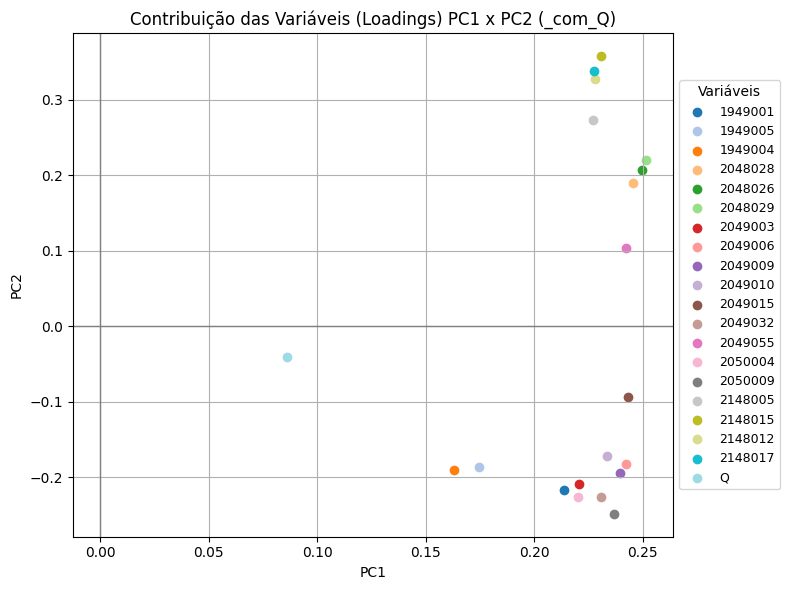

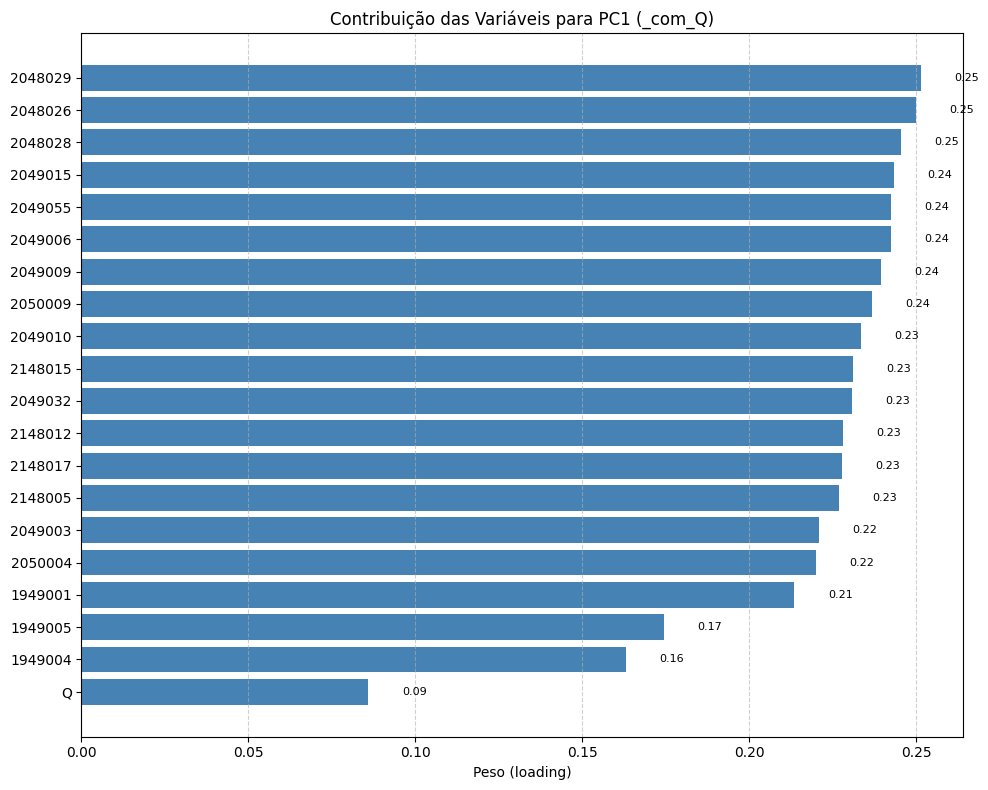

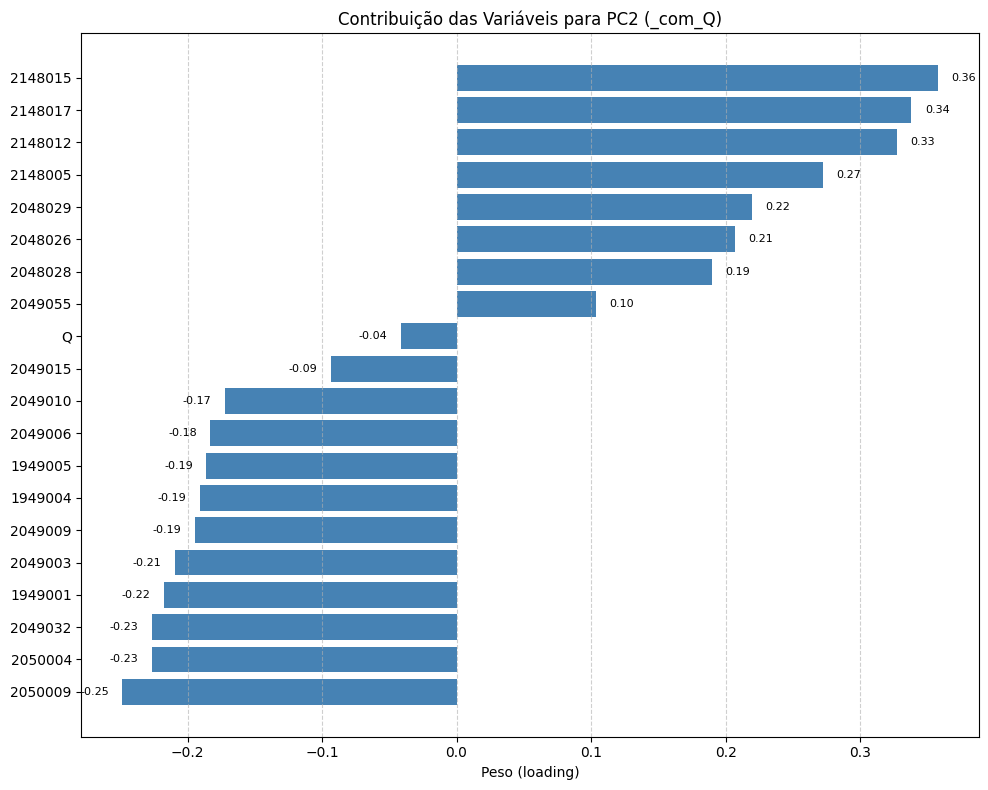

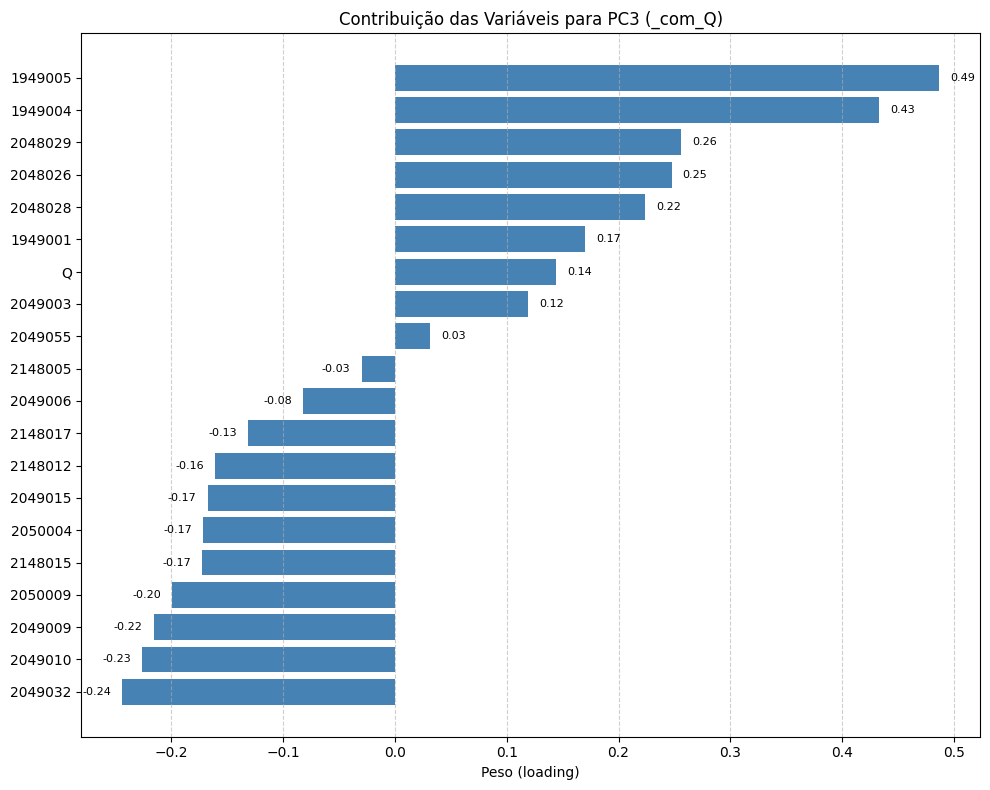

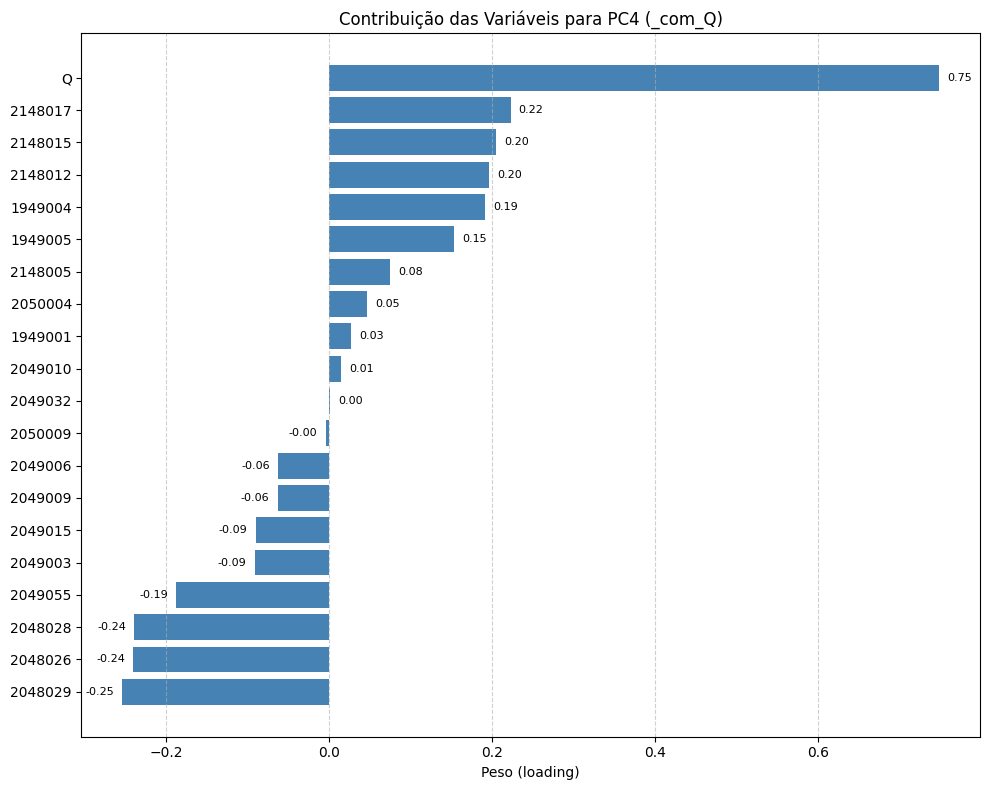

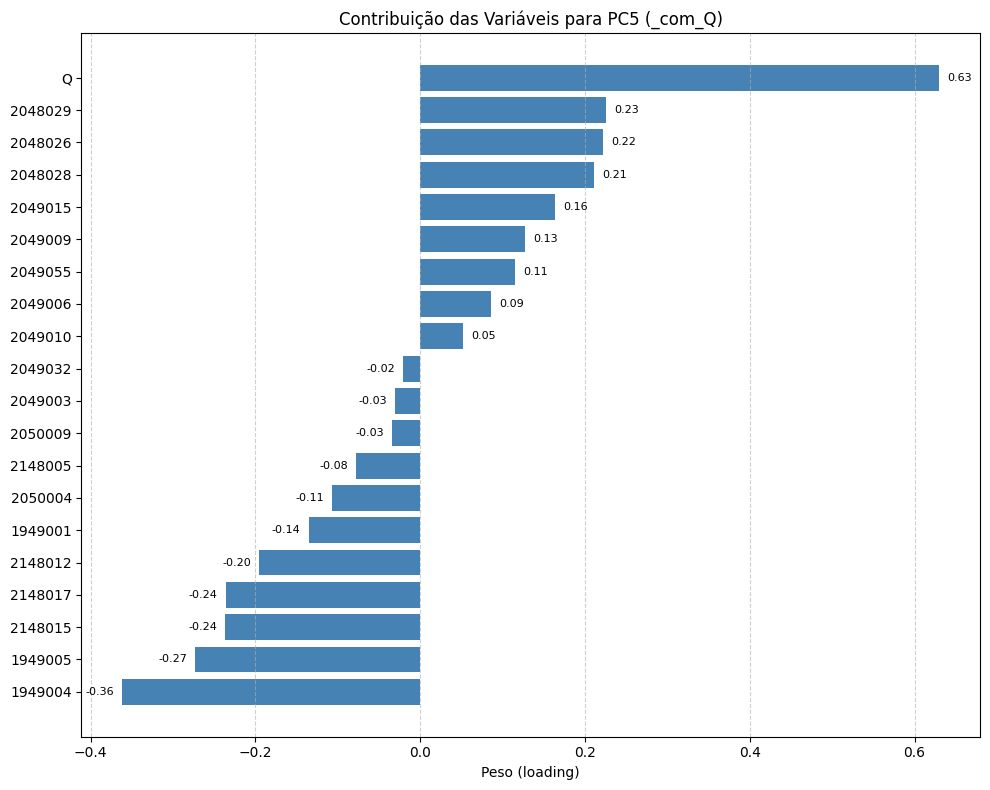


===== Principais Variáveis por Componente (_com_Q) =====

PC1 - Top 5 Variáveis (Absoluto):
  1. 2048029: +0.251
  2. 2048026: +0.250
  3. 2048028: +0.246
  4. 2049015: +0.243
  5. 2049055: +0.243

PC2 - Top 5 Variáveis (Absoluto):
  1. 2148015: +0.358
  2. 2148017: +0.338
  3. 2148012: +0.327
  4. 2148005: +0.272
  5. 2050009: -0.249

PC3 - Top 5 Variáveis (Absoluto):
  1. 1949005: +0.487
  2. 1949004: +0.433
  3. 2048029: +0.256
  4. 2048026: +0.247
  5. 2049032: -0.244

PC4 - Top 5 Variáveis (Absoluto):
  1. Q: +0.749
  2. 2048029: -0.254
  3. 2048026: -0.241
  4. 2048028: -0.239
  5. 2148017: +0.223

PC5 - Top 5 Variáveis (Absoluto):
  1. Q: +0.630
  2. 1949004: -0.362
  3. 1949005: -0.273
  4. 2148015: -0.236
  5. 2148017: -0.236
===== ANÁLISE PCA (COMQ) CONCLUÍDA =====
                 PC1       PC2       PC3       PC4       PC5       PC6  \
Data                                                                     
1982-04-01 -1.614448  0.040505 -0.030736 -0.063219  0.002201  0.0

In [ ]:
# Removemos linhas com valores nulos (NaN) para que o PCA funcione corretamente
df_datamining_sem_na = df_datamining.dropna()

df_pca, df_pca_filtrado = fazer_pca(df_datamining_sem_na, caminho_figuras, caminho_df_saida)
print(df_pca.head(10))
print()
print(df_pca_filtrado.head(10))

---
# 3. Modelos

Reformula a previsão de vazão como um problema de **classificação**: chuva e
vazão são categorizadas por faixas de percentil, e 18 classificadores
diferentes são treinados para prever a faixa de vazão a partir da chuva
(com lags) e de lags da própria vazão.

Todos os `rodar_*` seguem o mesmo padrão: recebem `dados_entrada_modelo`,
um dict de `parametros` (hiperparâmetros do modelo -- se `None`, usa
defaults sensatos), treinam, imprimem acurácia + relatório de classificação,
plotam a matriz de confusão e retornam `{'clf': modelo, 'y_pred': previsões}`.
Em seguida, `plotar_resultados` decodifica as previsões de volta para vazão
numérica, plota Real x Previsto e salva os resultados em
`Resultados_Machine_Learning/<nome_modelo>/`.

In [ ]:
from Modelos import (
    pre_tratamento,
    pre_classificadores,
    plotar_resultados,
    rodar_random_forest,
    rodar_decision_tree,
    rodar_gradient_boosting,
    rodar_hist_gradient_boosting,
    rodar_mlp,
    rodar_extra_trees,
    rodar_svc,
    rodar_kneighbors,
    rodar_gaussian_nb,
    rodar_logistic_regression,
    rodar_linear_svc,
    rodar_ridge_classifier,
    rodar_perceptron,
    rodar_qda,
    rodar_lda,
    rodar_xgboost,
    rodar_lightgbm,
    rodar_catboost,
    funcao_diagnostico_overfitting,
    plotar_curva_validacao,
)

## 3.1 Leitura da base + categorização por percentis

`pre_tratamento` separa X (chuva) / y (vazão), calcula os percentis
escolhidos e categoriza os valores numéricos em faixas (ex:
`Meio_Vazao_percentil_40_percentil_60_Q`).

⚠️ `col_dependente` **precisa ser `'Q'`** -- `plotar_resultados` (Seção 3.3)
espera esse nome.

🟢 **Edite as listas de percentis** conforme sua análise.

In [ ]:
df = pd.read_excel('SAIDA/Dataframes/BASES PARA MODELAGEM/df_clusters.xlsx')

dados_cat = pre_tratamento(
    df,
    col_dependente='Q',
    col_data='Data',
    lista_percentis_chuva=[75, 80, 90, 95, 99],   # 🟢 edite
    lista_percentis_vazao=[20, 40, 60, 80],        # 🟢 edite
    printar_percentis=True,
    retornar_tudo=True
)

+----+----------------+----------------+----------------+----------------+----------------+
|    |   percentil_75 |   percentil_80 |   percentil_90 |   percentil_95 |   percentil_99 |
+====+================+================+================+================+================+
| C1 |        2.43333 |          5.1   |         15.3   |        25.1633 |        51.8527 |
+----+----------------+----------------+----------------+----------------+----------------+
| C2 |        2.94    |          5.064 |         13.96  |        22.718  |        41.1756 |
+----+----------------+----------------+----------------+----------------+----------------+
| C3 |        1.2     |          3.3   |         13.4   |        27      |        54.2    |
+----+----------------+----------------+----------------+----------------+----------------+
| C4 |        1.6     |          3.66  |         13.16  |        26.3    |        54.116  |
+----+----------------+----------------+----------------+----------------+------

## 3.2 Preparo para os classificadores

`pre_classificadores` cria os lags de chuva e vazão, faz o split
treino/teste (temporal, sem embaralhar) e aplica `LabelEncoder` em todas as
colunas.

🟢 **Edite `tamanho_teste` e `num_lags`** conforme sua análise.

In [ ]:
dados_entrada_modelo = pre_classificadores(
    dados_cat['X_categorizada'],
    dados_cat['y_categorizada'],
    tamanho_teste=0.3,  # 🟢 edite
    num_lags=2           # 🟢 edite
)

Dados após criação de lags e remoção de NaNs (shape=(5141, 21)):
+---------------------+--------------------------------+--------------------------------+--------------------------------+--------------------------------+--------------------------------+--------------------------------+-----------------------------------------+-----------------------------------------+-----------------------------------------+-----------------------------------------+-----------------------------------------+-----------------------------------------+-----------------------------------------+-----------------------------------------+-----------------------------------------+--------------------------------+--------------------------------+--------------------------------+--------------------+--------------------+--------------------+
| Data                | C1_lag2                        | C1_lag1                        | C1                             | C2_lag2                        | C2_lag1          

## 3.3 Treino dos 18 classificadores

Cada bloco abaixo define os hiperparâmetros de um modelo, treina (`rodar_*`)
e pós-processa (`plotar_resultados`, que salva Excel + figura em
`Resultados_Machine_Learning/<nome_modelo>/`). 🟢 **Edite os hiperparâmetros**
de cada modelo conforme necessário -- os comentários em cada dict explicam o
que cada parâmetro controla.


```
# Isto está formatado como código
```

### Random Forest

Acurácia: 0.9261

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       285
           1       0.92      0.91      0.92       319
           2       0.91      0.91      0.91       298
           3       0.92      0.92      0.92       379
           4       0.94      0.94      0.94       262

    accuracy                           0.93      1543
   macro avg       0.93      0.93      0.93      1543
weighted avg       0.93      0.93      0.93      1543



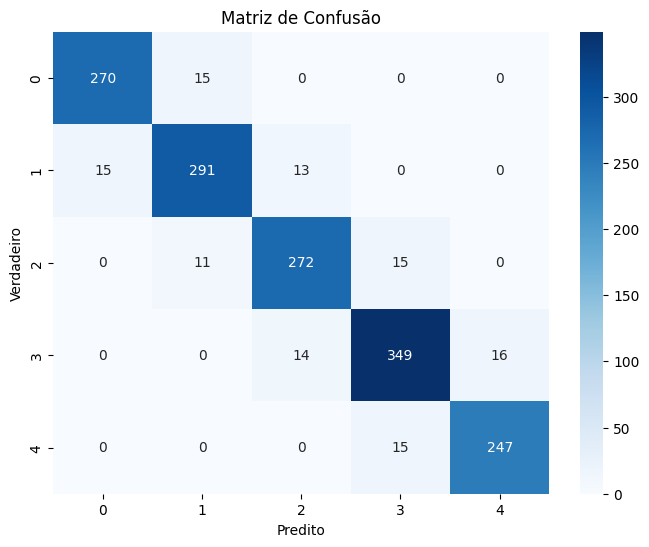

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Random Forest/Random Forest.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Random Forest/Random Fores

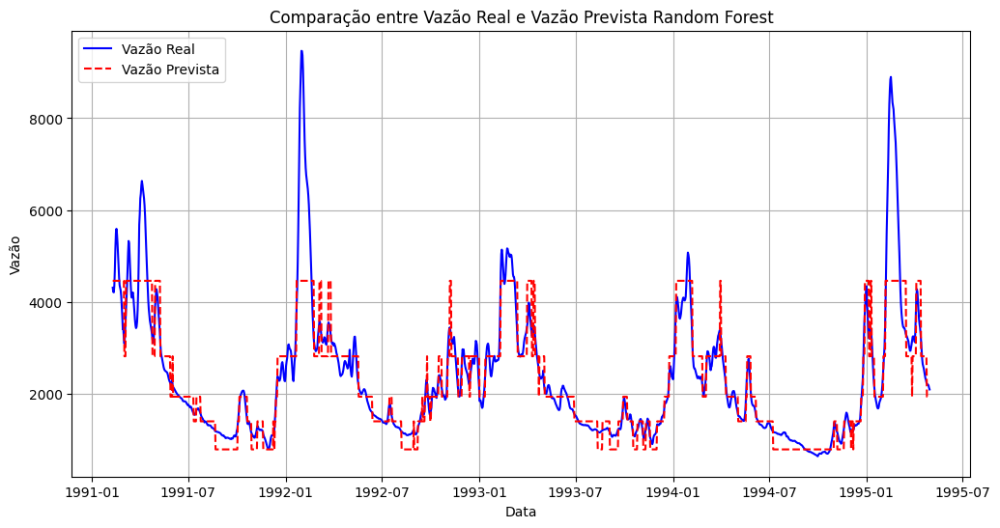

In [ ]:
parametros_rf = {
    'n_estimators': 100,             # Número de árvores na floresta
    'criterion': 'gini',             # Função para medir qualidade da divisão ('gini' ou 'entropy')
    'max_depth': None,               # Profundidade máxima da árvore (None = sem limite)
    'min_samples_split': 2,          # Mínimo de amostras para dividir um nó interno
    'min_samples_leaf': 1,           # Mínimo de amostras em um nó folha
    'min_weight_fraction_leaf': 0.0, # Fração mínima de peso total para um nó folha
    'max_features': 'sqrt',          # Número de features a considerar para melhor divisão
    'max_leaf_nodes': None,          # Número máximo de nós folha (None = sem limite)
    'min_impurity_decrease': 0.0,    # Redução mínima de impureza para dividir
    'bootstrap': True,               # Se usar amostragem com reposição
    'oob_score': False,              # Se calcular Out-of-Bag score
    'n_jobs': None,                  # Jobs em paralelo (None = 1, -1 = todos os núcleos)
    'random_state': 42,              # Semente para reprodutibilidade
    'verbose': 0,
    'warm_start': False,
    'class_weight': None,
    'ccp_alpha': 0.0,
    'max_samples': None
}

dados_modelo_RF = rodar_random_forest(dados_entrada_modelo, parametros_rf)
df_RandomForest = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_RF,
    plot_interativo=False,
    nome_modelo='Random Forest',
    salvar_resultados=True,
    salvar_figura=True
)

### Decision Tree

Acurácia: 0.9034

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       285
           1       0.90      0.89      0.89       319
           2       0.87      0.90      0.89       298
           3       0.91      0.87      0.89       379
           4       0.91      0.94      0.93       262

    accuracy                           0.90      1543
   macro avg       0.90      0.91      0.90      1543
weighted avg       0.90      0.90      0.90      1543



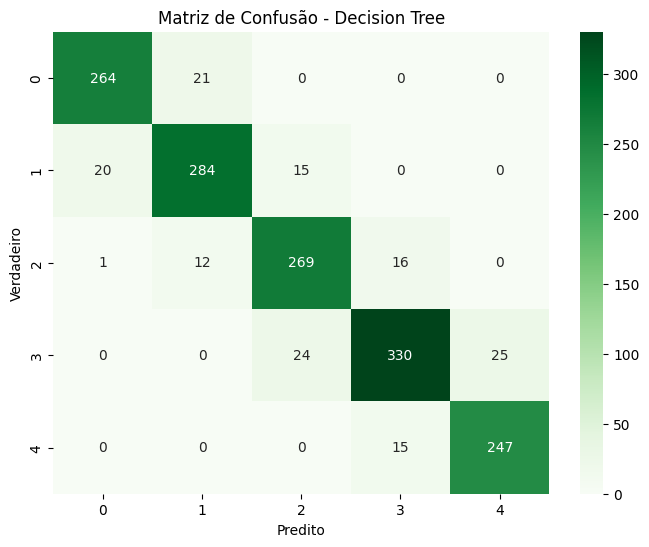

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Decision Tree/Decision Tree.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Decision Tree/Decision Tre

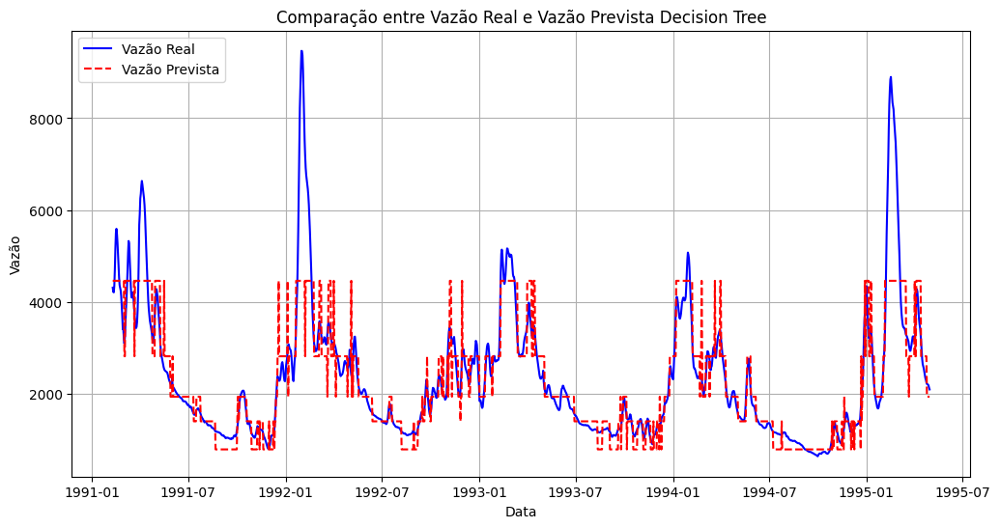

In [ ]:
parametros_DT = {
    'criterion': 'gini',
    'splitter': 'best',
    'max_depth': 10,                 # Controla overfitting -- valores baixos = árvore mais simples
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'min_weight_fraction_leaf': 0.0,
    'max_features': None,
    'random_state': 42,
    'max_leaf_nodes': None,
    'min_impurity_decrease': 0.0,
    'class_weight': None,
    'ccp_alpha': 0.0                 # Poda por complexidade -- valores > 0 simplificam a árvore
}

dados_modelo_tree = rodar_decision_tree(dados_entrada_modelo, parametros_DT)
df_DecisionTree = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_tree,
    plot_interativo=False,
    nome_modelo='Decision Tree',
    salvar_resultados=True,
    salvar_figura=True
)

### Gradient Boosting

Acurácia: 0.9255

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       285
           1       0.92      0.92      0.92       319
           2       0.92      0.91      0.91       298
           3       0.92      0.92      0.92       379
           4       0.93      0.94      0.93       262

    accuracy                           0.93      1543
   macro avg       0.93      0.93      0.93      1543
weighted avg       0.93      0.93      0.93      1543



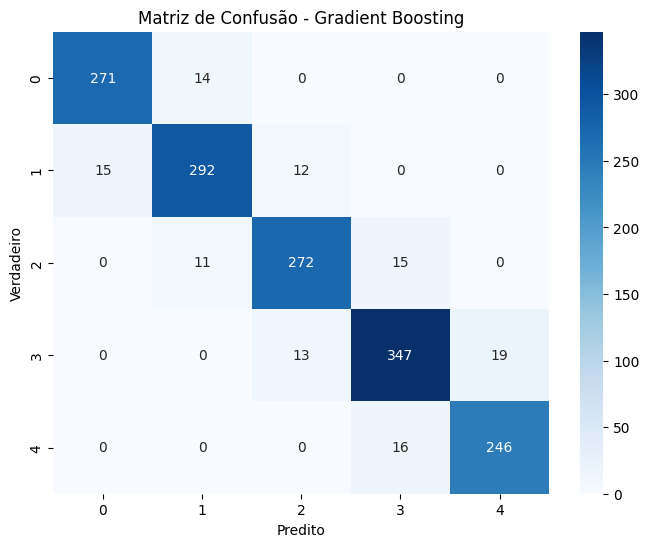

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Gradient Boosting/Gradient Boosting.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Gradient Boosting/

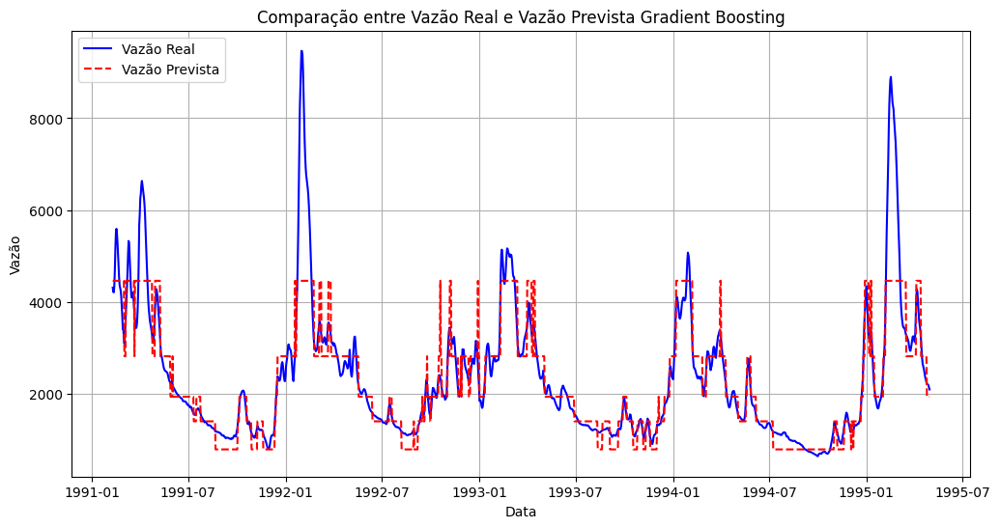

In [ ]:
parametros_GB = {
    'loss': 'log_loss',
    'learning_rate': 0.1,
    'n_estimators': 100,
    'subsample': 1.0,
    'criterion': 'friedman_mse',
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'min_weight_fraction_leaf': 0.0,
    'max_depth': 3,
    'min_impurity_decrease': 0.0,
    'init': None,
    'random_state': 42,
    'max_features': None,
    'verbose': 0,
    'max_leaf_nodes': None,
    'warm_start': False,
    'validation_fraction': 0.1,
    'n_iter_no_change': None,
    'tol': 1e-4
}

dados_modelo_GB = rodar_gradient_boosting(dados_entrada_modelo, parametros_GB)
df_GradientBoost = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_GB,
    plot_interativo=False,
    nome_modelo='Gradient Boosting',
    salvar_resultados=True,
    salvar_figura=True
)

### Histogram Gradient Boost

Acurácia: 0.9294

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       285
           1       0.92      0.92      0.92       319
           2       0.92      0.92      0.92       298
           3       0.92      0.92      0.92       379
           4       0.94      0.94      0.94       262

    accuracy                           0.93      1543
   macro avg       0.93      0.93      0.93      1543
weighted avg       0.93      0.93      0.93      1543



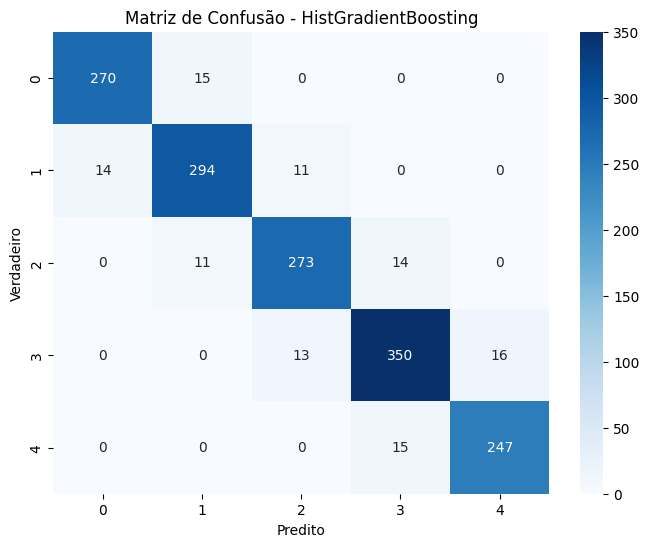

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Histogram Gradient Boost/Histogram Gradient Boost.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Hist

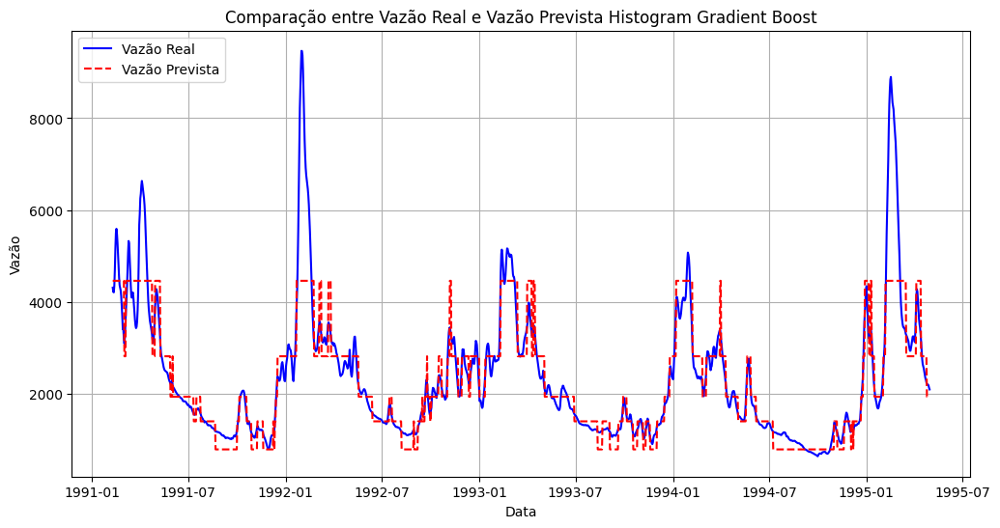

In [ ]:
parametros_HGB = {
    'loss': 'log_loss',
    'learning_rate': 0.1,
    'max_iter': 100,
    'max_leaf_nodes': 31,
    'max_depth': None,
    'min_samples_leaf': 20,
    'max_bins': 255,
    'categorical_features': None,
    'warm_start': False,
    'early_stopping': True,
    'validation_fraction': 0.1,
    'n_iter_no_change': 10,
    'tol': 1e-7,
    'scoring': None,
    'verbose': 0,
    'random_state': 42,
    'l2_regularization': 0.0
}

dados_modelo_HGB = rodar_hist_gradient_boosting(dados_entrada_modelo, parametros_HGB)
df_HistogramGradientBoost = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_HGB,
    plot_interativo=False,
    nome_modelo='Histogram Gradient Boost',
    salvar_resultados=True,
    salvar_figura=True
)

### MLP Classifier

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.



Acurácia: 0.9047

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       285
           1       0.91      0.90      0.90       319
           2       0.87      0.90      0.88       298
           3       0.90      0.88      0.89       379
           4       0.92      0.92      0.92       262

    accuracy                           0.90      1543
   macro avg       0.91      0.91      0.91      1543
weighted avg       0.90      0.90      0.90      1543



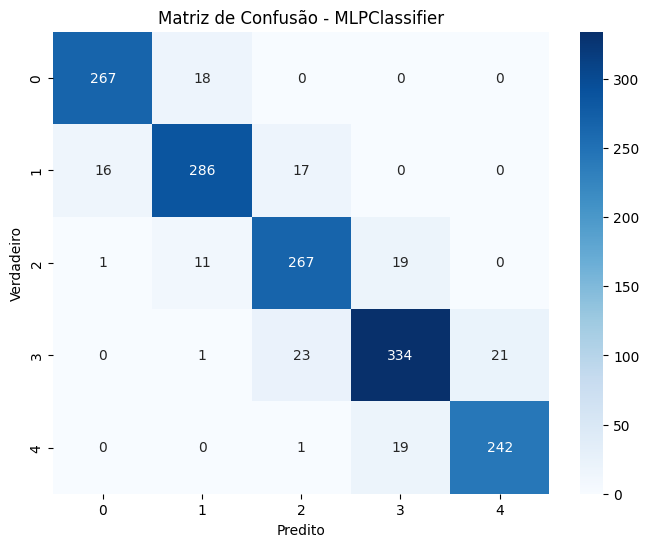

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/MLP Classifier/MLP Classifier.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/MLP Classifier/MLP Class

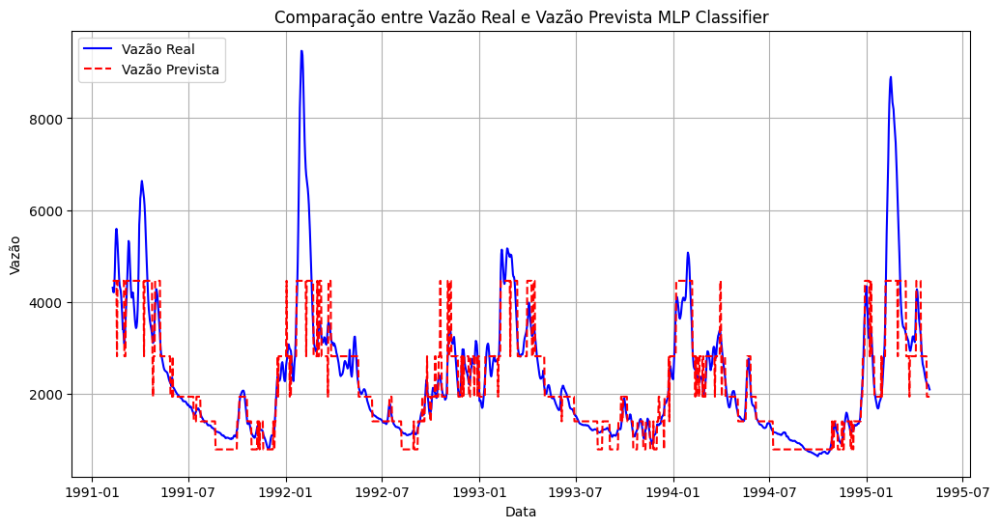

In [ ]:
parametros_MLP = {
    'hidden_layer_sizes': (100,),
    'activation': 'relu',
    'solver': 'adam',
    'alpha': 0.0001,
    'batch_size': 'auto',
    'learning_rate': 'constant',
    'learning_rate_init': 0.001,
    'power_t': 0.5,
    'max_iter': 200,
    'shuffle': True,
    'random_state': 42,
    'tol': 1e-4,
    'verbose': False,
    'warm_start': False,
    'momentum': 0.9,
    'nesterovs_momentum': True,
    'early_stopping': False,
    'validation_fraction': 0.1,
    'beta_1': 0.9,
    'beta_2': 0.999,
    'epsilon': 1e-8,
    'n_iter_no_change': 10,
    'max_fun': 15000
}

dados_modelo_MLP = rodar_mlp(dados_entrada_modelo, parametros_MLP)
df_MLPClassifier = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_MLP,
    plot_interativo=False,
    nome_modelo='MLP Classifier',
    salvar_resultados=True,
    salvar_figura=True
)

### Extra Tree Classifier

Acurácia: 0.9222

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95       285
           1       0.91      0.91      0.91       319
           2       0.90      0.91      0.91       298
           3       0.92      0.91      0.92       379
           4       0.94      0.94      0.94       262

    accuracy                           0.92      1543
   macro avg       0.92      0.92      0.92      1543
weighted avg       0.92      0.92      0.92      1543



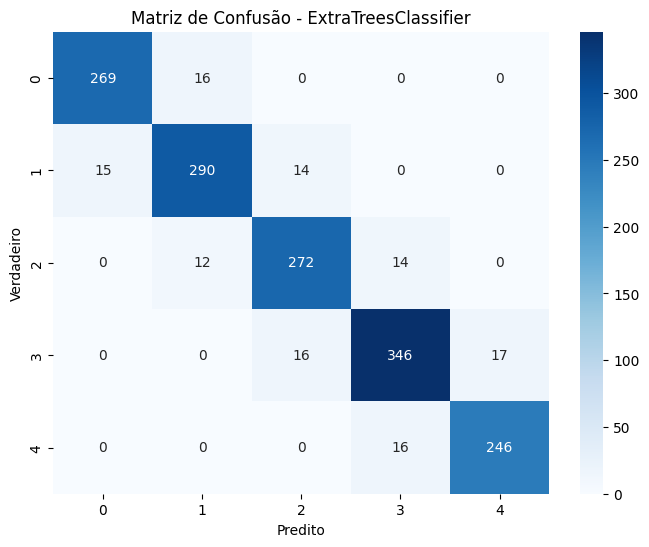

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Extra Tree Classifier/Extra Tree Classifier.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Extra Tree

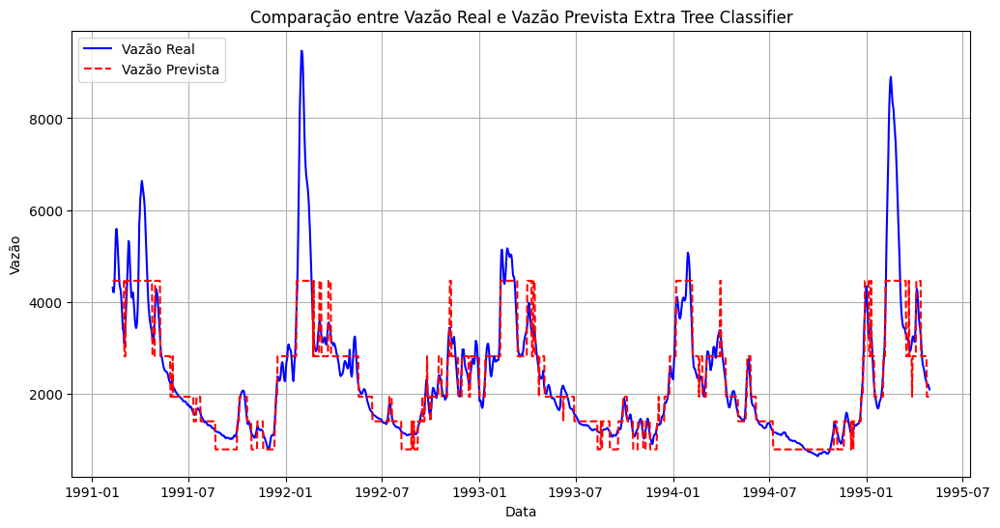

In [ ]:
parametros_ET = {
    'n_estimators': 100,
    'criterion': 'gini',
    'max_depth': None,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'min_weight_fraction_leaf': 0.0,
    'max_features': 'sqrt',
    'max_leaf_nodes': None,
    'min_impurity_decrease': 0.0,
    'bootstrap': False,
    'oob_score': False,
    'n_jobs': -1,
    'random_state': 42,
    'class_weight': None,
    'ccp_alpha': 0.0,
    'max_samples': None
}

dados_modelo_ET = rodar_extra_trees(dados_entrada_modelo, parametros_ET)
df_ExtraTreeClassifier = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_ET,
    plot_interativo=False,
    nome_modelo='Extra Tree Classifier',
    salvar_resultados=True,
    salvar_figura=True
)

### SVC

Acurácia: 0.9132

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       285
           1       0.91      0.90      0.91       319
           2       0.91      0.89      0.90       298
           3       0.91      0.90      0.90       379
           4       0.90      0.95      0.92       262

    accuracy                           0.91      1543
   macro avg       0.91      0.92      0.91      1543
weighted avg       0.91      0.91      0.91      1543



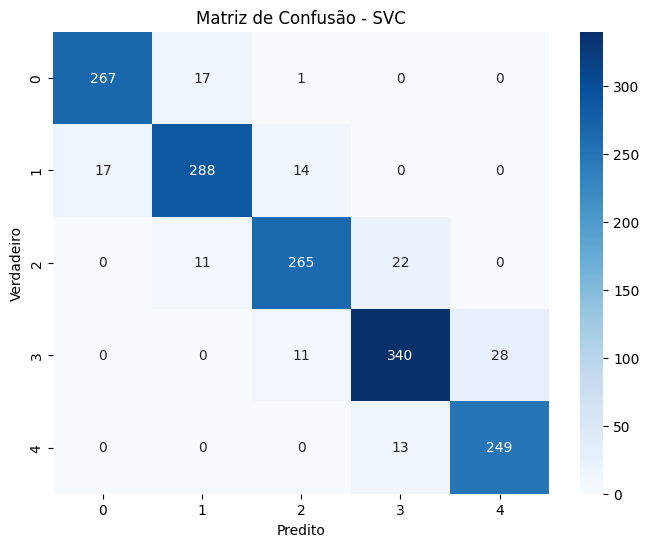

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/SVC/SVC.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/SVC/SVC.png


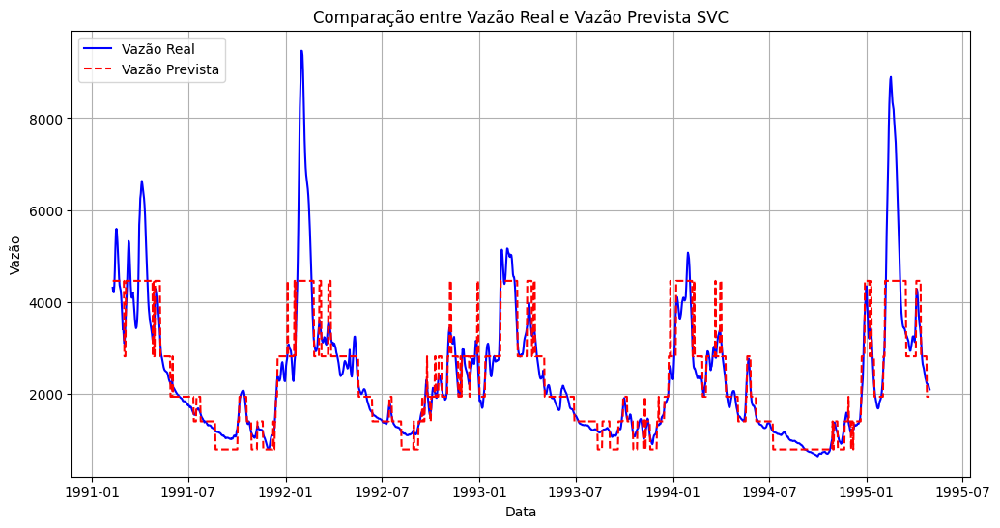

In [ ]:
parametros_SVC = {
    'C': 1.0,
    'kernel': 'rbf',
    'degree': 3,
    'gamma': 'scale',
    'coef0': 0.0,
    'shrinking': True,
    'probability': False,
    'tol': 1e-3,
    'cache_size': 200,
    'class_weight': None,
    'verbose': False,
    'max_iter': -1,
    'decision_function_shape': 'ovr',
    'break_ties': False,
    'random_state': 42
}

dados_modelo_SVC = rodar_svc(dados_entrada_modelo, parametros_SVC)
df_SVC = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_SVC,
    plot_interativo=False,
    nome_modelo='SVC',
    salvar_resultados=True,
    salvar_figura=True
)

### KN Neighbors Classifier

Acurácia: 0.7479

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.85      0.91      0.88       285
           1       0.80      0.77      0.79       319
           2       0.65      0.78      0.71       298
           3       0.72      0.58      0.64       379
           4       0.74      0.76      0.75       262
           5       0.00      0.00      0.00         0

    accuracy                           0.75      1543
   macro avg       0.63      0.63      0.63      1543
weighted avg       0.75      0.75      0.75      1543



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.



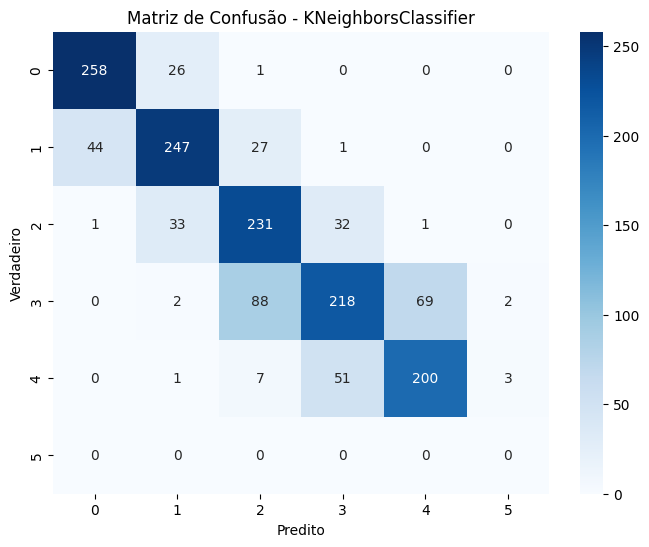

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           2821.1 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/KN Neighbors Classifier/KN Neighbors Classifier.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/KN Nei

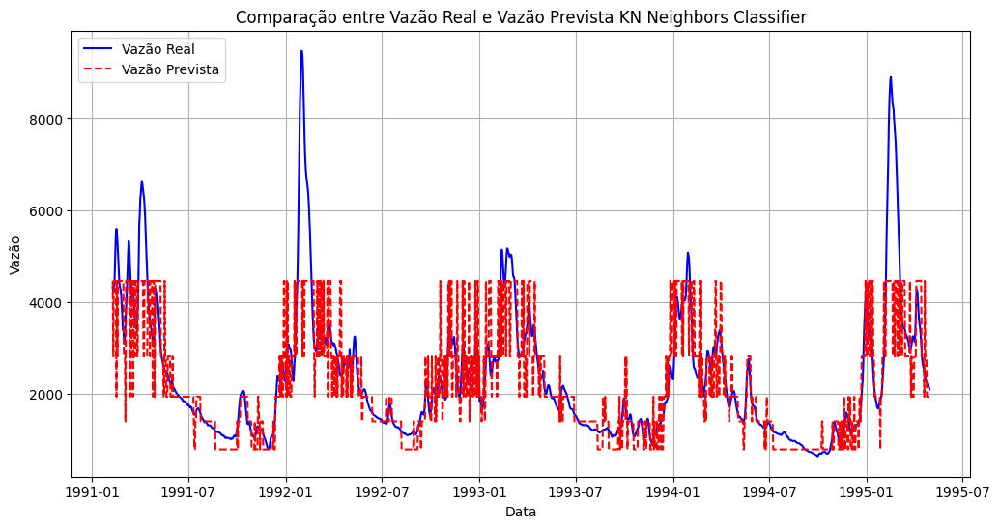

In [ ]:
parametros_KNN = {
    'n_neighbors': 5,
    'weights': 'uniform',
    'algorithm': 'auto',
    'leaf_size': 30,
    'p': 2,
    'metric': 'minkowski',
    'metric_params': None,
    'n_jobs': -1
}

dados_modelo_KNN = rodar_kneighbors(dados_entrada_modelo, parametros_KNN)
df_KNN = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_KNN,
    plot_interativo=False,
    nome_modelo='KN Neighbors Classifier',
    salvar_resultados=True,
    salvar_figura=True
)

### Gaussian Naive Bayes

Acurácia: 0.9034

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95       285
           1       0.90      0.87      0.88       319
           2       0.87      0.85      0.86       298
           3       0.87      0.93      0.90       379
           4       0.94      0.93      0.93       262

    accuracy                           0.90      1543
   macro avg       0.91      0.90      0.90      1543
weighted avg       0.90      0.90      0.90      1543



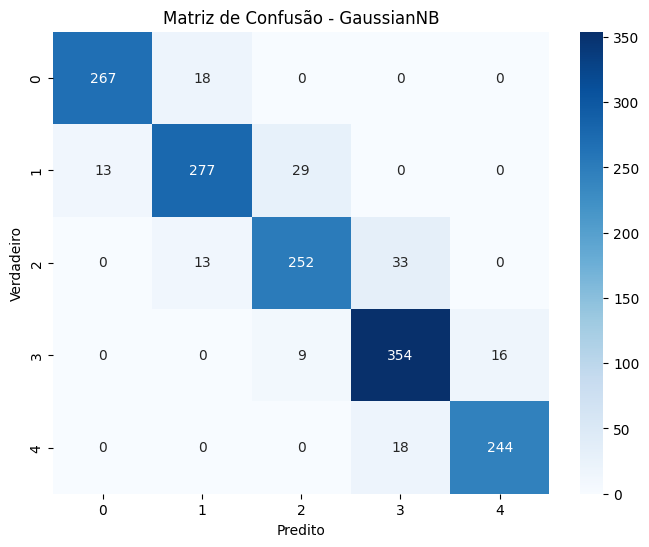

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Gaussian Naive Bayes/Gaussian Naive Bayes.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Gaussian Nai

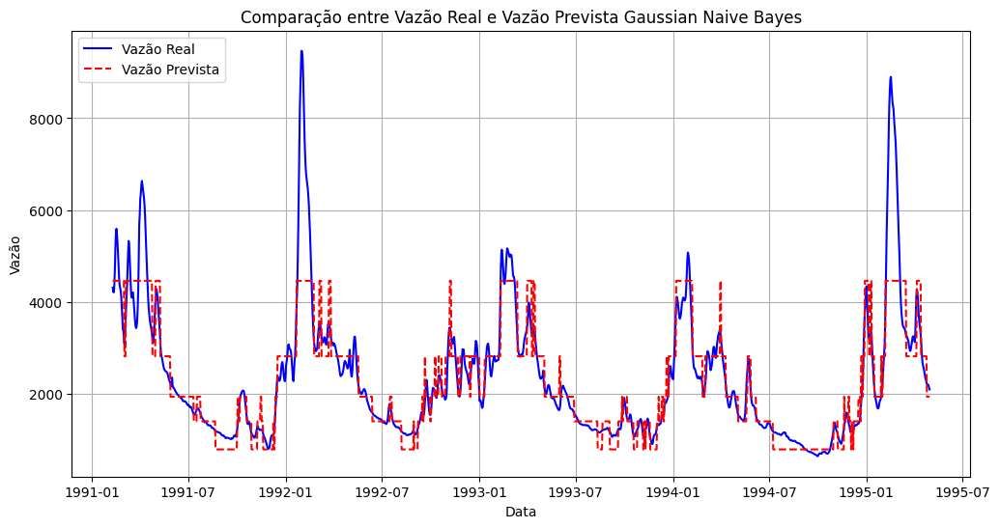

In [ ]:
parametros_GNB = {
    'priors': None,
    'var_smoothing': 1e-9
}

dados_modelo_GNB = rodar_gaussian_nb(dados_entrada_modelo, parametros_GNB)
df_GNB = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_GNB,
    plot_interativo=False,
    nome_modelo='Gaussian Naive Bayes',
    salvar_resultados=True,
    salvar_figura=True
)

### Logistic Regression

Acurácia: 0.9281

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95       285
           1       0.91      0.92      0.92       319
           2       0.92      0.92      0.92       298
           3       0.92      0.92      0.92       379
           4       0.94      0.94      0.94       262

    accuracy                           0.93      1543
   macro avg       0.93      0.93      0.93      1543
weighted avg       0.93      0.93      0.93      1543



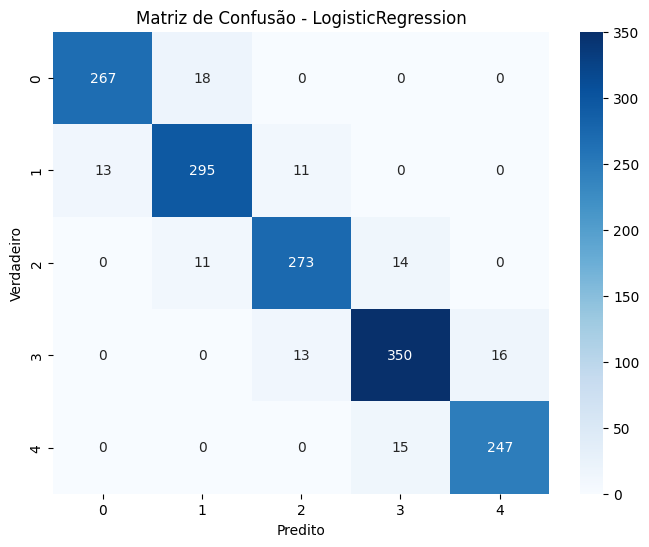

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Logistic Regression/Logistic Regression.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Logistic Regre

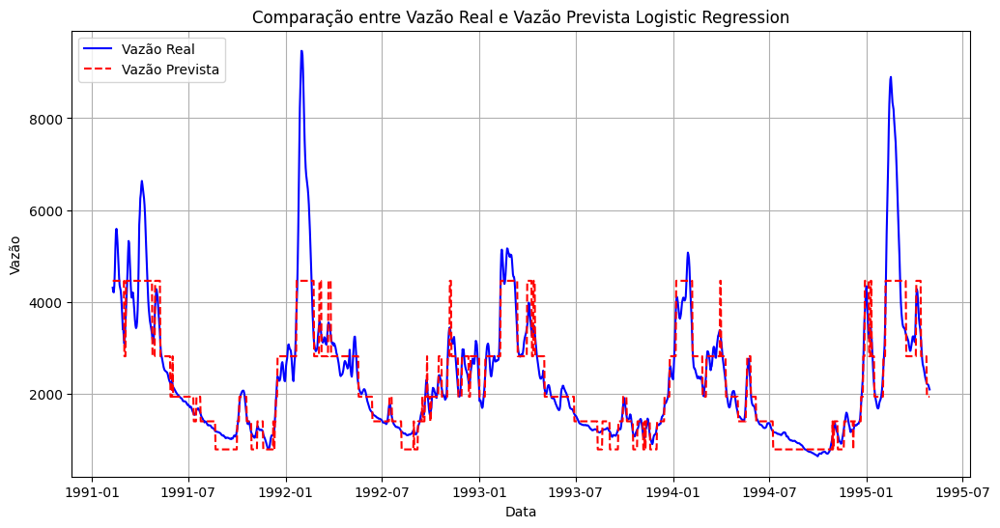

In [ ]:
parametros_LR = {
    'solver': 'lbfgs',
    'max_iter': 2000,
    'random_state': 42,
    'C': 1.0,
    'penalty': 'l2',
    'n_jobs': None
}

dados_modelo_LR = rodar_logistic_regression(dados_entrada_modelo, parametros_LR)
df_LR = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_LR,
    plot_interativo=False,
    nome_modelo='Logistic Regression',
    salvar_resultados=True,
    salvar_figura=True
)

### Linear SVC

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning:

Liblinear failed to converge, increase the number of iterations.



Acurácia: 0.6079

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95       285
           1       0.59      0.88      0.71       319
           2       0.46      0.24      0.31       298
           3       0.60      0.15      0.23       379
           4       0.49      1.00      0.65       262

    accuracy                           0.61      1543
   macro avg       0.62      0.64      0.57      1543
weighted avg       0.62      0.61      0.55      1543



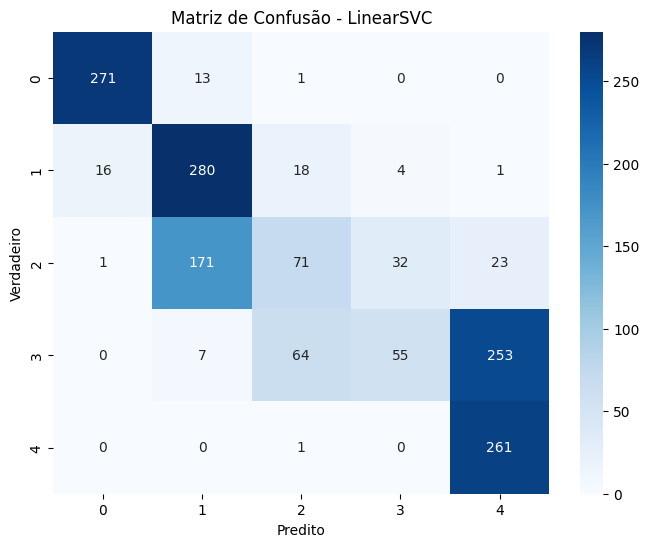

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Linear SVC/Linear SVC.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Linear SVC/Linear SVC.png


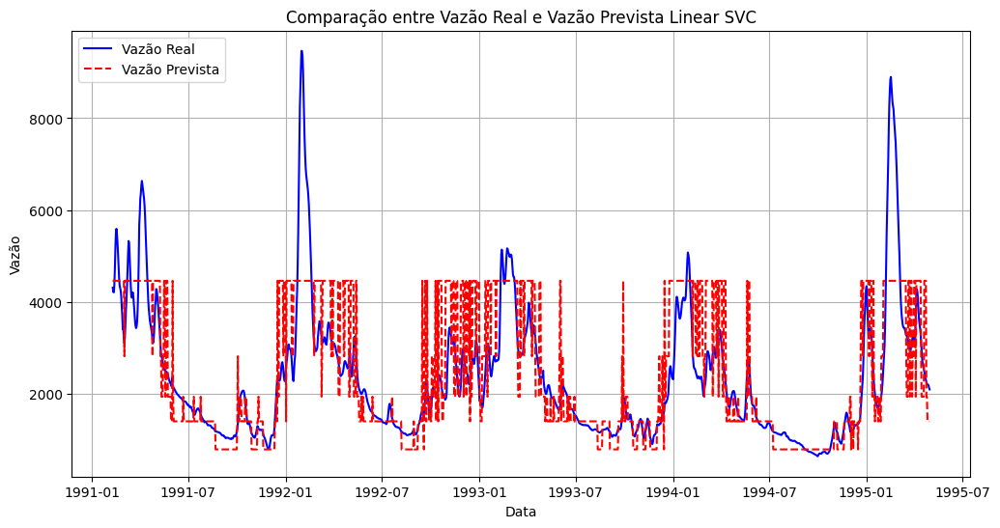

In [ ]:
parametros_LSVC = {
    'C': 1.0,
    'max_iter': 1000,
    'random_state': 42,
    'tol': 1e-4,
    'dual': True,
    'loss': 'squared_hinge'
}

dados_modelo_LSVC = rodar_linear_svc(dados_entrada_modelo, parametros_LSVC)
df_LSVC = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_LSVC,
    plot_interativo=False,
    nome_modelo='Linear SVC',
    salvar_resultados=True,
    salvar_figura=True
)

### Ridge Classifier

Acurácia: 0.3629

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.34      1.00      0.51       285
           1       0.24      0.02      0.04       319
           2       1.00      0.01      0.03       298
           3       0.80      0.02      0.04       379
           4       0.39      0.98      0.56       262
           5       0.00      0.00      0.00         0

    accuracy                           0.36      1543
   macro avg       0.46      0.34      0.20      1543
weighted avg       0.57      0.36      0.21      1543



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.



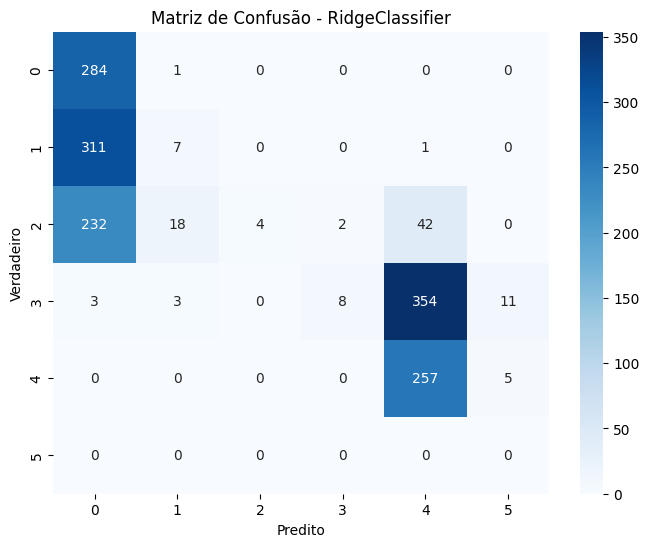

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Ridge Classifier/Ridge Classifier.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Ridge Classifier/Rid

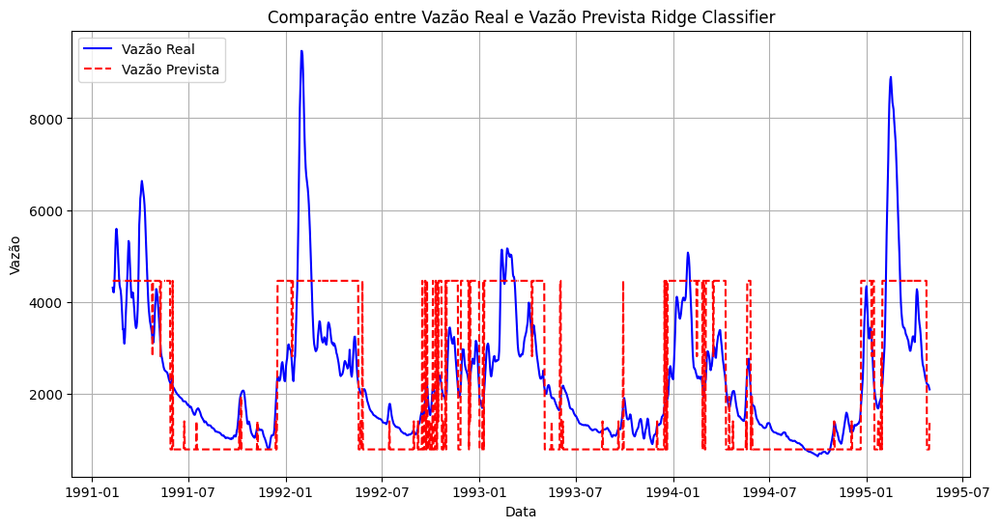

In [ ]:
parametros_Ridge = {
    'alpha': 1.0,
    'max_iter': 1000,
    'tol': 1e-3,
    'solver': 'auto',
    'random_state': 42
}

dados_modelo_Ridge = rodar_ridge_classifier(dados_entrada_modelo, parametros_Ridge)
df_RidgeClassifier = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_Ridge,
    plot_interativo=False,
    nome_modelo='Ridge Classifier',
    salvar_resultados=True,
    salvar_figura=True
)

### Perceptron

Acurácia: 0.5211

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.89      0.94      0.92       285
           1       0.59      0.67      0.63       319
           2       0.19      0.04      0.07       298
           3       0.38      0.70      0.50       379
           4       0.54      0.16      0.24       262
           5       0.00      0.00      0.00         0

    accuracy                           0.52      1543
   macro avg       0.43      0.42      0.39      1543
weighted avg       0.51      0.52      0.47      1543



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.



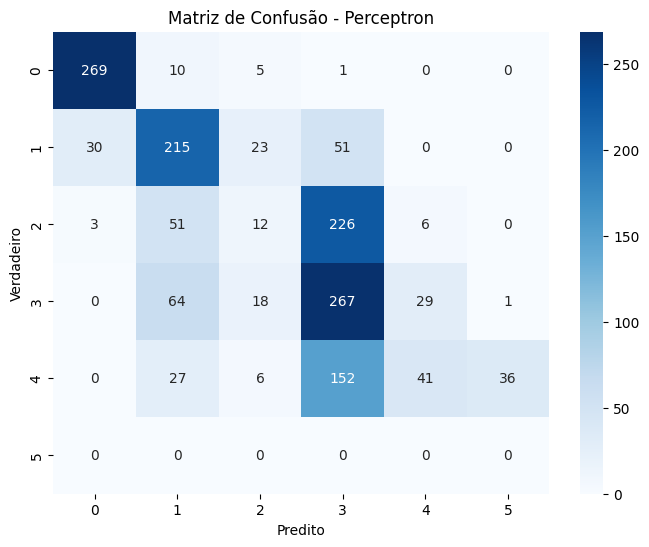

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           2821.1 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           1405.5 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           2821.1 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           2821.1 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Perceptron/Perceptron.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Perceptron/Perceptron.png


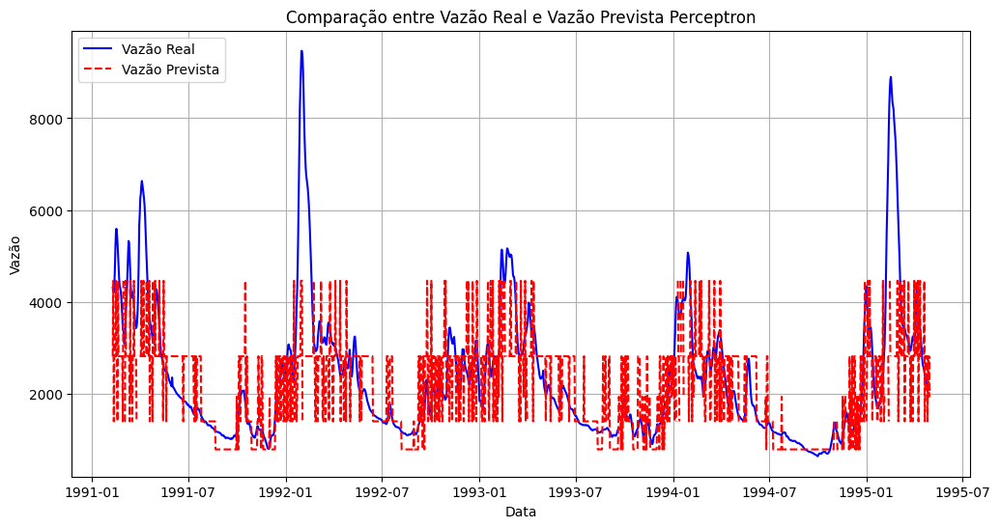

In [ ]:
parametros_Peceptron = {
    'max_iter': 1000,
    'eta0': 1.0,
    'tol': 1e-3,
    'random_state': 42,
    'penalty': None,
    'alpha': 0.0001,
    'fit_intercept': True,
    'shuffle': True
}

dados_modelo_Perceptron = rodar_perceptron(dados_entrada_modelo, parametros_Peceptron)
df_Perceptron = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_Perceptron,
    plot_interativo=False,
    nome_modelo='Perceptron',
    salvar_resultados=True,
    salvar_figura=True
)

### Quadratic Discriminant Analysis

/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning:

The covariance matrix of class 5 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.

/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1052: RuntimeWarning:

divide by zero encountered in power

/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1052: RuntimeWarning:

invalid value encountered in multiply

/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1055: RuntimeWarning:

divide by zero encountered in log

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Recall is ill-defi

Acurácia: 0.0000

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00     285.0
           1       0.00      0.00      0.00     319.0
           2       0.00      0.00      0.00     298.0
           3       0.00      0.00      0.00     379.0
           4       0.00      0.00      0.00     262.0
           5       0.00      0.00      0.00       0.0

    accuracy                           0.00    1543.0
   macro avg       0.00      0.00      0.00    1543.0
weighted avg       0.00      0.00      0.00    1543.0



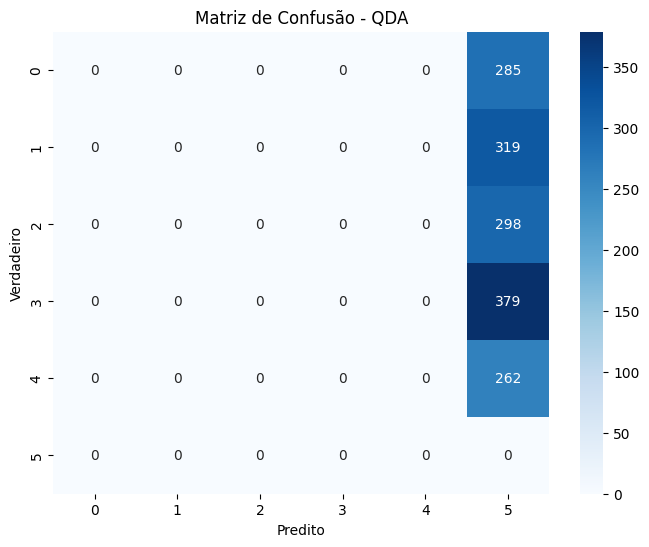

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |              nan |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |              nan |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |              nan |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |              nan |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |              nan |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Quadratic Discriminant Analysis/Quadratic Discriminant Analysis.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine

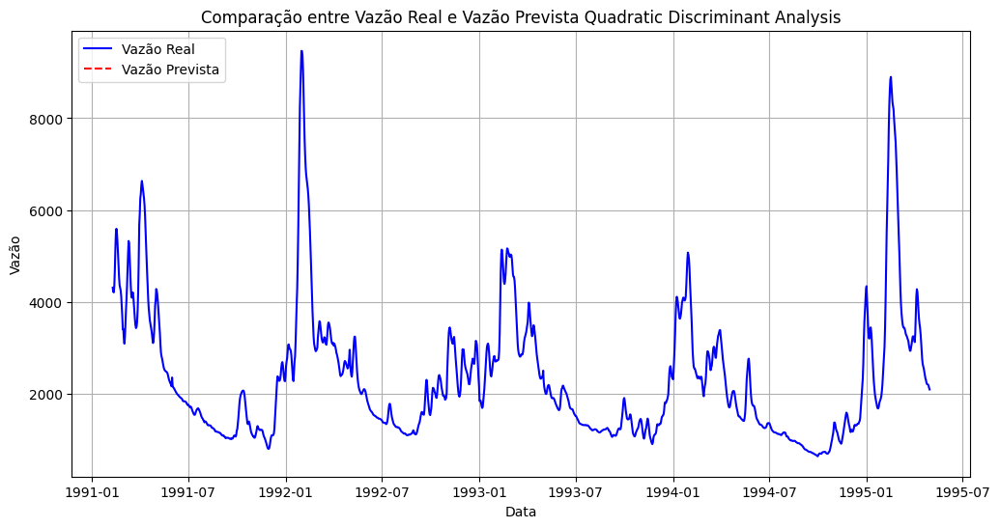

In [ ]:
parametros_QDA = {
    'priors': None,
    'reg_param': 0.0,
    'store_covariance': False,
    'tol': 1e-4
}

dados_modelo_QDA = rodar_qda(dados_entrada_modelo, parametros_QDA)
df_QDA = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_QDA,
    plot_interativo=False,
    nome_modelo='Quadratic Discriminant Analysis',
    salvar_resultados=True,
    salvar_figura=True
)

### Linear Discriminant Analysis

Acurácia: 0.9300

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       285
           1       0.92      0.92      0.92       319
           2       0.92      0.92      0.92       298
           3       0.92      0.92      0.92       379
           4       0.94      0.94      0.94       262

    accuracy                           0.93      1543
   macro avg       0.93      0.93      0.93      1543
weighted avg       0.93      0.93      0.93      1543



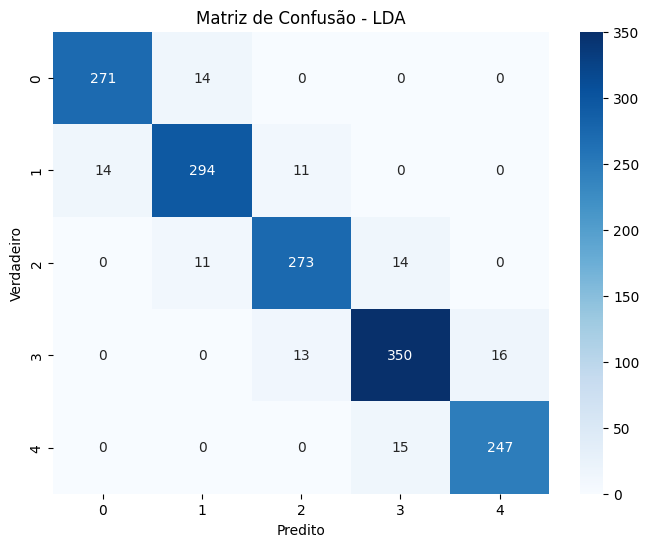

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/Linear Discriminant Analysis/Linear Discriminant Analysis.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learn

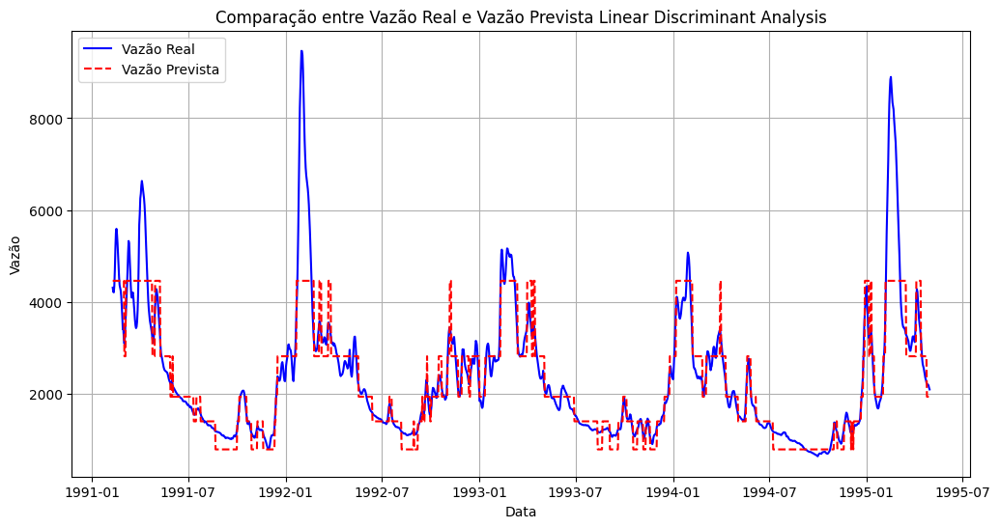

In [ ]:
parametros_LDA = {
    'solver': 'svd',
    'shrinkage': None,
    'priors': None,
    'n_components': None,
    'store_covariance': False,
    'tol': 1e-4
}

dados_modelo_LDA = rodar_lda(dados_entrada_modelo, parametros_LDA)
df_LDA = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_LDA,
    plot_interativo=False,
    nome_modelo='Linear Discriminant Analysis',
    salvar_resultados=True,
    salvar_figura=True
)

### XGBoost

Acurácia: 0.9261

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95       285
           1       0.92      0.91      0.91       319
           2       0.91      0.92      0.91       298
           3       0.92      0.92      0.92       379
           4       0.94      0.94      0.94       262

    accuracy                           0.93      1543
   macro avg       0.93      0.93      0.93      1543
weighted avg       0.93      0.93      0.93      1543



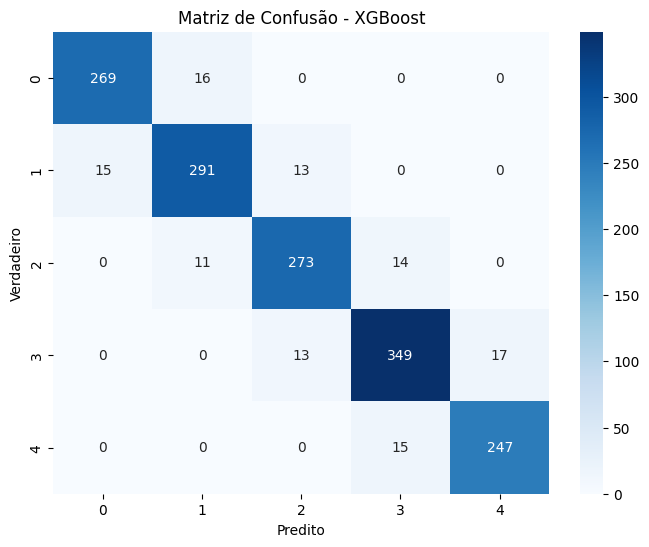

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/XGBoost/XGBoost.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/XGBoost/XGBoost.png


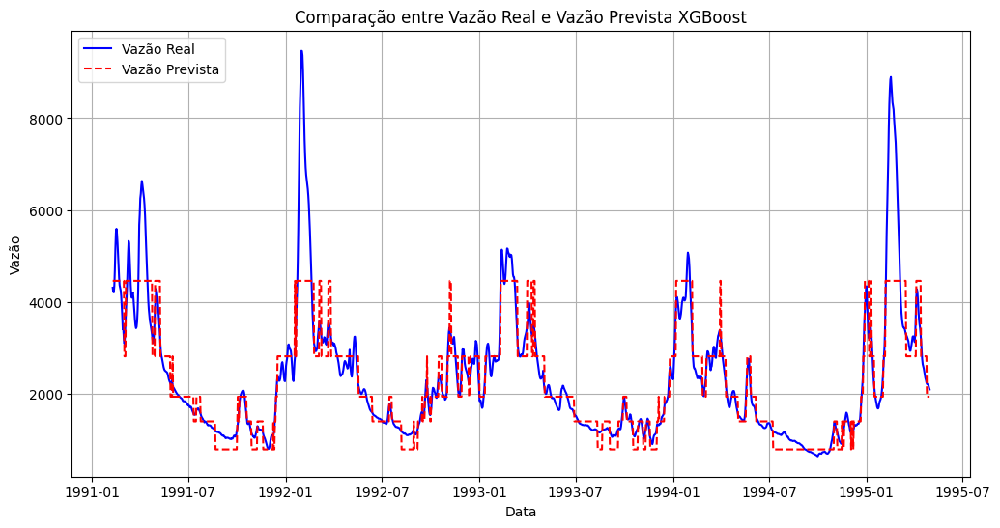

In [ ]:
parametros_XGB = {
    'n_estimators': 200,
    'max_depth': 5,
    'learning_rate': 0.05,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'random_state': 42,
    'eval_metric': 'mlogloss'
}

dados_modelo_XGB = rodar_xgboost(dados_entrada_modelo, parametros_XGB)
df_XGBoost = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_XGB,
    plot_interativo=False,
    nome_modelo='XGBoost',
    salvar_resultados=True,
    salvar_figura=True
)

### LightGBM

Acurácia: 0.9196

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95       285
           1       0.92      0.91      0.92       319
           2       0.89      0.92      0.90       298
           3       0.92      0.90      0.91       379
           4       0.92      0.94      0.93       262

    accuracy                           0.92      1543
   macro avg       0.92      0.92      0.92      1543
weighted avg       0.92      0.92      0.92      1543



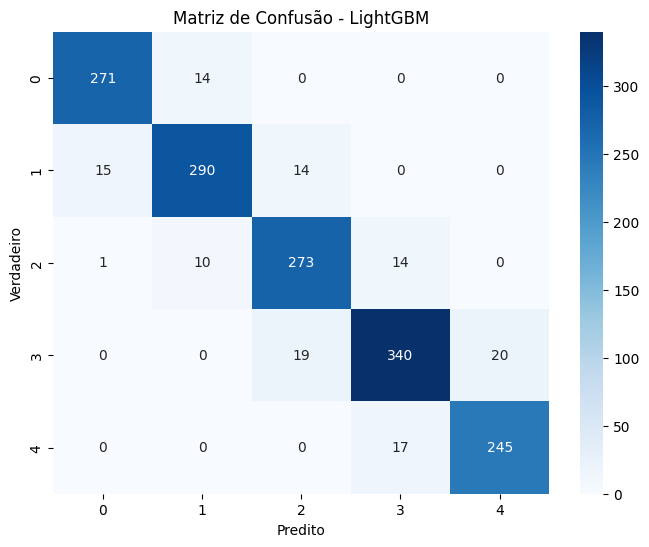

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/LightGBM/LightGBM.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/LightGBM/LightGBM.png


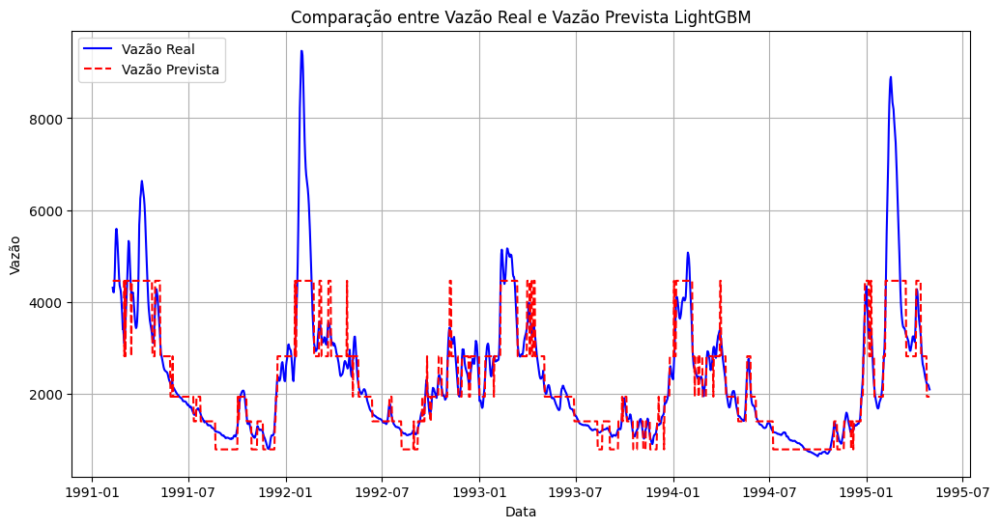

In [ ]:
parametros_LGB = {
    'n_estimators': 200,
    'learning_rate': 0.05,
    'max_depth': 7,
    'num_leaves': 50,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'reg_alpha': 0.1,
    'reg_lambda': 0.1,
    'random_state': 42,
    'verbose': -1
}

dados_modelo_LGB = rodar_lightgbm(dados_entrada_modelo, parametros_LGB)
df_LightGBM = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_LGB,
    plot_interativo=False,
    nome_modelo='LightGBM',
    salvar_resultados=True,
    salvar_figura=True
)

### CatBoost

Acurácia: 0.9294

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       285
           1       0.92      0.92      0.92       319
           2       0.92      0.92      0.92       298
           3       0.92      0.93      0.92       379
           4       0.94      0.94      0.94       262

    accuracy                           0.93      1543
   macro avg       0.93      0.93      0.93      1543
weighted avg       0.93      0.93      0.93      1543



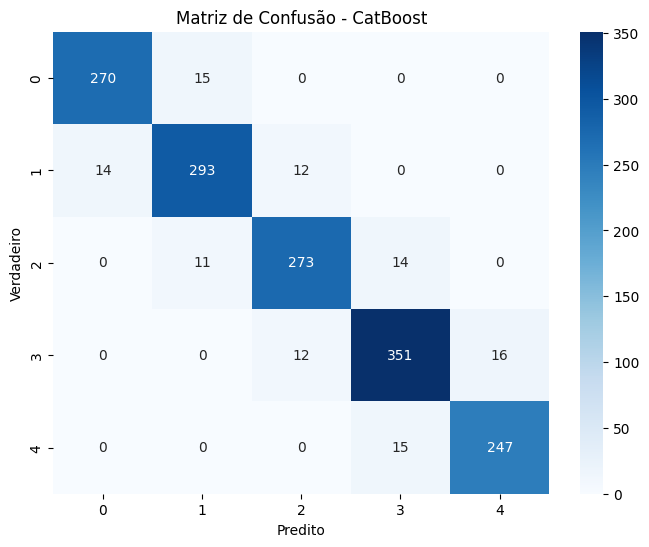

+---------------------+--------------+------------------+
| Data                |   Vazão Real |   Vazão Prevista |
+=====================+==============+==================+
| 1991-02-09 00:00:00 |         4313 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-10 00:00:00 |         4223 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-11 00:00:00 |         4211 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-12 00:00:00 |         4352 |           4462.4 |
+---------------------+--------------+------------------+
| 1991-02-13 00:00:00 |         4702 |           4462.4 |
+---------------------+--------------+------------------+
DataFrame salvo em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/CatBoost/CatBoost.xlsx
Figura salva em: /content/drive/MyDrive/Modelagem - Chuva Vazao/Resultados_Machine_Learning/CatBoost/CatBoost.png


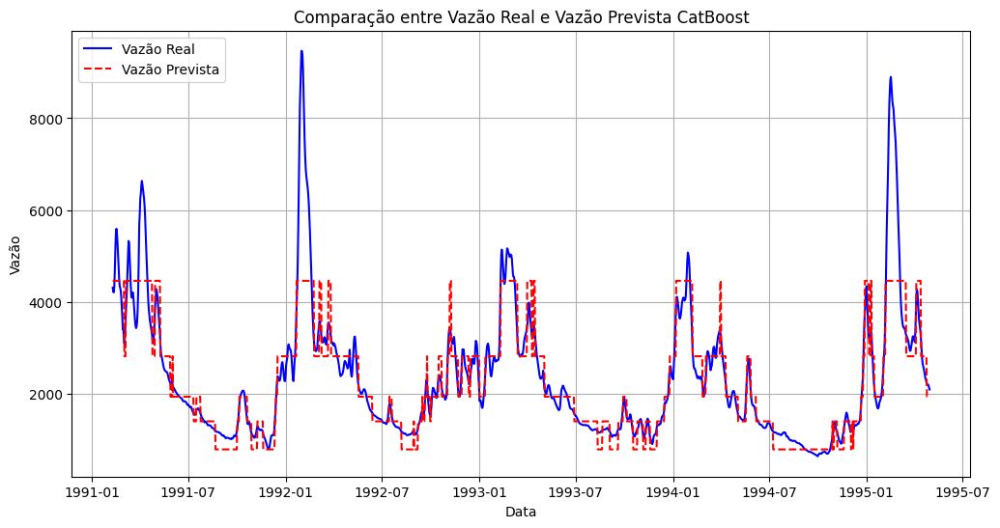

In [ ]:
parametros_CB = {
    'iterations': 1000,
    'learning_rate': 0.03,
    'depth': 6,
    'l2_leaf_reg': 3.0,
    'bootstrap_type': 'Bayesian',
    'bagging_temperature': 1.0,
    'random_strength': 1.0,
    'border_count': 254,
    'feature_border_type': 'GreedyLogSum',
    'verbose': 0,
    'random_seed': 42,
    'od_type': 'IncToDec',
    'od_wait': 20,
    'thread_count': -1,
    'class_weights': None,
    'allow_writing_files': False
}

dados_modelo_CB = rodar_catboost(dados_entrada_modelo, parametros_CB)
df_CatBoost = plotar_resultados(
    dados_cat,
    dados_entrada_modelo,
    dados_modelo_CB,
    plot_interativo=False,
    nome_modelo='CatBoost',
    salvar_resultados=True,
    salvar_figura=True
)

## 3.4 Diagnóstico de overfitting

Compara a acurácia de treino vs. teste de todos os modelos treinados e
classifica o risco de overfitting de cada um.

In [ ]:
# Garante que o Gaussian Naive Bayes seja treinado caso tenha sido pulado anteriormente
if 'dados_modelo_GNB' not in globals():
    print("Treinando Gaussian Naive Bayes para o diagnóstico...")
    parametros_GNB = {'priors': None, 'var_smoothing': 1e-9}
    dados_modelo_GNB = rodar_gaussian_nb(dados_entrada_modelo, parametros_GNB)

lista_todos_modelos = [
    {'nome': 'Random Forest', 'dados_modelo': dados_modelo_RF},
    {'nome': 'Decision Tree', 'dados_modelo': dados_modelo_tree},
    {'nome': 'Gradient Boost', 'dados_modelo': dados_modelo_GB},
    {'nome': 'Histo. G. Boost', 'dados_modelo': dados_modelo_HGB},
    {'nome': 'MLP Classifier', 'dados_modelo': dados_modelo_MLP},
    {'nome': 'Extra Trees', 'dados_modelo': dados_modelo_ET},
    {'nome': 'SVC', 'dados_modelo': dados_modelo_SVC},
    {'nome': 'KNN', 'dados_modelo': dados_modelo_KNN},
    {'nome': 'Gaussian NB', 'dados_modelo': dados_modelo_GNB},
    {'nome': 'Logistic Regression', 'dados_modelo': dados_modelo_LR},
    {'nome': 'Linear SVC', 'dados_modelo': dados_modelo_LSVC},
    {'nome': 'Ridge Classifier', 'dados_modelo': dados_modelo_Ridge},
    {'nome': 'Perceptron', 'dados_modelo': dados_modelo_Perceptron},
    {'nome': 'QDA', 'dados_modelo': dados_modelo_QDA},
    {'nome': 'LDA', 'dados_modelo': dados_modelo_LDA},
    {'nome': 'XGBoost', 'dados_modelo': dados_modelo_XGB},
    {'nome': 'LightGBM', 'dados_modelo': dados_modelo_LGB},
    {'nome': 'CatBoost', 'dados_modelo': dados_modelo_CB}
]

df_diagnostico_geral = funcao_diagnostico_overfitting(lista_todos_modelos, dados_entrada_modelo)
df_diagnostico_geral.sort_values(by='Acurácia Teste', ascending=False)

Gerando Diagnóstico de Overfitting...
----------------------------------------
+---------------------+-------------------+------------------+-------------+----------------+
| Modelo              |   Acurácia Treino |   Acurácia Teste |   Diferença | Diagnóstico    |
+=====================+===================+==================+=============+================+
| Random Forest       |            0.9814 |           0.9261 |      0.0553 | Risco Moderado |
+---------------------+-------------------+------------------+-------------+----------------+
| Decision Tree       |            0.9608 |           0.9034 |      0.0574 | Risco Moderado |
+---------------------+-------------------+------------------+-------------+----------------+
| Gradient Boost      |            0.9558 |           0.9255 |      0.0303 | Baixo Risco    |
+---------------------+-------------------+------------------+-------------+----------------+
| Histo. G. Boost     |            0.935  |           0.9294 |      0.0056 

,Modelo,Acurácia Treino,Acurácia Teste,Diferença,Diagnóstico
14,LDA,0.9352,0.9300,0.0052,Baixo Risco
3,Histo. G. Boost,0.9350,0.9294,0.0056,Baixo Risco
17,CatBoost,0.9591,0.9294,0.0298,Baixo Risco
9,Logistic Regression,0.9372,0.9281,0.0091,Baixo Risco
15,XGBoost,0.9600,0.9261,0.0339,Baixo Risco
0,Random Forest,0.9814,0.9261,0.0553,Risco Moderado
2,Gradient Boost,0.9558,0.9255,0.0303,Baixo Risco
5,Extra Trees,0.9814,0.9222,0.0591,Risco Moderado
16,LightGBM,0.9775,0.9196,0.0579,Risco Moderado
6,SVC,0.9461,0.9132,0.0329,Baixo Risco


## 3.5 Curvas de validação (opcional)

Para os modelos/hiperparâmetros mais relevantes, plota a curva de
treino x validação cruzada -- ajuda a visualizar overfitting/underfitting
em função do hiperparâmetro escolhido.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    ExtraTreesClassifier
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
import numpy as np

X_treino_cv = dados_entrada_modelo['X_treino']
y_treino_cv = dados_entrada_modelo['y_treino']

print(f"Dados de Treino (para CV) prontos: X shape {X_treino_cv.shape}, y shape {y_treino_cv.shape}")

Dados de Treino (para CV) prontos: X shape (3598, 20), y shape (3598, 1)



Curva de Validação: Decision Tree (vs. 'max_depth')
Calculando Curva de Validação para 'max_depth'...

Resultados da Curva de Validação:
+-------------------+---------------------+------------------------+
|   Valor max_depth | Média Treino        | Média Validação (CV)   |
+===================+=====================+========================+
|                 2 | 0.7015 (+/- 0.0006) | 0.7015 (+/- 0.0024)    |
+-------------------+---------------------+------------------------+
|                 4 | 0.9374 (+/- 0.0015) | 0.9302 (+/- 0.0050)    |
+-------------------+---------------------+------------------------+
|                 6 | 0.9446 (+/- 0.0016) | 0.9250 (+/- 0.0103)    |
+-------------------+---------------------+------------------------+
|                 8 | 0.9548 (+/- 0.0031) | 0.9169 (+/- 0.0135)    |
+-------------------+---------------------+------------------------+
|                10 | 0.9640 (+/- 0.0012) | 0.9058 (+/- 0.0131)    |
+-------------------+-------------

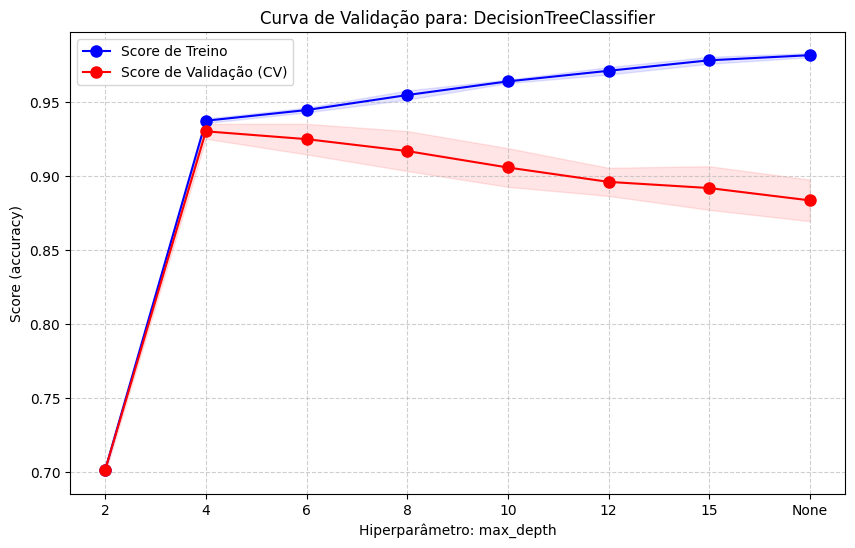

In [ ]:
print("\nCurva de Validação: Decision Tree (vs. 'max_depth')")
plotar_curva_validacao(
    estimator=DecisionTreeClassifier(criterion='gini', random_state=42),
    param_name='max_depth',
    param_range=[2, 4, 6, 8, 10, 12, 15, None],
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: Random Forest (vs. 'max_depth')
Calculando Curva de Validação para 'max_depth'...

Resultados da Curva de Validação:
+-------------------+---------------------+------------------------+
|   Valor max_depth | Média Treino        | Média Validação (CV)   |
+===================+=====================+========================+
|                 2 | 0.6980 (+/- 0.0108) | 0.6893 (+/- 0.0201)    |
+-------------------+---------------------+------------------------+
|                 5 | 0.9323 (+/- 0.0035) | 0.9213 (+/- 0.0093)    |
+-------------------+---------------------+------------------------+
|                 8 | 0.9487 (+/- 0.0014) | 0.9313 (+/- 0.0073)    |
+-------------------+---------------------+------------------------+
|                10 | 0.9616 (+/- 0.0006) | 0.9316 (+/- 0.0074)    |
+-------------------+---------------------+------------------------+
|                15 | 0.9785 (+/- 0.0014) | 0.9305 (+/- 0.0090)    |
+-------------------+-------------

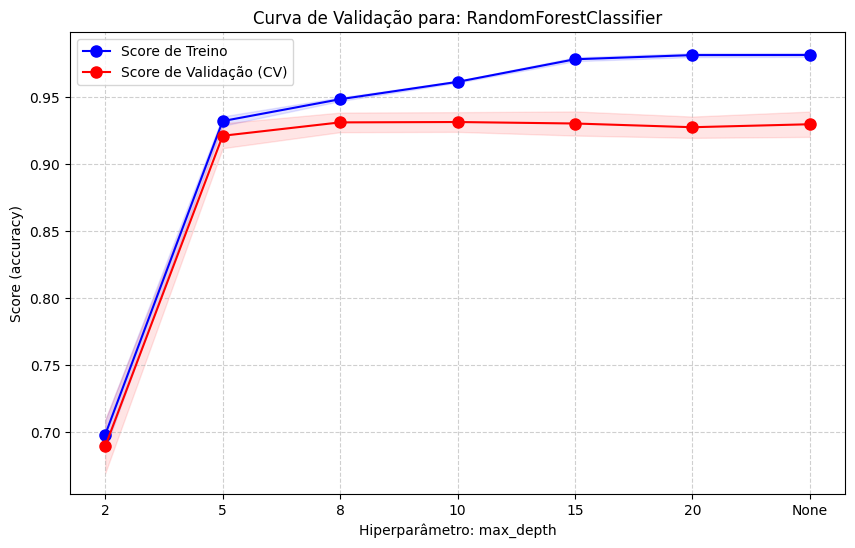

In [ ]:
print("\nCurva de Validação: Random Forest (vs. 'max_depth')")
plotar_curva_validacao(
    estimator=RandomForestClassifier(n_estimators=100, criterion='gini', random_state=42, n_jobs=-1),
    param_name='max_depth',
    param_range=[2, 5, 8, 10, 15, 20, None],
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: Extra Trees (vs. 'max_depth')
Calculando Curva de Validação para 'max_depth'...

Resultados da Curva de Validação:
+-------------------+---------------------+------------------------+
|   Valor max_depth | Média Treino        | Média Validação (CV)   |
+===================+=====================+========================+
|                 2 | 0.8424 (+/- 0.0078) | 0.8360 (+/- 0.0496)    |
+-------------------+---------------------+------------------------+
|                 5 | 0.9341 (+/- 0.0025) | 0.9280 (+/- 0.0117)    |
+-------------------+---------------------+------------------------+
|                 8 | 0.9482 (+/- 0.0014) | 0.9344 (+/- 0.0075)    |
+-------------------+---------------------+------------------------+
|                10 | 0.9587 (+/- 0.0013) | 0.9325 (+/- 0.0070)    |
+-------------------+---------------------+------------------------+
|                15 | 0.9767 (+/- 0.0015) | 0.9322 (+/- 0.0096)    |
+-------------------+---------------

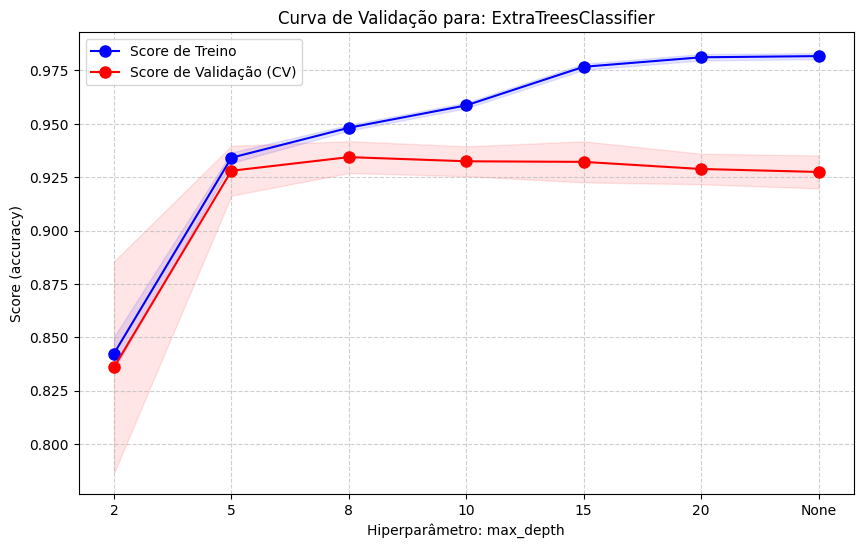

In [ ]:
print("\nCurva de Validação: Extra Trees (vs. 'max_depth')")
plotar_curva_validacao(
    estimator=ExtraTreesClassifier(n_estimators=100, criterion='gini', random_state=42, n_jobs=-1),
    param_name='max_depth',
    param_range=[2, 5, 8, 10, 15, 20, None],
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: Gradient Boosting (vs. 'max_depth')
Calculando Curva de Validação para 'max_depth'...

Resultados da Curva de Validação:
+-------------------+---------------------+------------------------+
|   Valor max_depth | Média Treino        | Média Validação (CV)   |
+===================+=====================+========================+
|                 2 | 0.9439 (+/- 0.0016) | 0.9327 (+/- 0.0095)    |
+-------------------+---------------------+------------------------+
|                 3 | 0.9592 (+/- 0.0020) | 0.9308 (+/- 0.0082)    |
+-------------------+---------------------+------------------------+
|                 4 | 0.9735 (+/- 0.0014) | 0.9230 (+/- 0.0050)    |
+-------------------+---------------------+------------------------+
|                 5 | 0.9810 (+/- 0.0013) | 0.9238 (+/- 0.0109)    |
+-------------------+---------------------+------------------------+
|                 7 | 0.9817 (+/- 0.0014) | 0.9219 (+/- 0.0098)    |
+-------------------+---------

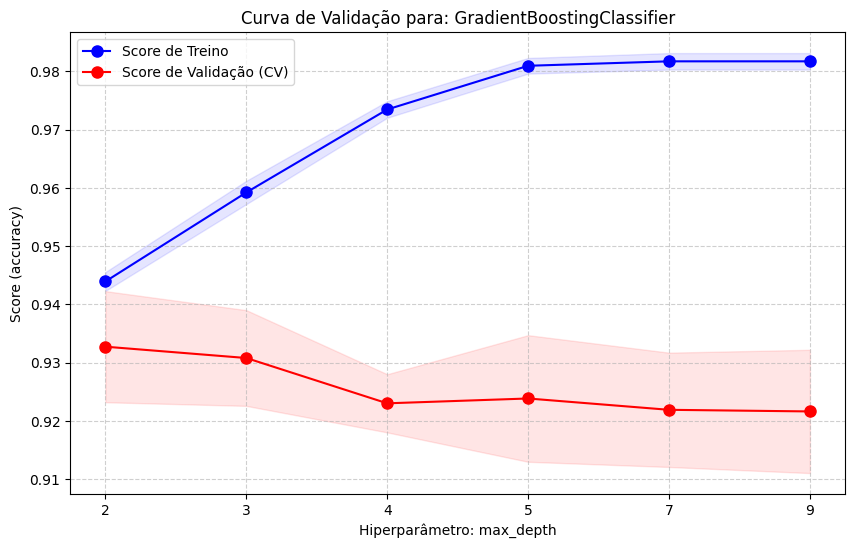

In [ ]:
print("\nCurva de Validação: Gradient Boosting (vs. 'max_depth')")
plotar_curva_validacao(
    estimator=GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    param_name='max_depth',
    param_range=[2, 3, 4, 5, 7, 9],
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: Hist Gradient Boosting (vs. 'max_leaf_nodes')
Calculando Curva de Validação para 'max_leaf_nodes'...

Resultados da Curva de Validação:
+------------------------+---------------------+------------------------+
|   Valor max_leaf_nodes | Média Treino        | Média Validação (CV)   |
+========================+=====================+========================+
|                      5 | 0.9555 (+/- 0.0025) | 0.9300 (+/- 0.0074)    |
+------------------------+---------------------+------------------------+
|                     10 | 0.9744 (+/- 0.0017) | 0.9247 (+/- 0.0086)    |
+------------------------+---------------------+------------------------+
|                     20 | 0.9814 (+/- 0.0014) | 0.9219 (+/- 0.0092)    |
+------------------------+---------------------+------------------------+
|                     31 | 0.9817 (+/- 0.0014) | 0.9199 (+/- 0.0099)    |
+------------------------+---------------------+------------------------+
|                     40 | 0.

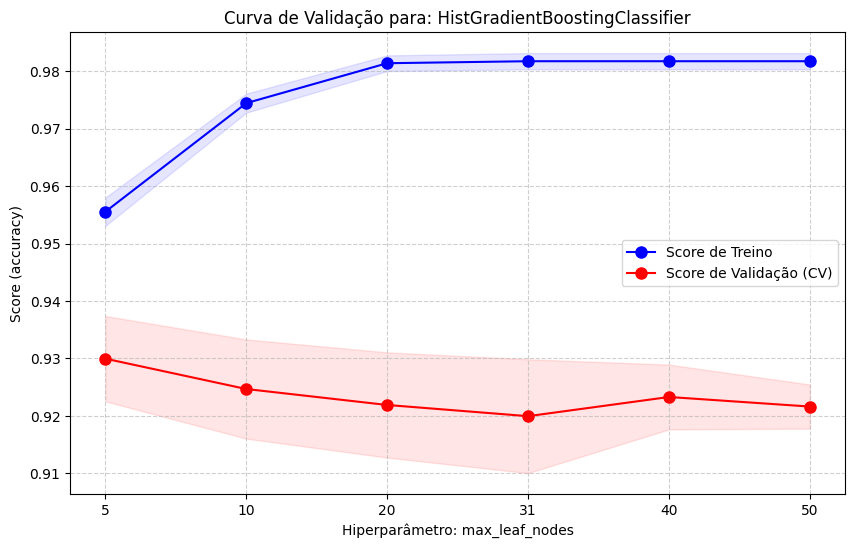

In [ ]:
print("\nCurva de Validação: Hist Gradient Boosting (vs. 'max_leaf_nodes')")
plotar_curva_validacao(
    estimator=HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42),
    param_name='max_leaf_nodes',
    param_range=[5, 10, 20, 31, 40, 50],
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: XGBoost (vs. 'max_depth')
Calculando Curva de Validação para 'max_depth'...

Resultados da Curva de Validação:
+-------------------+---------------------+------------------------+
|   Valor max_depth | Média Treino        | Média Validação (CV)   |
+===================+=====================+========================+
|                 2 | 0.9354 (+/- 0.0019) | 0.9347 (+/- 0.0077)    |
+-------------------+---------------------+------------------------+
|                 3 | 0.9407 (+/- 0.0018) | 0.9341 (+/- 0.0077)    |
+-------------------+---------------------+------------------------+
|                 4 | 0.9493 (+/- 0.0012) | 0.9300 (+/- 0.0071)    |
+-------------------+---------------------+------------------------+
|                 5 | 0.9605 (+/- 0.0019) | 0.9302 (+/- 0.0082)    |
+-------------------+---------------------+------------------------+
|                 6 | 0.9698 (+/- 0.0008) | 0.9300 (+/- 0.0099)    |
+-------------------+-------------------

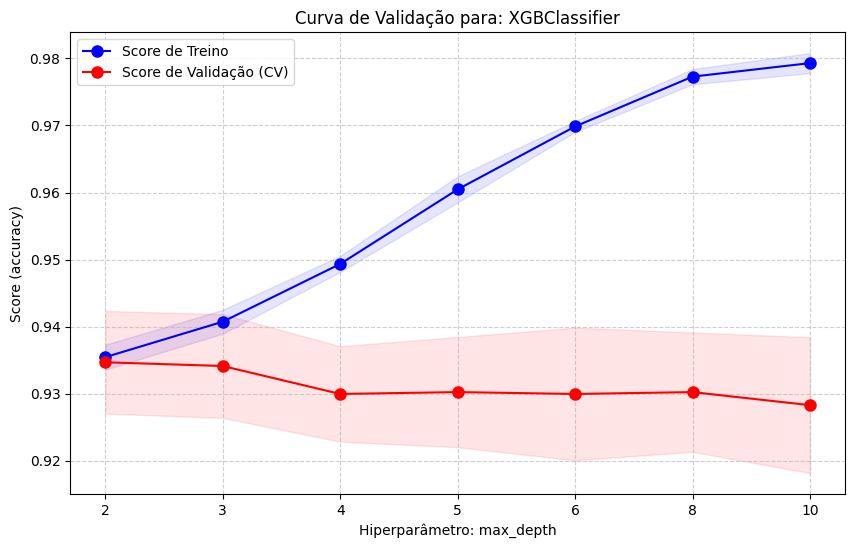

In [ ]:
print("\nCurva de Validação: XGBoost (vs. 'max_depth')")
plotar_curva_validacao(
    estimator=XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, eval_metric='mlogloss', n_jobs=-1),
    param_name='max_depth',
    param_range=[2, 3, 4, 5, 6, 8, 10],
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: LightGBM (vs. 'num_leaves')
Calculando Curva de Validação para 'num_leaves'...

Resultados da Curva de Validação:
+--------------------+---------------------+------------------------+
|   Valor num_leaves | Média Treino        | Média Validação (CV)   |
+====================+=====================+========================+
|                  5 | 0.9529 (+/- 0.0021) | 0.9313 (+/- 0.0078)    |
+--------------------+---------------------+------------------------+
|                 10 | 0.9716 (+/- 0.0014) | 0.9266 (+/- 0.0107)    |
+--------------------+---------------------+------------------------+
|                 20 | 0.9811 (+/- 0.0012) | 0.9236 (+/- 0.0076)    |
+--------------------+---------------------+------------------------+
|                 31 | 0.9817 (+/- 0.0014) | 0.9247 (+/- 0.0080)    |
+--------------------+---------------------+------------------------+
|                 40 | 0.9817 (+/- 0.0014) | 0.9225 (+/- 0.0093)    |
+--------------------+---

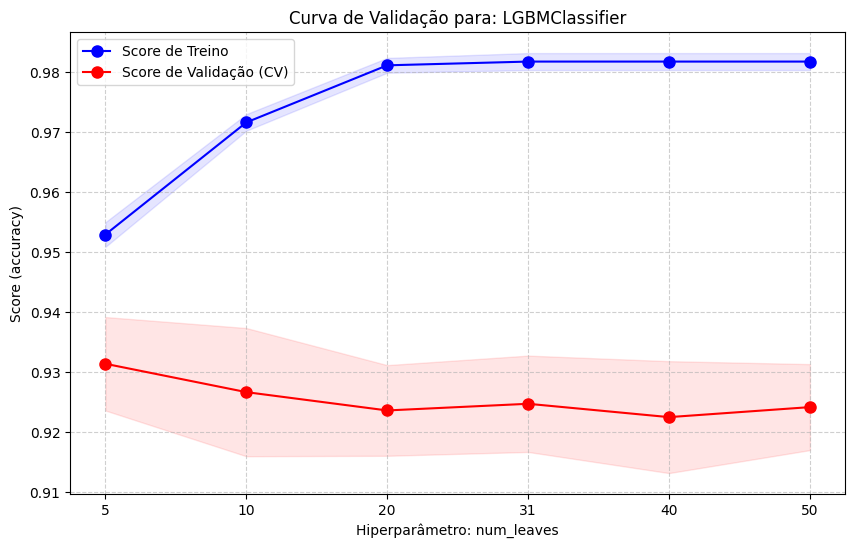

In [ ]:
print("\nCurva de Validação: LightGBM (vs. 'num_leaves')")
plotar_curva_validacao(
    estimator=LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1),
    param_name='num_leaves',
    param_range=[5, 10, 20, 31, 40, 50],
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: CatBoost (vs. 'depth')
Calculando Curva de Validação para 'depth'...

Resultados da Curva de Validação:
+---------------+---------------------+------------------------+
|   Valor depth | Média Treino        | Média Validação (CV)   |
+===============+=====================+========================+
|             3 | 0.9354 (+/- 0.0018) | 0.9350 (+/- 0.0079)    |
+---------------+---------------------+------------------------+
|             4 | 0.9364 (+/- 0.0015) | 0.9347 (+/- 0.0077)    |
+---------------+---------------------+------------------------+
|             5 | 0.9376 (+/- 0.0016) | 0.9347 (+/- 0.0077)    |
+---------------+---------------------+------------------------+
|             6 | 0.9398 (+/- 0.0017) | 0.9344 (+/- 0.0074)    |
+---------------+---------------------+------------------------+
|             8 | 0.9463 (+/- 0.0013) | 0.9333 (+/- 0.0069)    |
+---------------+---------------------+------------------------+
|            10 | 0.9533 (+/- 

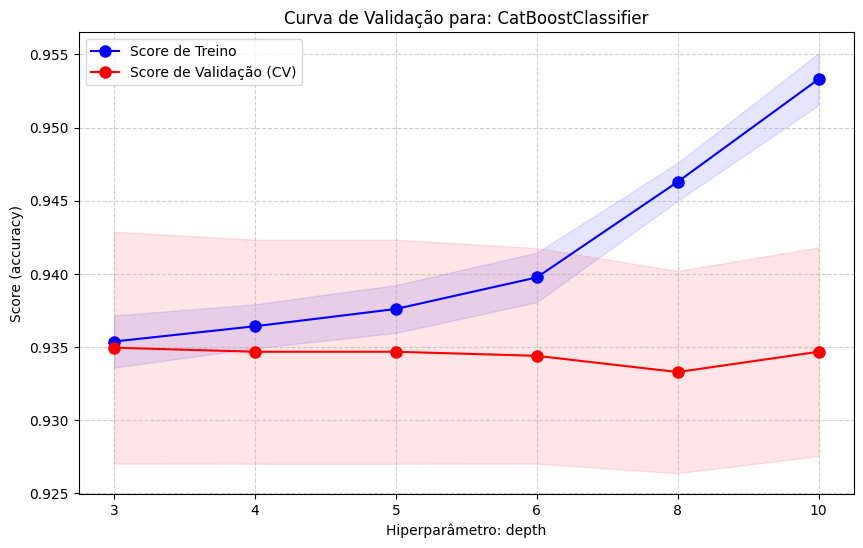

In [ ]:
print("\nCurva de Validação: CatBoost (vs. 'depth')")
plotar_curva_validacao(
    estimator=CatBoostClassifier(iterations=100, learning_rate=0.1, random_seed=42, verbose=0, allow_writing_files=False),
    param_name='depth',
    param_range=[3, 4, 5, 6, 8, 10],
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: SVC (vs. 'C')
Calculando Curva de Validação para 'C'...

Resultados da Curva de Validação:
+-----------+---------------------+------------------------+
|   Valor C | Média Treino        | Média Validação (CV)   |
+===========+=====================+========================+
|      0.01 | 0.4644 (+/- 0.0054) | 0.4636 (+/- 0.0225)    |
+-----------+---------------------+------------------------+
|      0.1  | 0.7976 (+/- 0.0117) | 0.7804 (+/- 0.0552)    |
+-----------+---------------------+------------------------+
|      1    | 0.9465 (+/- 0.0005) | 0.9147 (+/- 0.0241)    |
+-----------+---------------------+------------------------+
|     10    | 0.9657 (+/- 0.0015) | 0.9158 (+/- 0.0171)    |
+-----------+---------------------+------------------------+
|    100    | 0.9777 (+/- 0.0018) | 0.8808 (+/- 0.0232)    |
+-----------+---------------------+------------------------+


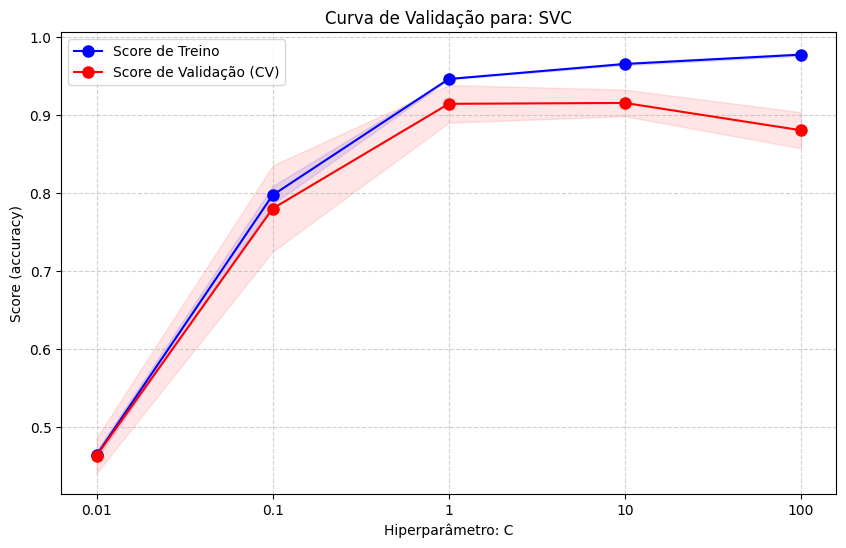

In [ ]:
print("\nCurva de Validação: SVC (vs. 'C')")
plotar_curva_validacao(
    estimator=SVC(kernel='rbf', gamma='scale', random_state=42),
    param_name='C',
    param_range=[0.01, 0.1, 1, 10, 100],
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: KNN (vs. 'n_neighbors')
Calculando Curva de Validação para 'n_neighbors'...

Resultados da Curva de Validação:
+---------------------+---------------------+------------------------+
|   Valor n_neighbors | Média Treino        | Média Validação (CV)   |
+=====================+=====================+========================+
|                   1 | 0.9351 (+/- 0.0394) | 0.6826 (+/- 0.0419)    |
+---------------------+---------------------+------------------------+
|                   3 | 0.8416 (+/- 0.0300) | 0.7157 (+/- 0.0397)    |
+---------------------+---------------------+------------------------+
|                   5 | 0.8375 (+/- 0.0084) | 0.7426 (+/- 0.0442)    |
+---------------------+---------------------+------------------------+
|                   7 | 0.8294 (+/- 0.0076) | 0.7451 (+/- 0.0497)    |
+---------------------+---------------------+------------------------+
|                  10 | 0.8166 (+/- 0.0094) | 0.7512 (+/- 0.0515)    |
+---------------

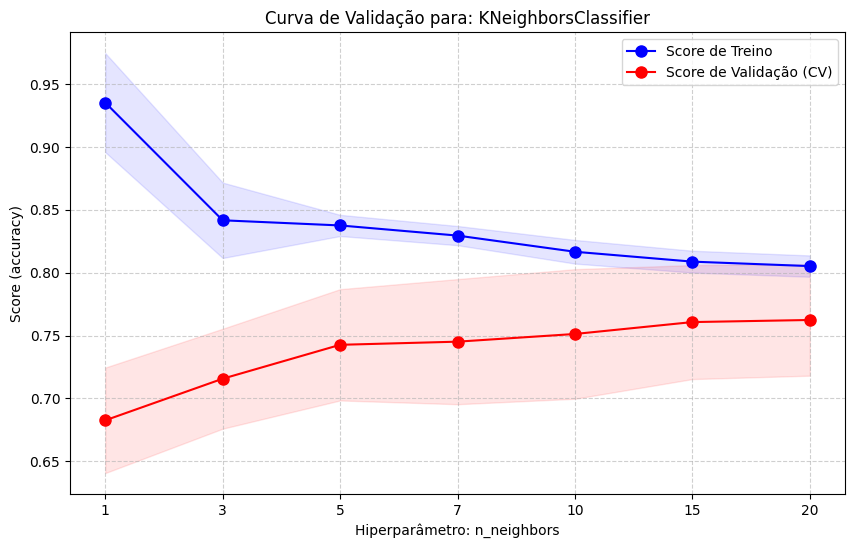

In [ ]:
print("\nCurva de Validação: KNN (vs. 'n_neighbors')")
plotar_curva_validacao(
    estimator=KNeighborsClassifier(n_jobs=-1),
    param_name='n_neighbors',
    param_range=[1, 3, 5, 7, 10, 15, 20],
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: MLP Classifier (vs. 'alpha')
Calculando Curva de Validação para 'alpha'...

Resultados da Curva de Validação:
+---------------+---------------------+------------------------+
|   Valor alpha | Média Treino        | Média Validação (CV)   |
+===============+=====================+========================+
|   1e-05       | 0.9766 (+/- 0.0020) | 0.8819 (+/- 0.0192)    |
+---------------+---------------------+------------------------+
|   0.000158489 | 0.9764 (+/- 0.0021) | 0.8844 (+/- 0.0182)    |
+---------------+---------------------+------------------------+
|   0.00251189  | 0.9769 (+/- 0.0017) | 0.8852 (+/- 0.0170)    |
+---------------+---------------------+------------------------+
|   0.0398107   | 0.9721 (+/- 0.0018) | 0.9030 (+/- 0.0112)    |
+---------------+---------------------+------------------------+
|   0.630957    | 0.9420 (+/- 0.0020) | 0.9283 (+/- 0.0095)    |
+---------------+---------------------+------------------------+
|  10           | 0.9177

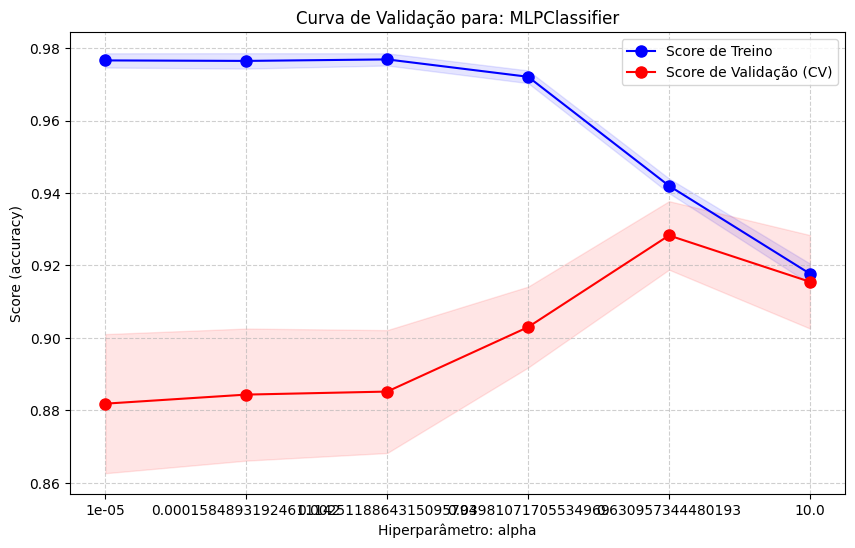

In [ ]:
print("\nCurva de Validação: MLP Classifier (vs. 'alpha')")
plotar_curva_validacao(
    estimator=MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42),
    param_name='alpha',
    param_range=np.logspace(-5, 1, 6),
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: Logistic Regression (vs. 'C')
Calculando Curva de Validação para 'C'...

Resultados da Curva de Validação:
+-----------+---------------------+------------------------+
|   Valor C | Média Treino        | Média Validação (CV)   |
+===========+=====================+========================+
|     0.001 | 0.5697 (+/- 0.0456) | 0.5553 (+/- 0.0475)    |
+-----------+---------------------+------------------------+
|     0.01  | 0.8758 (+/- 0.0088) | 0.8424 (+/- 0.0367)    |
+-----------+---------------------+------------------------+
|     0.1   | 0.9288 (+/- 0.0023) | 0.9225 (+/- 0.0096)    |
+-----------+---------------------+------------------------+
|     1     | 0.9377 (+/- 0.0016) | 0.9330 (+/- 0.0083)    |
+-----------+---------------------+------------------------+
|    10     | 0.9382 (+/- 0.0016) | 0.9325 (+/- 0.0089)    |
+-----------+---------------------+------------------------+
|   100     | 0.9382 (+/- 0.0017) | 0.9316 (+/- 0.0093)    |
+-----------+-----

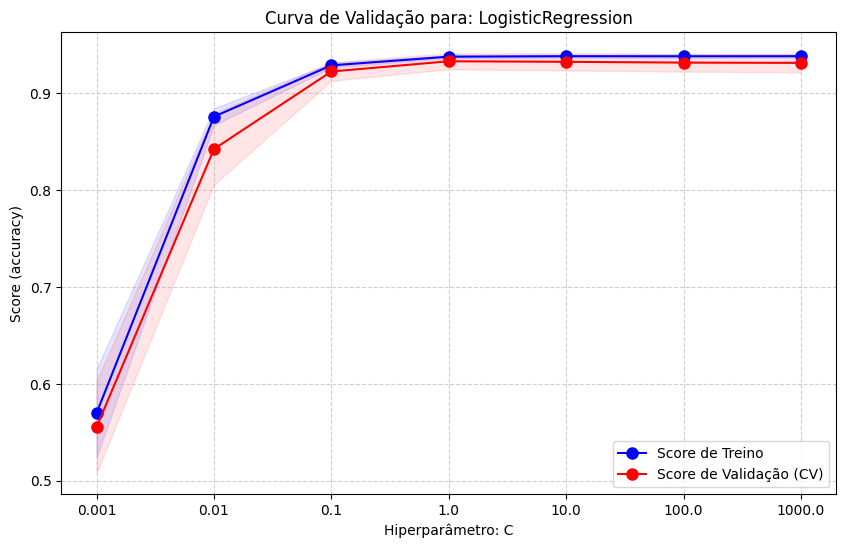

In [ ]:
print("\nCurva de Validação: Logistic Regression (vs. 'C')")
plotar_curva_validacao(
    estimator=LogisticRegression(max_iter=2000, random_state=42),
    param_name='C',
    param_range=np.logspace(-3, 3, 7),
    X=X_treino_cv, y=y_treino_cv
)


Curva de Validação: QDA (vs. 'reg_param')
Calculando Curva de Validação para 'reg_param'...

Resultados da Curva de Validação:
+-------------------+---------------------+------------------------+
|   Valor reg_param | Média Treino        | Média Validação (CV)   |
+===================+=====================+========================+
|               0   | 0.1009 (+/- 0.0002) | 0.1009 (+/- 0.0006)    |
+-------------------+---------------------+------------------------+
|               0.1 | 0.8624 (+/- 0.0215) | 0.8043 (+/- 0.0347)    |
+-------------------+---------------------+------------------------+
|               0.3 | 0.8043 (+/- 0.0257) | 0.7368 (+/- 0.0448)    |
+-------------------+---------------------+------------------------+
|               0.5 | 0.7668 (+/- 0.0268) | 0.7087 (+/- 0.0457)    |
+-------------------+---------------------+------------------------+
|               0.7 | 0.7725 (+/- 0.0266) | 0.7298 (+/- 0.0409)    |
+-------------------+---------------------+-

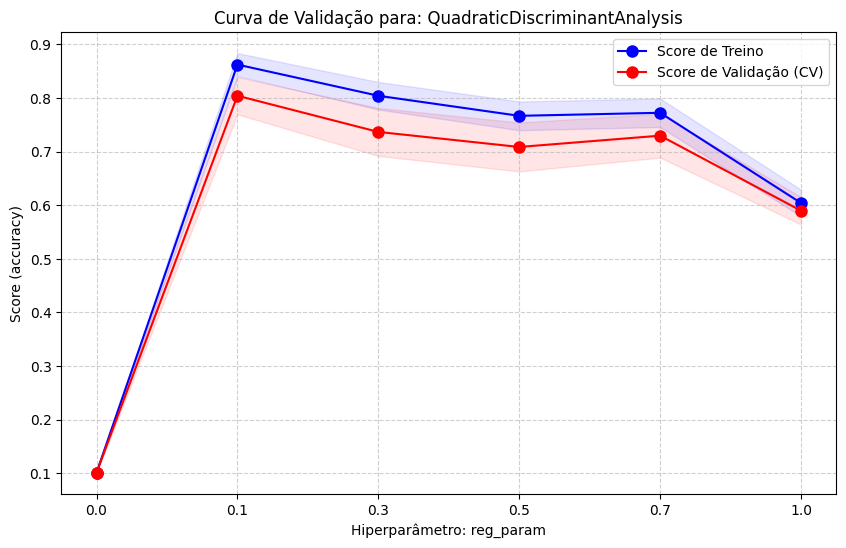

In [ ]:
print("\nCurva de Validação: QDA (vs. 'reg_param')")
plotar_curva_validacao(
    estimator=QuadraticDiscriminantAnalysis(),
    param_name='reg_param',
    param_range=[0.0, 0.1, 0.3, 0.5, 0.7, 1.0],
    X=X_treino_cv, y=y_treino_cv
)

Fim do pipeline. 🎉

### Geração do Relatório Executivo no Google Drive (Formato Google Docs / .docx)

Esta célula instala a biblioteca `python-docx` e compila todos os resultados estatísticos, agrupamentos e métricas dos 18 modelos gerados no pipeline em um documento técnico estruturado na pasta do seu projeto.

In [ ]:
%pip install -q python-docx

In [ ]:
import os
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.oxml import OxmlElement
from docx.oxml.ns import qn

def set_cell_background(cell, fill_hex):
    tcPr = cell._tc.get_or_add_tcPr()
    shd = OxmlElement('w:shd')
    shd.set(qn('w:val'), 'clear')
    shd.set(qn('w:color'), 'auto')
    shd.set(qn('w:fill'), fill_hex)
    tcPr.append(shd)

doc = Document()

# Configuração de Estilos de Fonte
style = doc.styles['Normal']
font = style.font
font.name = 'Arial'
font.size = Pt(11)

# Título Principal
title_p = doc.add_paragraph()
title_p.alignment = WD_ALIGN_PARAGRAPH.CENTER
title_run = title_p.add_run("RELATÓRIO TÉCNICO: PIPELINE DE MODELAGEM CHUVA-VAZÃO")
title_run.bold = True
title_run.font.size = Pt(18)
title_run.font.color.rgb = None

sub_p = doc.add_paragraph()
sub_p.alignment = WD_ALIGN_PARAGRAPH.CENTER
sub_run = sub_p.add_run("Análise Exploratória, Agrupamento Espacial e Avaliação de 18 Modelos de Classificação")
sub_run.italic = True
sub_run.font.size = Pt(12)

doc.add_paragraph("\nEste relatório consolida os resultados obtidos em todas as fases do pipeline chuva-vazão, abrangendo o tratamento de dados das estações pluviométricas da ANA, a análise de agrupamento hierárquico, a categorização em percentis e o benchmark de performance com diagnóstico de overfitting para 18 modelos de aprendizado de máquina.")

# Seção 1
h1 = doc.add_heading(level=1)
h1_run = h1.add_run("1. Base de Dados e Pré-Tratamento")
h1_run.font.size = Pt(14)
h1_run.font.color.rgb = None

doc.add_paragraph(f"A base de dados inicial foi limpa e filtrada considerando uma tolerância estrita de falhas. Foram selecionadas {len(df_datamining_no_NA.columns)-1} estações pluviométricas de alta consistência no intervalo de 1981 a 1995. Os dados ausentes remanescentes foram preenchidos de forma robusta por meio de interpolação espacial baseada nas 3 estações vizinhas mais próximas.")

# Seção 2
h2 = doc.add_heading(level=1)
h2_run = h2.add_run("2. Análise Multivariada e Agrupamento Espacial (Clustering)")
h2_run.font.size = Pt(14)

doc.add_paragraph("Para mitigar a redundância espacial e a alta dimensionalidade dos dados de chuva, aplicou-se o algoritmo de Agrupamento Hierárquico de Ward com base na matriz de dissimilaridade das séries. As estações foram agregadas em 6 clusters representativos:")

clusters_info = [
    ("Cluster 1", "2148015, 2148012, 2148017", "Região de cabeceira / alta precipitação"),
    ("Cluster 2", "2048028, 2048026, 2048029, 2049055, 2148005", "Região intermediária leste"),
    ("Cluster 3", "1949005", "Estação isolada representativa do setor norte"),
    ("Cluster 4", "1949004", "Estação isolada representativa do setor nordeste"),
    ("Cluster 5", "2049010, 2049032, 2050004, 2050009", "Região ocidental da bacia"),
    ("Cluster 6", "1949001, 2049003, 2049006, 2049009, 2049015", "Região central / calha principal")
]

table_cl = doc.add_table(rows=1, cols=3)
table_cl.style = 'Light Shading Accent 1'
hdr_cells = table_cl.rows[0].cells
hdr_cells[0].text = 'Cluster'
hdr_cells[1].text = 'Estações Integrantes'
hdr_cells[2].text = 'Representação Espacial'

for cl, est, rep in clusters_info:
    row_cells = table_cl.add_row().cells
    row_cells[0].text = cl
    row_cells[1].text = est
    row_cells[2].text = rep

# Seção 3
h3 = doc.add_heading(level=1)
h3_run = h3.add_run("3. Benchmark e Diagnóstico de Overfitting de Classificadores")
h3_run.font.size = Pt(14)

doc.add_paragraph("A previsão numérica de vazão (Q) foi reformulada como uma tarefa de classificação por faixas de percentis (Muito Baixa, Baixa, Média, Alta, Muito Alta). Abaixo apresenta-se a tabela consolidada de acurácia em treino e teste para cada um dos 18 modelos ordenados do melhor para o pior desempenho em dados não vistos (Teste):")

# Tabela de Performance de Modelos
table_m = doc.add_table(rows=1, cols=5)
table_m.style = 'Table Grid'
hdr_m = table_m.rows[0].cells
hdr_m[0].text = 'Classificador'
hdr_m[1].text = 'Acurácia Treino'
hdr_m[2].text = 'Acurácia Teste'
hdr_m[3].text = 'Diferença'
hdr_m[4].text = 'Diagnóstico de Risco'

for cell in hdr_m:
    set_cell_background(cell, "1F4E78")
    for p in cell.paragraphs:
        for r in p.runs:
            r.font.bold = True
            r.font.color.rgb = None

# Ordena o dataframe para o relatório
df_rel_sorted = df_diagnostico_geral.sort_values(by='Acurácia Teste', ascending=False)
for _, row in df_rel_sorted.iterrows():
    row_cells = table_m.add_row().cells
    row_cells[0].text = str(row['Modelo'])
    row_cells[1].text = f"{row['Acurácia Treino']:.4f}"
    row_cells[2].text = f"{row['Acurácia Teste']:.4f}"
    row_cells[3].text = f"{row['Diferença']:.4f}"
    row_cells[4].text = str(row['Diagnóstico'])

    # Destaque visual para o risco
    if "Moderado" in str(row['Diagnóstico']):
        set_cell_background(row_cells[4], "FFF2CC")
    elif "Baixo" in str(row['Diagnóstico']):
        set_cell_background(row_cells[4], "E2EFDA")

# Conclusão
h4 = doc.add_heading(level=1)
h4_run = h4.add_run("4. Recomendações e Próximos Passos")
h4_run.font.size = Pt(14)

doc.add_paragraph("1. Os modelos baseados em Discriminantes Lineares (LDA) e Gradient Boosting em Histograma (HistGB) alcançaram os melhores resultados de generalização, com acurácias de teste superiores a 92.9% e excelente estabilidade (Baixo Risco).\n"
                  "2. Modelos complexos como Random Forest e Extra Trees, embora potentes, demonstraram overfitting moderado e devem passar por ajustes de hiperparâmetros (como profundidade máxima e número mínimo de amostras por folha).\n"
                  "3. Sugere-se avançar com as curvas de validação de hiperparâmetros geradas no final do pipeline para refinar o LDA e o CatBoost antes da colocação em produção.")

# Salva o arquivo no diretório do projeto no Drive
nome_documento = "Relatorio_Pipeline_Chuva_Vazao.docx"
doc.save(nome_documento)
print(f"Sucesso! O relatório técnico detalhado foi gerado e salvo como: {nome_documento}")


Sucesso! O relatório técnico detalhado foi gerado e salvo como: Relatorio_Pipeline_Chuva_Vazao.docx
